# Early Detection of the Risk of Diabetes Using Calibrated Explanations and Explainable Artificial Intelligence (XAI) with Philippine Data

## Authors
- James Angelo R. Dela Cruz
- Adviser: Geoffrey A. Solano
- Department of Physical Sciences and Mathematics, University of the Philippines Manila
- Special Problem (CMSC 199), Bachelor of Science in Computer Science, June 2026

## Purpose
This notebook documents the V2 pipeline of the special problem. It predicts elevated fasting blood sugar (FBS) risk from the 2018-2021 Philippine Expanded National Nutrition Survey (ENNS) and explains the predictions with calibrated, uncertainty-aware explanations. It covers data loading and integration, preprocessing, exploratory data analysis, model training and evaluation, probability calibration, and explainability (SHAP, LIME and Calibrated Explanations).

| Component | Configuration |
|---|---|
| Target | `diabetes` = 1 if FBS >= 100 mg/dL (at risk), otherwise 0 |
| Population | All respondents with a recorded FBS value (no age-group filtering) |
| Data sources | Clinical, anthropometric, biochemical and socioeconomic ENNS components |
| Missing data | KNN imputation for continuous features, mode imputation for categorical features |
| Outliers | IQR capping (1.5 x IQR) |
| Scaling | StandardScaler on continuous features |
| Feature selection | Correlation filter (|r| > 0.80) |
| Class balancing | SMOTE (sampling strategy 1.0, k = 5) |
| Partitions | Stratified 70 / 15 / 15 train / validation / test |
| Models | BO-TabNet, Naive Bayes, kNN, AdaBoost, XGBoost, Random Forest, CatBoost, LightGBM, Voting and Stacking ensembles |
| Explainability | SHAP, LIME, Calibrated Explanations (Venn-Abers) |

**Dataset:** 2018-2021 Philippine Expanded National Nutrition Survey (ENNS), DOST-FNRI  
**Primary metric:** F2-Score (beta = 2, recall-weighted)  
**Random seed:** 42

## 0. Setup

Imports collected from all scripts, display helpers and run flags.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import joblib
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTETomek
import warnings
warnings.filterwarnings('ignore')
import matplotlib.ticker as mtick
import math
import time
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    fbeta_score, make_scorer
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import (
    RandomForestClassifier, VotingClassifier,
    StackingClassifier, AdaBoostClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
import torch
import optuna
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)
from scipy.optimize import minimize_scalar
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    brier_score_loss, roc_auc_score, log_loss,
    average_precision_score, f1_score, fbeta_score,
    precision_score, recall_score
)
import shap
from lime import lime_tabular
import os
import shutil
warnings.filterwarnings('ignore', message='.*deep-copy.*', category=UserWarning)
warnings.filterwarnings('ignore', message='.*CalibratedExplainer.*', category=UserWarning)
from sklearn.metrics import (
    brier_score_loss, log_loss, roc_auc_score, average_precision_score
)
try:
    from calibrated_explanations import CalibratedExplainer
    CE_AVAILABLE = True
except ImportError:
    CE_AVAILABLE = False
    print("[ERROR] calibrated-explanations not installed.")
    print("        Run: pip install calibrated-explanations")
try:
    from pytorch_tabnet.tab_model import TabNetClassifier
    TABNET_AVAILABLE = True
except ImportError:
    TABNET_AVAILABLE = False

In [2]:
from pathlib import Path
from IPython.display import display, Image

ROOT = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP")

RUN_PREPROCESSING = False   # overwrites MAIN_PREPROCESS_OUTPUT (slow: KNN imputation)
RUN_EXTRA_EDA     = False   # writes eda2_* files only
RUN_TRAINING      = False   # overwrites MAIN_MODEL_RESULTS / MAIN_TRAINED_MODELS (hours)
RUN_CALIBRATION   = False   # overwrites MAIN_CALIBRATION / MAIN_TRAINED_MODELS_CALIB
RUN_XAI           = False   # overwrites MAIN_XAI
RUN_CE            = False   # overwrites MAIN_CE_OUTPUT


def show_csv(rel, n=None):
    p = ROOT / rel
    if not p.exists():
        print(f"[missing] {rel}")
        return None
    d = pd.read_csv(p)
    display(d if n is None else d.head(n))
    return d


def show_img(rel, width=900):
    p = ROOT / rel
    if p.exists():
        display(Image(filename=str(p), width=width))
    else:
        print(f"[missing] {rel}")

---
## 1. Preprocessing building blocks (`preprocessing_pipeline_v7.py`)

Shared utilities imported by `main_preprocessing.py`: data loading and merging, special-code recoding, target creation, splitting, KNN imputation, IQR capping, scaling, correlation filtering. Only the functions that `main_preprocessing.py` imports are shown.

**Original script header**

> Preprocessing Pipeline V7 - Clean Rebuild
> 
> Fixes from V6:
> 1. Clinical as LEFT base in merge (all records have FBS)
> 2. ALL enns_year_* merge artifacts dropped
> 3. Explicit categorical list -> mode imputation (not KNN)
> 4. Special missing codes -> NaN (ever_smk=99, con_alcohol/drnk_30days=9)
> 5. Population filter via anthro_group (children 1-3, pregnant=5, lactating=6)
> 6. Minimal feature engineering: bmi, waist_hip_ratio, chol_hdl_ratio, ldl_hdl_ratio ONLY
> 7. RAW unscaled CSV exported for EDA before any scaling
> 8. Single StandardScaler on continuous features only
> 9. Correlation drop computed on train set only

#### `ConfigV7`

In [3]:
class ConfigV7:
    dataset_dir = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\DATASETS\2018-2021\MAIN DATASET")
    output_dir  = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\PREPROCESS_OUTPUT_V7")
    merge_keys  = ['hhnum', 'member_code']

    fbs_threshold     = 100  # mg/dL; FBS >= 100 = At-Risk (pre-diabetes + diabetes)
    fbs_normal_max    = 100  # used for display only

    # anthro_group: 1-3=children, 5=pregnant, 6=lactating -> exclude
    exclude_anthro_groups = [1, 2, 3, 5, 6]

    use_dietary = False  # dietary features add noise; clinical+biochem+anthrop only

    test_size    = 0.15
    val_size     = 0.15
    random_state = 42

    resampling_method         = 'none'  # 'smotetomek' | 'smote' | 'undersample' | 'none'
    smote_sampling_strategy   = 0.6
    smote_k_neighbors         = 5
    undersample_strategy      = 0.7

    optimize_knn      = True
    knn_neighbors     = 5
    knn_candidates    = [3, 5, 7, 9, 11]
    masking_fraction  = 0.10

    handle_outliers  = True
    iqr_multiplier   = 1.5

    correlation_threshold = 0.92

    # Integer-coded categoricals -> mode imputation, NO StandardScaler
    CATEGORICAL_FEATURES = [
        'currentsmoking', 'ever_smk', 'alcohol', 'con_alcohol',
        'drnk_30days', 'smoke_status', 'alcohol_status', 'binge_drink', 'pa_met',
    ]

    # Special "not applicable" codes to recode as NaN
    SPECIAL_MISSING = {
        'ever_smk':   [99],
        'con_alcohol': [9],
        'drnk_30days': [9],
    }

#### `load_and_merge`

In [4]:
def load_and_merge(config):
    print("\n" + "="*70)
    print("LOADING AND MERGING DATASETS")
    print("="*70)

    clinical = pd.read_csv(config.dataset_dir / 'data-set_clinical.csv',       low_memory=False)
    anthrop  = pd.read_csv(config.dataset_dir / 'data-set_anthrop.csv',        low_memory=False)
    biochem  = pd.read_csv(config.dataset_dir / 'data-set_biochemical.csv',    low_memory=False)
    dietary  = pd.read_csv(config.dataset_dir / 'data-set_dietary_indiv.csv',  low_memory=False)

    print(f"  Clinical : {clinical.shape}")
    print(f"  Anthrop  : {anthrop.shape}")
    print(f"  Biochem  : {biochem.shape}")
    print(f"  Dietary  : {dietary.shape}")

    # Clinical is the LEFT base -> every row has FBS
    df = clinical.merge(anthrop,  on=config.merge_keys, how='left', suffixes=('', '_anthrop'))
    df = df.merge(biochem,        on=config.merge_keys, how='left', suffixes=('', '_biochem'))
    if config.use_dietary:
        df = df.merge(dietary,    on=config.merge_keys, how='left', suffixes=('', '_dietary'))

    print(f"\n  Merged shape: {df.shape}")
    return df

#### `drop_metadata_columns`

In [5]:
def drop_metadata_columns(df):
    print("\n" + "="*70)
    print("DROPPING METADATA COLUMNS")
    print("="*70)

    # Patterns that identify non-feature columns (checked as prefix or exact)
    metadata_prefixes = [
        'regcode', 'provhuc', 'enns_year',
        'fwgti', 'rep_natl', 'rep_prov', 'ms_psucode',
        'hhnum', 'member_code',
        'ethnicity',
        'Total_Food',   # redundant sum of food groups (Total_Food and Total_Food_epwt)
        'epwt_fg',      # person-weighted food group amounts (redundant with fg* raw counts)
    ]
    # anthro_group / mos_* kept until AFTER population filtering

    to_drop = []
    for col in df.columns:
        for pat in metadata_prefixes:
            if col == pat or col.startswith(pat + '_') or col.startswith(pat):
                to_drop.append(col)
                break

    df = df.drop(columns=to_drop, errors='ignore')
    print(f"  Dropped {len(to_drop)} metadata columns -> {df.shape[1]} remaining")
    return df

#### `recode_special_missing`

In [6]:
def recode_special_missing(df, config):
    print("\n" + "="*70)
    print("RECODING SPECIAL MISSING CODES -> NaN")
    print("="*70)
    for col, bad_vals in config.SPECIAL_MISSING.items():
        if col in df.columns:
            n = df[col].isin(bad_vals).sum()
            df[col] = df[col].replace(bad_vals, np.nan)
            print(f"  {col}: {n:,} values recoded")
    return df

#### `create_target`

In [7]:
def create_target(df, config):
    print("\n" + "="*70)
    print("CREATING TARGET VARIABLE")
    print("="*70)

    n0 = len(df)
    df = df.dropna(subset=['fbs'])
    print(f"  Dropped {n0 - len(df):,} rows with missing FBS")

    df['diabetes'] = (df['fbs'] >= config.fbs_threshold).astype(int)
    df = df.drop(columns=['fbs'])

    n_normal  = (df['diabetes'] == 0).sum()
    n_atrisk  = (df['diabetes'] == 1).sum()
    print(f"  Class 0 (FBS < {config.fbs_threshold}): {n_normal:,}  ({100*n_normal/len(df):.1f}%)")
    print(f"  Class 1 (FBS >= {config.fbs_threshold}): {n_atrisk:,} ({100*n_atrisk/len(df):.1f}%)")
    print(f"  Imbalance ratio: {n_normal/n_atrisk:.2f}:1")
    return df

#### `export_raw_csv`

In [8]:
def export_raw_csv(df, config):
    print("\n" + "="*70)
    print("EXPORTING RAW UNSCALED MERGED CSV")
    print("="*70)
    config.output_dir.mkdir(parents=True, exist_ok=True)
    path = config.output_dir / 'raw_merged.csv'
    df.to_csv(path, index=False)
    print(f"  Saved: {path}")
    print(f"  Shape: {df.shape} (NOT scaled, for EDA use)")
    return path

#### `generate_eda_visualizations`

In [9]:
def generate_eda_visualizations(df, config):
    print("\n" + "="*70)
    print("GENERATING EDA VISUALIZATIONS")
    print("="*70)
    eda_dir = config.output_dir / 'EDA'
    eda_dir.mkdir(parents=True, exist_ok=True)

    feature_cols = [c for c in df.columns if c != 'diabetes']
    num_cols = df[feature_cols].select_dtypes(include=[np.number]).columns.tolist()

    # 1. Class distribution
    fig, ax = plt.subplots(figsize=(5, 4))
    df['diabetes'].value_counts().sort_index().plot(kind='bar', ax=ax,
        color=['steelblue', 'tomato'], edgecolor='black')
    ax.set_xticklabels(['Normal (0)', 'At-Risk (1)'], rotation=0)
    ax.set_title('Target Class Distribution')
    ax.set_ylabel('Count')
    plt.tight_layout()
    plt.savefig(eda_dir / 'class_distribution.png', dpi=100)
    plt.close()

    # 2. Correlation heatmap (continuous features only, top 30 by variance)
    num_df = df[num_cols + ['diabetes']].copy()
    if len(num_cols) > 30:
        variances = num_df[num_cols].var().nlargest(30).index.tolist()
        num_df = num_df[variances + ['diabetes']]
    corr = num_df.corr()
    fig, ax = plt.subplots(figsize=(16, 14))
    sns.heatmap(corr, cmap='coolwarm', center=0, linewidths=0.3,
                xticklabels=True, yticklabels=True, ax=ax, annot=False)
    ax.set_title('Correlation Heatmap (top 30 continuous features)')
    plt.tight_layout()
    plt.savefig(eda_dir / 'correlation_heatmap.png', dpi=100)
    plt.close()

    # 3. Feature-target correlation bar chart
    target_corr = num_df.corr()['diabetes'].drop('diabetes').abs().sort_values(ascending=False).head(25)
    fig, ax = plt.subplots(figsize=(10, 7))
    target_corr.plot(kind='barh', ax=ax, color='steelblue')
    ax.set_title('Feature-Target Correlation (top 25, absolute Pearson)')
    ax.set_xlabel('|Correlation|')
    plt.tight_layout()
    plt.savefig(eda_dir / 'feature_target_correlation.png', dpi=100)
    plt.close()

    # 4. Boxplots for top clinical features
    key_features = [f for f in ['Ave_SBP', 'Ave_DBP', 'bmi', 'waist_hip_ratio',
                                 'chol', 'tri', 'hdl', 'ldl', 'hemoglobin']
                    if f in df.columns]
    if key_features:
        n_cols = 3
        n_rows = (len(key_features) + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
        axes = axes.flatten()
        for i, feat in enumerate(key_features):
            df.boxplot(column=feat, by='diabetes', ax=axes[i])
            axes[i].set_title(feat)
            axes[i].set_xlabel('Class (0=Normal, 1=At-Risk)')
        for j in range(i + 1, len(axes)):
            axes[j].set_visible(False)
        plt.suptitle('Feature Distributions by Class')
        plt.tight_layout()
        plt.savefig(eda_dir / 'key_feature_boxplots.png', dpi=100)
        plt.close()

    print(f"  Saved EDA plots to: {eda_dir}")

#### `split_data`

In [10]:
def split_data(df, config):
    print("\n" + "="*70)
    print("TRAIN / VAL / TEST SPLIT")
    print("="*70)

    y = df['diabetes']
    X = df.drop(columns=['diabetes'])

    X_temp, X_test, y_temp, y_test = train_test_split(
        X, y, test_size=config.test_size,
        random_state=config.random_state, stratify=y)

    val_ratio = config.val_size / (1 - config.test_size)
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=val_ratio,
        random_state=config.random_state, stratify=y_temp)

    print(f"  Train : {X_train.shape}  | Class 1: {y_train.mean()*100:.1f}%")
    print(f"  Val   : {X_val.shape}   | Class 1: {y_val.mean()*100:.1f}%")
    print(f"  Test  : {X_test.shape}  | Class 1: {y_test.mean()*100:.1f}%")
    return X_train, X_val, X_test, y_train, y_val, y_test

#### `identify_feature_types`

In [11]:
def identify_feature_types(X_train, config):
    all_cols = list(X_train.columns)
    cat_cols  = [c for c in config.CATEGORICAL_FEATURES if c in all_cols]
    cont_cols = [c for c in all_cols if c not in cat_cols]
    print(f"\n  Categorical features : {len(cat_cols)}")
    print(f"  Continuous features  : {len(cont_cols)}")
    return cat_cols, cont_cols

#### `optimize_knn_neighbors`

In [12]:
def optimize_knn_neighbors(X_train, cont_cols, config):
    print("\n" + "="*70)
    print("KNN IMPUTATION OPTIMIZATION")
    print("="*70)

    if not config.optimize_knn:
        print(f"  Using default k={config.knn_neighbors}")
        return config.knn_neighbors

    X_num = X_train[cont_cols].copy()
    missingness = X_num.isnull().mean()
    low_miss = missingness[missingness < 0.3].index.tolist()

    if len(low_miss) < 5:
        print(f"  Too few low-missingness features; using default k={config.knn_neighbors}")
        return config.knn_neighbors

    X_sub = X_num[low_miss].dropna()
    if len(X_sub) > 5000:
        X_sub = X_sub.sample(n=5000, random_state=config.random_state)

    X_orig   = X_sub.copy()
    X_masked = X_sub.copy()
    rng = np.random.RandomState(config.random_state)
    for col in X_masked.columns:
        idx = rng.choice(len(X_masked), size=int(len(X_masked) * 0.1), replace=False)
        X_masked.iloc[idx, X_masked.columns.get_loc(col)] = np.nan

    best_k, best_rmse = config.knn_neighbors, np.inf
    for k in config.knn_candidates:
        imp = KNNImputer(n_neighbors=k)
        X_imp = imp.fit_transform(X_masked)
        rmse = np.sqrt(mean_squared_error(X_orig.values.flatten(), X_imp.flatten()))
        print(f"    k={k}: RMSE={rmse:.4f}")
        if rmse < best_rmse:
            best_rmse, best_k = rmse, k

    print(f"  Optimal k={best_k} (RMSE={best_rmse:.4f})")
    return best_k

#### `impute_missing`

In [13]:
def impute_missing(X_train, X_val, X_test, cat_cols, cont_cols, optimal_k, config):
    print("\n" + "="*70)
    print("MISSING VALUE IMPUTATION")
    print("="*70)

    # --- Categorical: mode imputation (fit on train) ---
    cat_modes = {}
    for col in cat_cols:
        if col in X_train.columns:
            mode_val = X_train[col].mode()
            cat_modes[col] = mode_val[0] if len(mode_val) > 0 else 0
            X_train[col] = X_train[col].fillna(cat_modes[col])
            X_val[col]   = X_val[col].fillna(cat_modes[col])
            X_test[col]  = X_test[col].fillna(cat_modes[col])

    # --- Continuous: KNN imputation (fit on train) ---
    valid_cont = [c for c in cont_cols if c in X_train.columns and not X_train[c].isna().all()]
    imputer = KNNImputer(n_neighbors=optimal_k)
    X_train_cont = imputer.fit_transform(X_train[valid_cont])
    X_val_cont   = imputer.transform(X_val[valid_cont])
    X_test_cont  = imputer.transform(X_test[valid_cont])

    for i, col in enumerate(valid_cont):
        X_train[col] = X_train_cont[:, i]
        X_val[col]   = X_val_cont[:, i]
        X_test[col]  = X_test_cont[:, i]

    print(f"  Mode imputed  : {len(cat_cols)} categorical features")
    print(f"  KNN imputed   : {len(valid_cont)} continuous features (k={optimal_k})")
    return X_train, X_val, X_test, imputer, cat_modes

#### `handle_outliers`

In [14]:
def handle_outliers(X_train, X_val, X_test, cont_cols, config):
    print("\n" + "="*70)
    print("OUTLIER CAPPING (IQR, continuous only)")
    print("="*70)

    if not config.handle_outliers:
        print("  Disabled")
        return X_train, X_val, X_test

    bounds = {}
    n_capped = 0
    valid_cont = [c for c in cont_cols if c in X_train.columns]
    for col in valid_cont:
        Q1, Q3 = X_train[col].quantile(0.25), X_train[col].quantile(0.75)
        IQR = Q3 - Q1
        lo, hi = Q1 - config.iqr_multiplier * IQR, Q3 + config.iqr_multiplier * IQR
        bounds[col] = (lo, hi)
        capped = int(((X_train[col] < lo) | (X_train[col] > hi)).sum())
        if capped > 0:
            n_capped += capped
            for ds in [X_train, X_val, X_test]:
                ds[col] = ds[col].clip(lower=lo, upper=hi)

    print(f"  Capped {n_capped:,} outlier values across continuous features")
    return X_train, X_val, X_test

#### `scale_features`

In [15]:
def scale_features(X_train, X_val, X_test, cont_cols, config):
    print("\n" + "="*70)
    print("STANDARD SCALING (continuous features only)")
    print("="*70)

    valid_cont = [c for c in cont_cols if c in X_train.columns]
    scaler = StandardScaler()
    X_train[valid_cont] = scaler.fit_transform(X_train[valid_cont])
    X_val[valid_cont]   = scaler.transform(X_val[valid_cont])
    X_test[valid_cont]  = scaler.transform(X_test[valid_cont])

    print(f"  Scaled {len(valid_cont)} continuous features (fit on train only)")
    print(f"  Categorical features left as-is: {[c for c in X_train.columns if c in cont_cols[:5]][:3]}...")
    return X_train, X_val, X_test, scaler

#### `drop_correlated_features`

In [16]:
def drop_correlated_features(X_train, X_val, X_test, config):
    print("\n" + "="*70)
    print(f"DROPPING HIGHLY CORRELATED FEATURES (threshold={config.correlation_threshold})")
    print("="*70)

    corr_matrix = X_train.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
    to_drop = [col for col in upper.columns if (upper[col] > config.correlation_threshold).any()]

    X_train = X_train.drop(columns=to_drop, errors='ignore')
    X_val   = X_val.drop(columns=to_drop, errors='ignore')
    X_test  = X_test.drop(columns=to_drop, errors='ignore')

    print(f"  Dropped {len(to_drop)} features")
    if to_drop:
        print(f"  Examples: {to_drop[:10]}")
    print(f"  Remaining features: {X_train.shape[1]}")
    return X_train, X_val, X_test, to_drop

---
## 2. Main preprocessing (`main_preprocessing.py`)

Hybrid V2 preprocessing: socio-economic merge (age, sex), selective feature engineering, descriptive statistics and demographic EDA, then the split/imputation/scaling/resampling flow.

**Original script header**

> Main Preprocessing Pipeline (2018-2021 ENNS Dataset)
> 
> Key design decisions:
>   1. No population filter  (all age groups included — children, pregnant, lactating)
>   2. Selective feature engineering (bmi, tri_hdl_ratio, ldl_hdl_ratio, bmi_tri_interact)
>   3. Correlation threshold = 0.80
>   4. SMOTE applied to the FULL preprocessed dataset BEFORE re-splitting 70/15/15
>   5. Socio dataset integrated: age and sex included as features

#### `engineer_features_selective`

Compute only the engineered features clinically relevant to diabetes risk:

In [17]:
def engineer_features_selective(df):
    """
    Compute only the engineered features clinically relevant to diabetes risk:
      - bmi            : weight / (height/100)²    drops weight & height
      - tri_hdl_ratio  : tri / (hdl + eps)          insulin resistance proxy
      - ldl_hdl_ratio  : ldl / hdl                  dyslipidaemia pattern
      - bmi_tri_interact: bmi * tri / 100           obesity × triglyceride risk

    tri, hdl, ldl are KEPT alongside their derived ratios.
    The correlation filter (0.80) will remove any that become redundant.
    """
    print("\n" + "="*70)
    print("SELECTIVE FEATURE ENGINEERING (diabetes risk scope)")
    print("="*70)
    created, dropped = [], []
    eps = 1e-6

    if 'weight' in df.columns and 'height' in df.columns:
        df['bmi'] = df['weight'] / ((df['height'] / 100) ** 2)
        df = df.drop(columns=['weight', 'height'])
        created.append('bmi')
        dropped.extend(['weight', 'height'])

    if 'tri' in df.columns and 'hdl' in df.columns:
        df['tri_hdl_ratio'] = df['tri'] / (df['hdl'] + eps)
        created.append('tri_hdl_ratio')

    if 'ldl' in df.columns and 'hdl' in df.columns:
        df['ldl_hdl_ratio'] = df['ldl'] / df['hdl']
        created.append('ldl_hdl_ratio')

    if 'bmi' in df.columns and 'tri' in df.columns:
        df['bmi_tri_interact'] = df['bmi'] * df['tri'] / 100
        created.append('bmi_tri_interact')

    print(f"  Created : {created}")
    print(f"  Dropped : {dropped}  (replaced by bmi)")
    print(f"  Retained: tri, hdl, ldl  (kept alongside derived ratios)")
    print(f"  Shape   : {df.shape}")
    return df

#### `PrepConfig`

In [18]:
class PrepConfig(ConfigV7):
    output_dir   = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_PREPROCESS_OUTPUT")
    socio_path   = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\DATASETS\2018-2021\SOCIO DATASET\data-set_socio.csv")

    # All age groups included — no population filtering
    exclude_anthro_groups = []

    # Keep anthro_group as a feature (not dropped); add sex from socio dataset
    CATEGORICAL_FEATURES = ConfigV7.CATEGORICAL_FEATURES + ['anthro_group', 'sex']

    # No feature engineering (controlled via the run_preprocessing() flow)

    # Explicitly drop before correlation filter
    # chol (total cholesterol) dropped in favour of ldl (LDL — bad cholesterol);
    # ldl + hdl + tri give the full standard lipid panel
    drop_before_corr = ['chol']

    # More aggressive correlation pruning (align with 2013)
    correlation_threshold = 0.80

    # SMOTE settings (applied to full dataset before split)
    resampling_method       = 'smote'
    smote_sampling_strategy = 1.0   # full balance
    smote_k_neighbors       = 5

#### `REGION_MAP`

In [19]:
REGION_MAP = {
    1: 'Region I', 2: 'Region II', 3: 'Region III',
    41: 'Region IV-A', 42: 'Region IV-B', 5: 'Region V',
    6: 'Region VI', 7: 'Region VII', 8: 'Region VIII',
    9: 'Region IX', 10: 'Region X', 11: 'Region XI',
    12: 'Region XII', 13: 'NCR', 14: 'CAR', 15: 'BARMM', 16: 'CARAGA',
}

#### `merge_socio`

In [20]:
def merge_socio(df, config):
    print("\n" + "="*70)
    print("MERGING SOCIO-ECONOMIC DATASET  (age, sex, region)")
    print("="*70)

    socio = pd.read_csv(config.socio_path, low_memory=False)
    print(f"  Socio raw shape : {socio.shape}")

    # Keep only merge keys + age/sex  (regcode/provhuc already exist in original data)
    keep = ['hhnum', 'member_code', 'age', 'sex']
    socio = socio[keep].copy()

    # Recode sex: 1=Male, 2=Female  (float so numpy handles it correctly)
    socio['sex'] = pd.to_numeric(socio['sex'], errors='coerce').astype(float)

    n0 = len(df)
    df = df.merge(socio, on=['hhnum', 'member_code'], how='left')
    match_rate = df['age'].notna().mean() * 100
    print(f"  Clinical rows   : {n0:,}")
    print(f"  After merge     : {df.shape}  (match rate: {match_rate:.1f}%)")
    print(f"  age  null : {df['age'].isna().sum():,}  "
          f"sex  null : {df['sex'].isna().sum():,}")
    return df

#### `generate_descriptive_stats`

Compute and save descriptive statistics for all features by diabetes class.

In [21]:
def generate_descriptive_stats(df, config):
    """Compute and save descriptive statistics for all features by diabetes class."""
    print("\n" + "="*70)
    print("GENERATING DESCRIPTIVE STATISTICS")
    print("="*70)
    eda_dir = config.output_dir / 'EDA'
    eda_dir.mkdir(parents=True, exist_ok=True)

    feat_cols = [c for c in df.columns if c not in ('diabetes', 'regcode', 'provhuc')]
    cat_feats  = [c for c in config.CATEGORICAL_FEATURES if c in feat_cols]
    cont_feats = [c for c in feat_cols if c not in cat_feats]

    rows = []
    for col in cont_feats + cat_feats:
        if col not in df.columns:
            continue
        is_cat = col in cat_feats
        for cls in [-1, 0, 1]:      # -1 = overall
            sub = df if cls == -1 else df[df['diabetes'] == cls]
            n   = sub[col].notna().sum()
            if is_cat:
                mode_val = sub[col].mode(dropna=True)
                rows.append({
                    'feature':   col,
                    'class':     'All' if cls == -1 else ('Normal' if cls == 0 else 'At-Risk'),
                    'type':      'categorical',
                    'n':         n,
                    'mean':      '',
                    'std':       '',
                    'median':    '',
                    'q1':        '',
                    'q3':        '',
                    'min':       sub[col].min(),
                    'max':       sub[col].max(),
                    'mode':      mode_val.iloc[0] if len(mode_val) else '',
                    'missing_pct': f"{df[col].isna().mean()*100:.1f}%" if cls == -1 else '',
                })
            else:
                s = sub[col].dropna()
                rows.append({
                    'feature':   col,
                    'class':     'All' if cls == -1 else ('Normal' if cls == 0 else 'At-Risk'),
                    'type':      'continuous',
                    'n':         n,
                    'mean':      round(s.mean(), 3)  if len(s) else '',
                    'std':       round(s.std(),  3)  if len(s) else '',
                    'median':    round(s.median(), 3) if len(s) else '',
                    'q1':        round(s.quantile(0.25), 3) if len(s) else '',
                    'q3':        round(s.quantile(0.75), 3) if len(s) else '',
                    'min':       round(s.min(), 3) if len(s) else '',
                    'max':       round(s.max(), 3) if len(s) else '',
                    'mode':      '',
                    'missing_pct': f"{df[col].isna().mean()*100:.1f}%" if cls == -1 else '',
                })

    stats_df = pd.DataFrame(rows)
    stats_df.to_csv(eda_dir / 'descriptive_statistics.csv', index=False)
    print(f"  Saved: descriptive_statistics.csv  ({len(cont_feats)} continuous, {len(cat_feats)} categorical)")

    # Summary chart: mean +/- 1 SD for top continuous features by class
    top_cont = cont_feats[:min(12, len(cont_feats))]
    sub_df   = stats_df[stats_df['feature'].isin(top_cont) & (stats_df['type'] == 'continuous')]
    fig, ax  = plt.subplots(figsize=(14, 6))
    x        = np.arange(len(top_cont))
    w        = 0.35
    for offset, cls_label, color in [(-w/2, 'Normal', '#2980b9'), (w/2, 'At-Risk', '#e74c3c')]:
        subset = sub_df[sub_df['class'] == cls_label].set_index('feature').reindex(top_cont)
        means  = pd.to_numeric(subset['mean'],  errors='coerce').values
        stds   = pd.to_numeric(subset['std'],   errors='coerce').values
        ax.bar(x + offset, means, w, yerr=stds, label=cls_label, color=color,
               alpha=0.8, capsize=4, error_kw={'linewidth': 1})
    ax.set_xticks(x)
    ax.set_xticklabels(top_cont, rotation=30, ha='right', fontsize=8)
    ax.set_ylabel('Mean +/- 1 SD')
    ax.set_title('Feature Means by Diabetes Class (Normal vs At-Risk)\n2018-2021 ENNS',
                 fontweight='bold', fontsize=11)
    ax.legend(); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(eda_dir / 'descriptive_stats_by_class.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: descriptive_stats_by_class.png")

    return stats_df

#### `generate_demographic_analysis`

Charts: diabetes by region, by age group, by sex.  df must contain

In [22]:
def generate_demographic_analysis(df, config):
    """Charts: diabetes by region, by age group, by sex.  df must contain
    'diabetes', 'regcode', 'age', 'sex' columns before metadata drop."""
    print("\n" + "="*70)
    print("GENERATING DEMOGRAPHIC & REGIONAL ANALYSIS")
    print("="*70)
    eda_dir = config.output_dir / 'EDA'
    eda_dir.mkdir(parents=True, exist_ok=True)

    # ── 1. Diabetes prevalence by region ─────────────────────────────────────
    if 'regcode' in df.columns:
        df['region_label'] = df['regcode'].map(REGION_MAP).fillna('Unknown')
        reg = (df.groupby('region_label')['diabetes']
               .agg(['mean', 'sum', 'count'])
               .rename(columns={'mean': 'prevalence', 'sum': 'n_atrisk', 'count': 'n_total'})
               .sort_values('prevalence', ascending=True))
        reg['prevalence_pct'] = reg['prevalence'] * 100

        fig, ax = plt.subplots(figsize=(10, 7))
        bars = ax.barh(reg.index, reg['prevalence_pct'],
                       color=plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(reg))),  # type: ignore
                       edgecolor='white', linewidth=0.5)
        ax.set_xlabel('Diabetes At-Risk Prevalence (%)', fontsize=10)
        ax.set_title('Diabetes At-Risk Prevalence by Region\n2018-2021 ENNS',
                     fontsize=12, fontweight='bold')
        for bar, pct, n in zip(bars, reg['prevalence_pct'], reg['n_total']):
            ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
                    f'{pct:.1f}%  (n={n:,})', va='center', fontsize=8)
        ax.set_xlim(0, reg['prevalence_pct'].max() * 1.35)
        ax.grid(axis='x', alpha=0.3)
        plt.tight_layout()
        plt.savefig(eda_dir / 'diabetes_by_region.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"  Saved: diabetes_by_region.png")

        # Save regional summary CSV
        reg.to_csv(eda_dir / 'diabetes_by_region.csv')
        print(f"  Saved: diabetes_by_region.csv")

    # ── 2. Diabetes prevalence by age group (10-year bins) ───────────────────
    if 'age' in df.columns:
        df['age_group'] = pd.cut(
            df['age'],
            bins=[0, 10, 20, 30, 40, 50, 60, 70, 80, 120],
            labels=['0-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80+'],
            right=False
        )
        age_g = (df.groupby('age_group', observed=True)['diabetes']
                 .agg(['mean', 'sum', 'count'])
                 .rename(columns={'mean': 'prevalence', 'sum': 'n_atrisk', 'count': 'n_total'}))
        age_g['prevalence_pct'] = age_g['prevalence'] * 100

        fig, ax1 = plt.subplots(figsize=(10, 5))
        ax2 = ax1.twinx()
        x   = np.arange(len(age_g))
        ax1.bar(x, age_g['n_total'], color='#BDC3C7', alpha=0.7, label='Total (N)')
        ax1.bar(x, age_g['n_atrisk'], color='#e74c3c', alpha=0.8, label='At-Risk (N)')
        ax2.plot(x, age_g['prevalence_pct'], 'o-', color='#2c3e50',
                 linewidth=2.5, markersize=7, label='Prevalence %')
        ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
        ax1.set_xticks(x)
        ax1.set_xticklabels(age_g.index, fontsize=9)
        ax1.set_xlabel('Age Group', fontsize=10)
        ax1.set_ylabel('Count', fontsize=10)
        ax2.set_ylabel('Prevalence (%)', fontsize=10)
        ax1.set_title('Diabetes At-Risk by Age Group\n2018-2021 ENNS',
                      fontsize=12, fontweight='bold')
        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=8)
        ax1.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.savefig(eda_dir / 'diabetes_by_age_group.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"  Saved: diabetes_by_age_group.png")

        age_g.to_csv(eda_dir / 'diabetes_by_age_group.csv')
        print(f"  Saved: diabetes_by_age_group.csv")

    # ── 3. Diabetes prevalence by sex ─────────────────────────────────────────
    if 'sex' in df.columns:
        sex_map = {1: 'Male', 2: 'Female'}
        df['sex_label'] = df['sex'].map(sex_map).fillna('Unknown')
        sex_g = (df.groupby('sex_label')['diabetes']
                 .agg(['mean', 'sum', 'count'])
                 .rename(columns={'mean': 'prevalence', 'sum': 'n_atrisk', 'count': 'n_total'}))
        sex_g['prevalence_pct'] = sex_g['prevalence'] * 100

        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        colors = ['#2980b9', '#e74c3c']

        axes[0].bar(sex_g.index, sex_g['prevalence_pct'], color=colors, alpha=0.85, edgecolor='white')
        axes[0].set_ylabel('Prevalence (%)', fontsize=10)
        axes[0].set_title('At-Risk Prevalence by Sex', fontsize=11, fontweight='bold')
        axes[0].yaxis.set_major_formatter(mtick.PercentFormatter())
        for i, (idx, row) in enumerate(sex_g.iterrows()):
            axes[0].text(i, row['prevalence_pct'] + 0.3, f"{row['prevalence_pct']:.1f}%",
                         ha='center', fontsize=10, fontweight='bold')
        axes[0].grid(axis='y', alpha=0.3)

        axes[1].pie(sex_g['n_atrisk'], labels=sex_g.index, colors=colors,
                    autopct='%1.1f%%', startangle=90, pctdistance=0.8)
        axes[1].set_title('At-Risk Cases by Sex', fontsize=11, fontweight='bold')

        fig.suptitle('Diabetes At-Risk by Sex\n2018-2021 ENNS',
                     fontsize=12, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.savefig(eda_dir / 'diabetes_by_sex.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"  Saved: diabetes_by_sex.png")

        sex_g.to_csv(eda_dir / 'diabetes_by_sex.csv')
        print(f"  Saved: diabetes_by_sex.csv")

    # ── 4. Age distribution histogram (all vs at-risk) ────────────────────────
    if 'age' in df.columns:
        fig, ax = plt.subplots(figsize=(10, 5))
        df[df['diabetes'] == 0]['age'].dropna().plot(
            kind='hist', bins=40, ax=ax, alpha=0.6, color='#2980b9',
            label='Normal', density=True)
        df[df['diabetes'] == 1]['age'].dropna().plot(
            kind='hist', bins=40, ax=ax, alpha=0.6, color='#e74c3c',
            label='At-Risk', density=True)
        ax.set_xlabel('Age (years)', fontsize=10)
        ax.set_ylabel('Density', fontsize=10)
        ax.set_title('Age Distribution: Normal vs At-Risk\n2018-2021 ENNS',
                     fontsize=12, fontweight='bold')
        ax.legend(fontsize=9); ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(eda_dir / 'age_distribution.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"  Saved: age_distribution.png")

    print(f"  All demographic analysis saved to: {eda_dir}")

#### `save_outputs`

In [23]:
def save_outputs(X_train_np, y_train_np, X_val_np, y_val_np,
                 X_test_np, y_test_np, feature_names,
                 imputer, cat_modes, scaler, corr_dropped, config):
    print("\n" + "="*70)
    print("SAVING OUTPUTS")
    print("="*70)
    config.output_dir.mkdir(parents=True, exist_ok=True)

    np.save(config.output_dir / 'X_train.npy', X_train_np)
    np.save(config.output_dir / 'y_train.npy', y_train_np)
    np.save(config.output_dir / 'X_val.npy',   X_val_np)
    np.save(config.output_dir / 'y_val.npy',   y_val_np)
    np.save(config.output_dir / 'X_test.npy',  X_test_np)
    np.save(config.output_dir / 'y_test.npy',  y_test_np)

    pd.DataFrame(X_train_np, columns=feature_names).assign(
        diabetes=y_train_np).to_csv(
        config.output_dir / 'preprocessed_train.csv', index=False)
    pd.DataFrame(X_val_np, columns=feature_names).assign(
        diabetes=y_val_np).to_csv(
        config.output_dir / 'preprocessed_val.csv', index=False)
    pd.DataFrame(X_test_np, columns=feature_names).assign(
        diabetes=y_test_np).to_csv(
        config.output_dir / 'preprocessed_test.csv', index=False)

    pd.DataFrame({'feature_name':  feature_names,
                  'feature_index': range(len(feature_names))}).to_csv(
        config.output_dir / 'feature_list.csv', index=False)

    joblib.dump({
        'feature_names':     feature_names,
        'n_features':        len(feature_names),
        'scaler':            scaler,
        'imputer':           imputer,
        'cat_modes':         cat_modes,
        'corr_dropped':      corr_dropped,
        'resampling_method': config.resampling_method,
        'fbs_threshold':     config.fbs_threshold,
        'train_shape':       X_train_np.shape,
        'val_shape':         X_val_np.shape,
        'test_shape':        X_test_np.shape,
    }, config.output_dir / 'preprocessing_info.pkl')

    print(f"  Train  : {X_train_np.shape}  Class 1: {y_train_np.mean()*100:.1f}%")
    print(f"  Val    : {X_val_np.shape}  Class 1: {y_val_np.mean()*100:.1f}%")
    print(f"  Test   : {X_test_np.shape}  Class 1: {y_test_np.mean()*100:.1f}%")
    print(f"  Features ({len(feature_names)}): {feature_names[:8]}...")
    print(f"  Output dir: {config.output_dir}")

#### `run_preprocessing`

In [24]:
def run_preprocessing():
    import time
    start = time.time()

    config = PrepConfig()
    config.output_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "="*70)
    print("MAIN PREPROCESSING PIPELINE  (2018-2021 ENNS)")
    print("SMOTE before split | no population filter | selective feature engineering")
    print("Correlation threshold: 0.80  |  SMOTE strategy: 1.0 (full balance)")
    print("Socio dataset: age + sex included as features")
    print("="*70)

    # ── Steps 1-5 ────────────────────────────────────────────────────────────────────
    df = load_and_merge(config)

    # Save regcode/provhuc from original data BEFORE merge/drop — preserves index
    # for later alignment even after create_target drops FBS-missing rows
    geo_series = df[['regcode', 'provhuc']].copy()

    df = merge_socio(df, config)          # adds: age, sex
    df = drop_metadata_columns(df)        # drops regcode, provhuc, hhnum, member_code
                                           # age and sex are retained (not in metadata_prefixes)
    df = recode_special_missing(df, config)

    # filter_population: SKIPPED — all age groups included
    df = create_target(df, config)        # drops rows with NaN FBS — index shrinks

    # Drop admin columns near-entirely NaN outside their subgroup
    df = df.drop(columns=['mos_lactation', 'mos_preg'], errors='ignore')
    print("  Dropped admin columns: mos_lactation, mos_preg (near-all-NaN)")

    df = engineer_features_selective(df)    # bmi, tri_hdl_ratio, ldl_hdl_ratio, bmi_tri_interact

    # ── EDA: re-attach geo columns using index alignment (survives FBS row drops)
    df_eda = df.copy()
    df_eda['regcode'] = geo_series.loc[df.index, 'regcode'].values
    df_eda['provhuc'] = geo_series.loc[df.index, 'provhuc'].values

    generate_demographic_analysis(df_eda, config)
    generate_descriptive_stats(df, config)      # df has age+sex but no geo cols

    export_raw_csv(df, config)
    generate_eda_visualizations(df, config)

    # ── Steps 6-13: imputation, scaling, correlation drop ──────────────────────
    X_train, X_val, X_test, y_train, y_val, y_test = split_data(df, config)
    cat_cols, cont_cols = identify_feature_types(X_train, config)
    optimal_k = optimize_knn_neighbors(X_train, cont_cols, config)

    X_train, X_val, X_test, imputer, cat_modes = impute_missing(
        X_train, X_val, X_test, cat_cols, cont_cols, optimal_k, config)
    X_train, X_val, X_test = handle_outliers(
        X_train, X_val, X_test, cont_cols, config)
    X_train, X_val, X_test, scaler = scale_features(
        X_train, X_val, X_test, cont_cols, config)

    # Explicitly drop features before correlation filter (e.g. chol -> keep ldl instead)
    pre_drop = getattr(config, 'drop_before_corr', [])
    if pre_drop:
        X_train = X_train.drop(columns=pre_drop, errors='ignore')
        X_val   = X_val.drop(columns=pre_drop,   errors='ignore')
        X_test  = X_test.drop(columns=pre_drop,  errors='ignore')
        print(f"  [PrepConfig] Pre-dropped before corr filter: {pre_drop}")

    X_train, X_val, X_test, corr_dropped = drop_correlated_features(
        X_train, X_val, X_test, config)

    feature_names = list(X_train.columns)

    # ── Reconstitute full dataset, apply SMOTE, re-split 70/15/15 ──────────────
    X_all = np.vstack([X_train.values, X_val.values, X_test.values])
    y_all = np.concatenate([y_train.values, y_val.values, y_test.values])
    print(f"\n  Reconstituted full dataset: {X_all.shape}  "
          f"Class 0: {(y_all==0).sum():,}  Class 1: {(y_all==1).sum():,}  "
          f"({y_all.mean()*100:.1f}% at-risk)")

    # Ensure float64 (Int64 / object dtypes from nullable integers break np.isnan)
    X_all = X_all.astype(float)

    # Safety: fill residual NaN with column median (numpy — never drops columns)
    n_nan = int(np.isnan(X_all).sum())
    if n_nan > 0:
        print(f"  [Safety] {n_nan} residual NaN values — filling with column median")
        col_medians = np.nanmedian(X_all, axis=0)
        col_medians = np.where(np.isnan(col_medians), 0.0, col_medians)
        nan_r, nan_c = np.where(np.isnan(X_all))
        X_all[nan_r, nan_c] = col_medians[nan_c]

    print("\n" + "="*70)
    print("RESAMPLING  (SMOTE — FULL DATASET BEFORE SPLIT)")
    print("="*70)
    sm = SMOTE(
        sampling_strategy=config.smote_sampling_strategy,
        k_neighbors=config.smote_k_neighbors,
        random_state=config.random_state)
    X_all_np, y_all_np = sm.fit_resample(X_all, y_all)
    print(f"  Before: {len(y_all):,}  (Class 1: {(y_all==1).sum():,})")
    print(f"  After : {len(y_all_np):,}  (Class 1: {(y_all_np==1).sum():,}  "
          f"| {y_all_np.mean()*100:.1f}%)")

    print("\n" + "="*70)
    print("RE-SPLITTING SMOTE-BALANCED DATASET  (70 / 15 / 15)")
    print("="*70)
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X_all_np, y_all_np, test_size=0.30,
        random_state=config.random_state, stratify=y_all_np)
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, test_size=0.50,
        random_state=config.random_state, stratify=y_tmp)
    print(f"  Train : {X_tr.shape}  Class 1: {y_tr.mean()*100:.1f}%")
    print(f"  Val   : {X_va.shape}  Class 1: {y_va.mean()*100:.1f}%")
    print(f"  Test  : {X_te.shape}  Class 1: {y_te.mean()*100:.1f}%")

    save_outputs(X_tr, y_tr, X_va, y_va, X_te, y_te, feature_names,
                 imputer, cat_modes, scaler, corr_dropped, config)

    elapsed = (time.time() - start) / 60
    print("\n" + "="*70)
    print("MAIN PREPROCESSING COMPLETE")
    print("="*70)
    print(f"  Final features : {len(feature_names)}")
    print(f"  Train samples  : {X_tr.shape[0]:,}  (post-SMOTE)")
    print(f"  Output dir     : {config.output_dir}")
    print(f"  [TIME] {elapsed:.1f} minutes")

### Run and saved results (2. Main preprocessing)

In [25]:
if RUN_PREPROCESSING:
    run_preprocessing()
else:
    print('RUN_PREPROCESSING = False: showing saved V2 outputs.')

RUN_PREPROCESSING = False: showing saved V2 outputs.


In [26]:
show_csv('MAIN_PREPROCESS_OUTPUT/feature_list.csv')

,feature_name,feature_index
0,Ave_SBP,0
1,Ave_DBP,1
2,currentsmoking,2
3,ever_smk,3
4,alcohol,4
5,con_alcohol,5
6,drnk_30days,6
7,drnk_30d_num,7
8,smoke_status,8
9,binge_drink,9


,feature_name,feature_index
0,Ave_SBP,0
1,Ave_DBP,1
2,currentsmoking,2
3,ever_smk,3
4,alcohol,4
5,con_alcohol,5
6,drnk_30days,6
7,drnk_30d_num,7
8,smoke_status,8
9,binge_drink,9


In [27]:
show_csv('MAIN_PREPROCESS_OUTPUT/EDA/descriptive_statistics.csv', n=20)

,feature,class,type,n,mean,std,median,q1,q3,min,max,mode,missing_pct
0,Ave_SBP,All,continuous,76599,119.726,19.734,118.000,107.333,129.333,66.000,262.667,NaN,0.4%
1,Ave_SBP,Normal,continuous,50184,116.148,18.377,112.667,102.667,124.000,66.000,250.667,NaN,NaN
2,Ave_SBP,At-Risk,continuous,26415,126.523,20.426,122.667,112.000,136.667,68.667,262.667,NaN,NaN
3,Ave_DBP,All,continuous,76599,75.827,11.851,74.667,68.667,82.000,34.000,172.667,NaN,0.4%
4,Ave_DBP,Normal,continuous,50184,74.178,11.462,72.000,66.000,81.333,34.000,172.667,NaN,NaN
5,Ave_DBP,At-Risk,continuous,26415,78.959,11.947,79.333,70.667,85.333,38.667,160.667,NaN,NaN
6,drnk_30d_num,All,continuous,37976,535216.144,498754.067,999999.000,7.100,999999.000,0.000,999999.000,NaN,50.6%
7,drnk_30d_num,Normal,continuous,24846,555509.785,496910.060,999999.000,7.020,999999.000,0.000,999999.000,NaN,NaN
8,drnk_30d_num,At-Risk,continuous,13130,496814.331,499994.806,375.000,7.300,999999.000,0.000,999999.000,NaN,NaN
9,chol,All,continuous,43291,186.764,42.828,183.050,157.120,212.420,30.270,795.830,NaN,43.7%


,feature,class,type,n,mean,std,median,q1,q3,min,max,mode,missing_pct
0,Ave_SBP,All,continuous,76599,119.726,19.734,118.000,107.333,129.333,66.000,262.667,NaN,0.4%
1,Ave_SBP,Normal,continuous,50184,116.148,18.377,112.667,102.667,124.000,66.000,250.667,NaN,NaN
2,Ave_SBP,At-Risk,continuous,26415,126.523,20.426,122.667,112.000,136.667,68.667,262.667,NaN,NaN
3,Ave_DBP,All,continuous,76599,75.827,11.851,74.667,68.667,82.000,34.000,172.667,NaN,0.4%
4,Ave_DBP,Normal,continuous,50184,74.178,11.462,72.000,66.000,81.333,34.000,172.667,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,anthro_group,Normal,categorical,49619,NaN,NaN,NaN,NaN,NaN,3.000,6.000,4.0,NaN
80,anthro_group,At-Risk,categorical,26086,NaN,NaN,NaN,NaN,NaN,3.000,6.000,4.0,NaN
81,sex,All,categorical,76929,NaN,NaN,NaN,NaN,NaN,1.000,2.000,2.0,0.0%
82,sex,Normal,categorical,50418,NaN,NaN,NaN,NaN,NaN,1.000,2.000,2.0,NaN


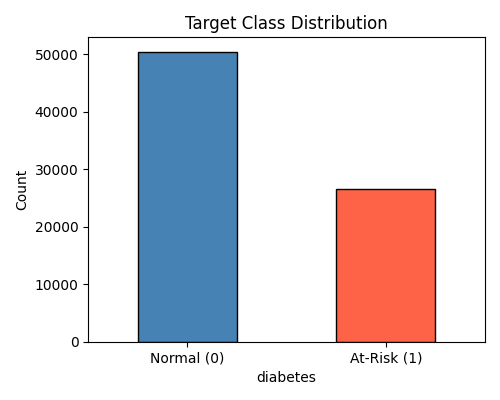

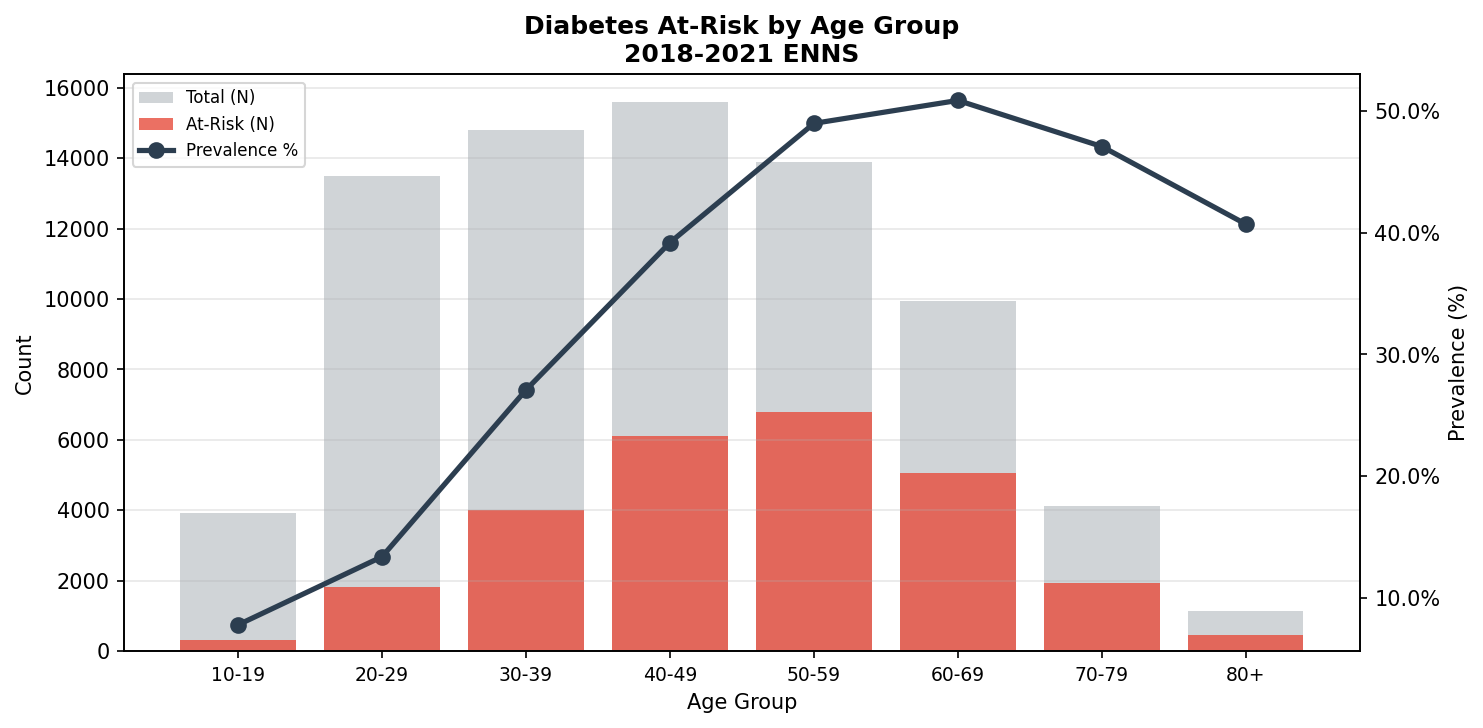

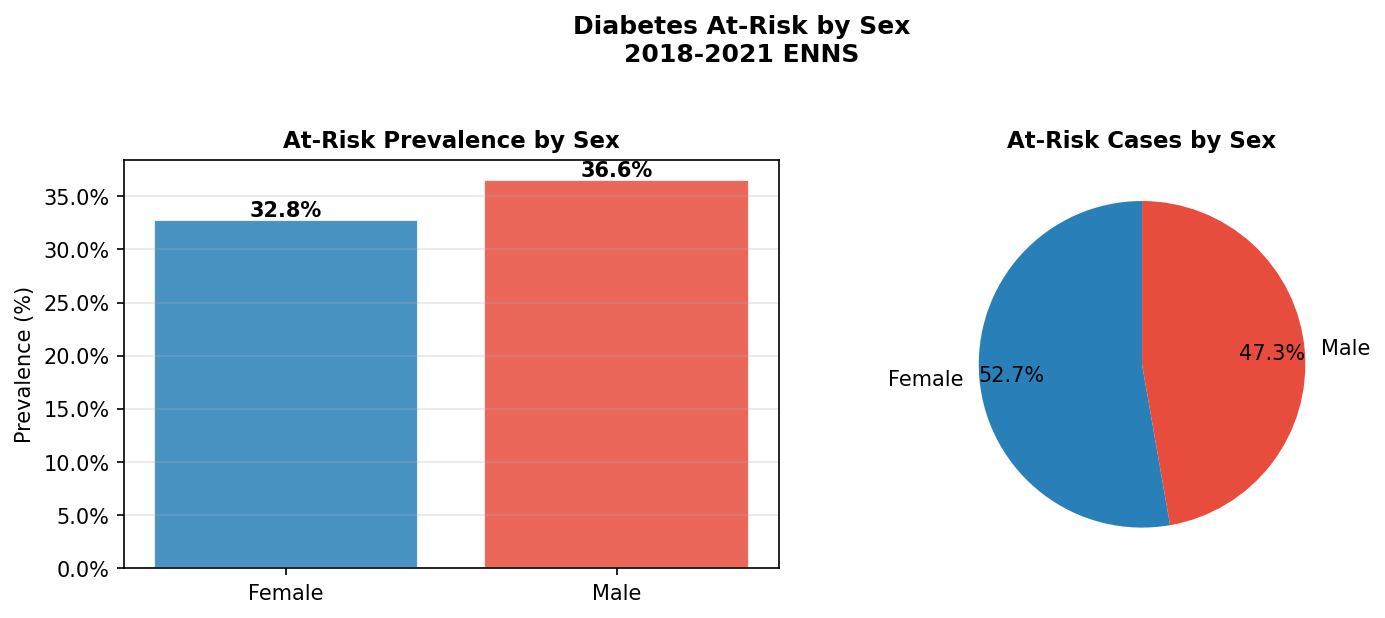

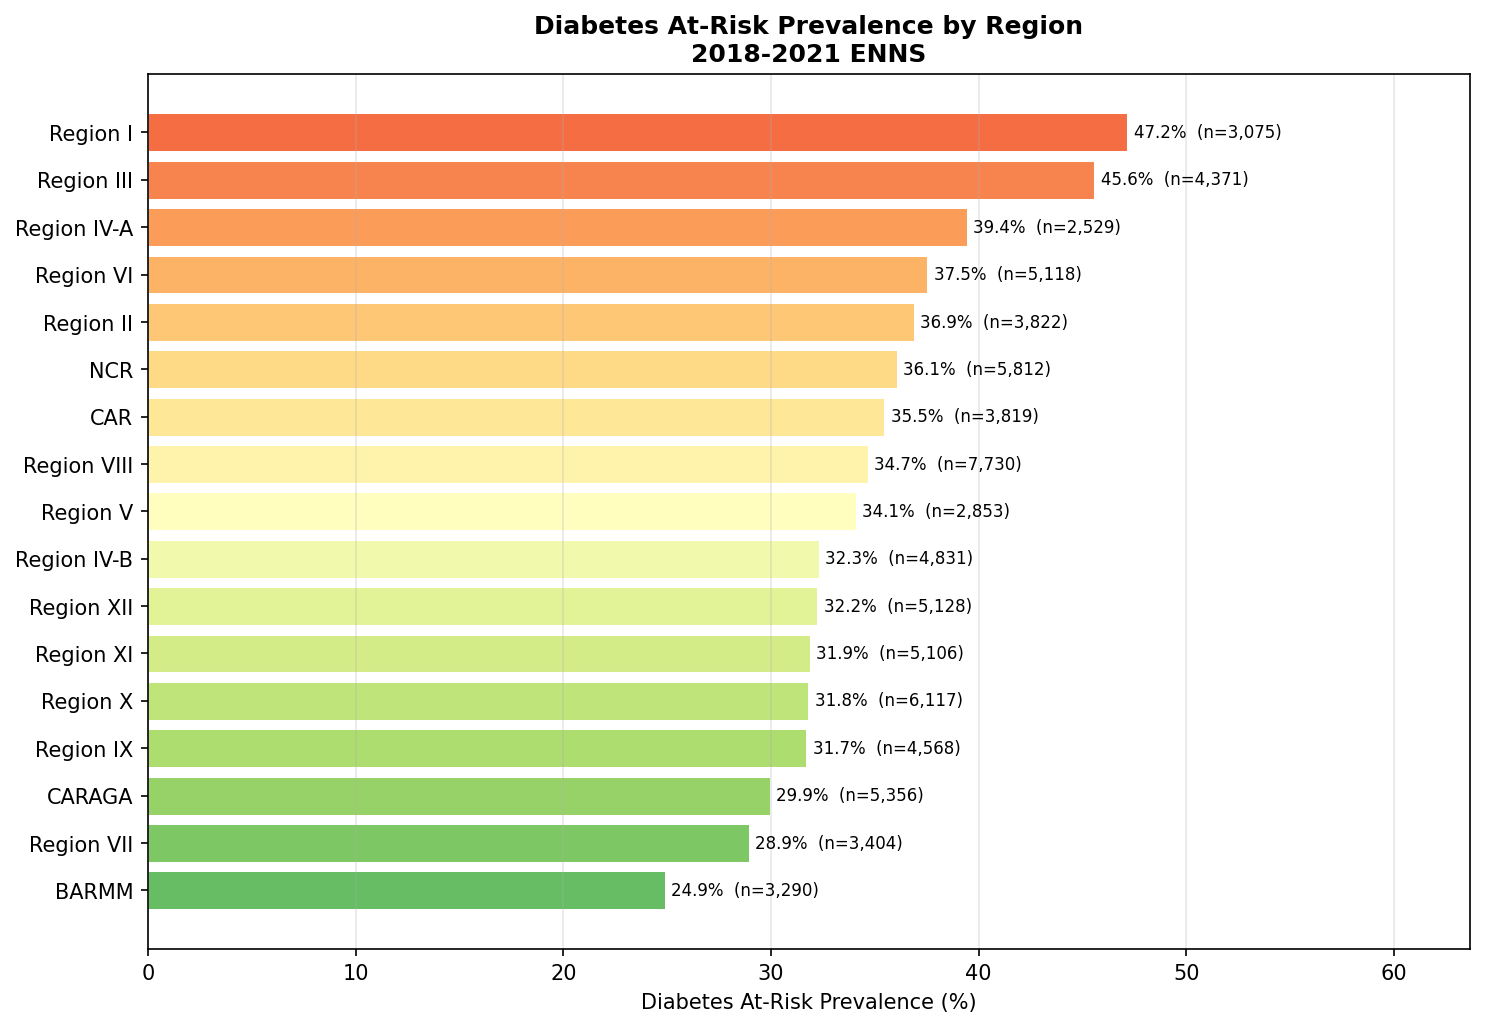

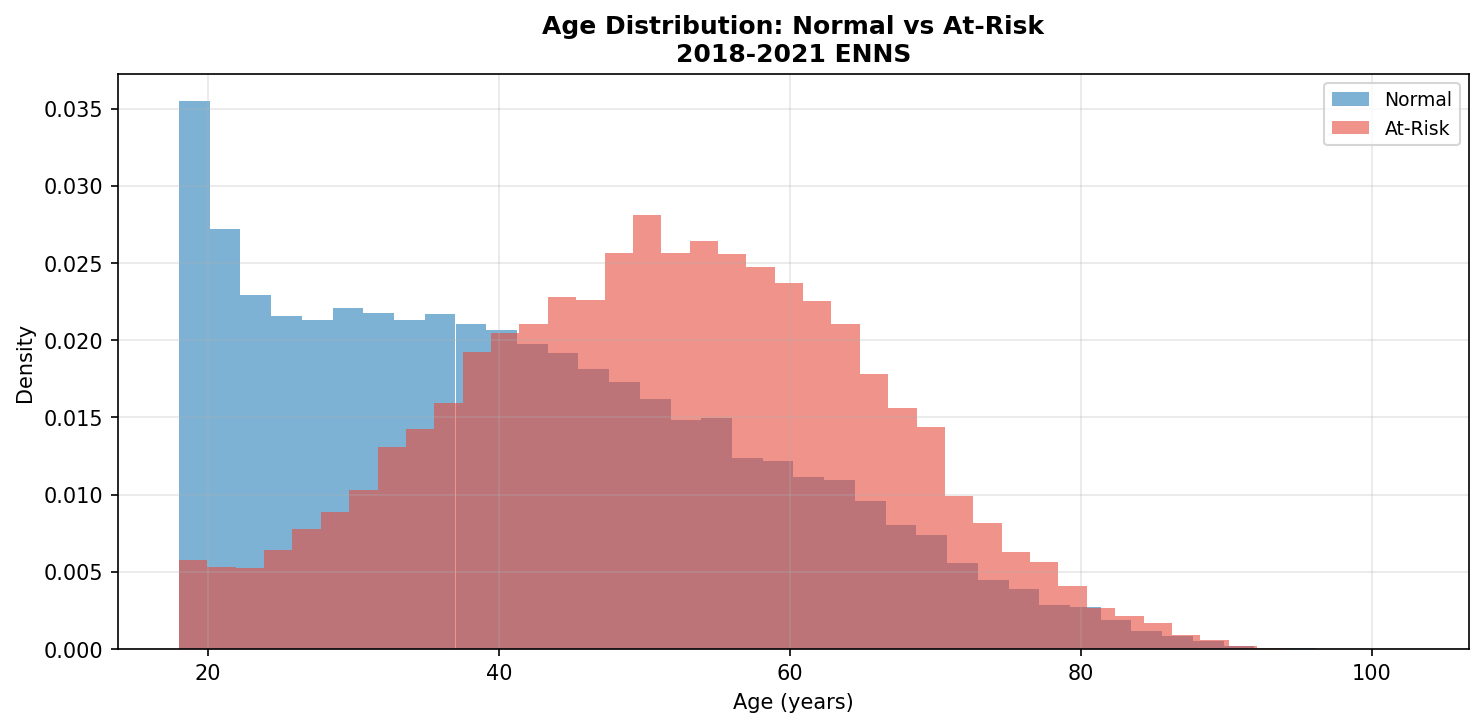

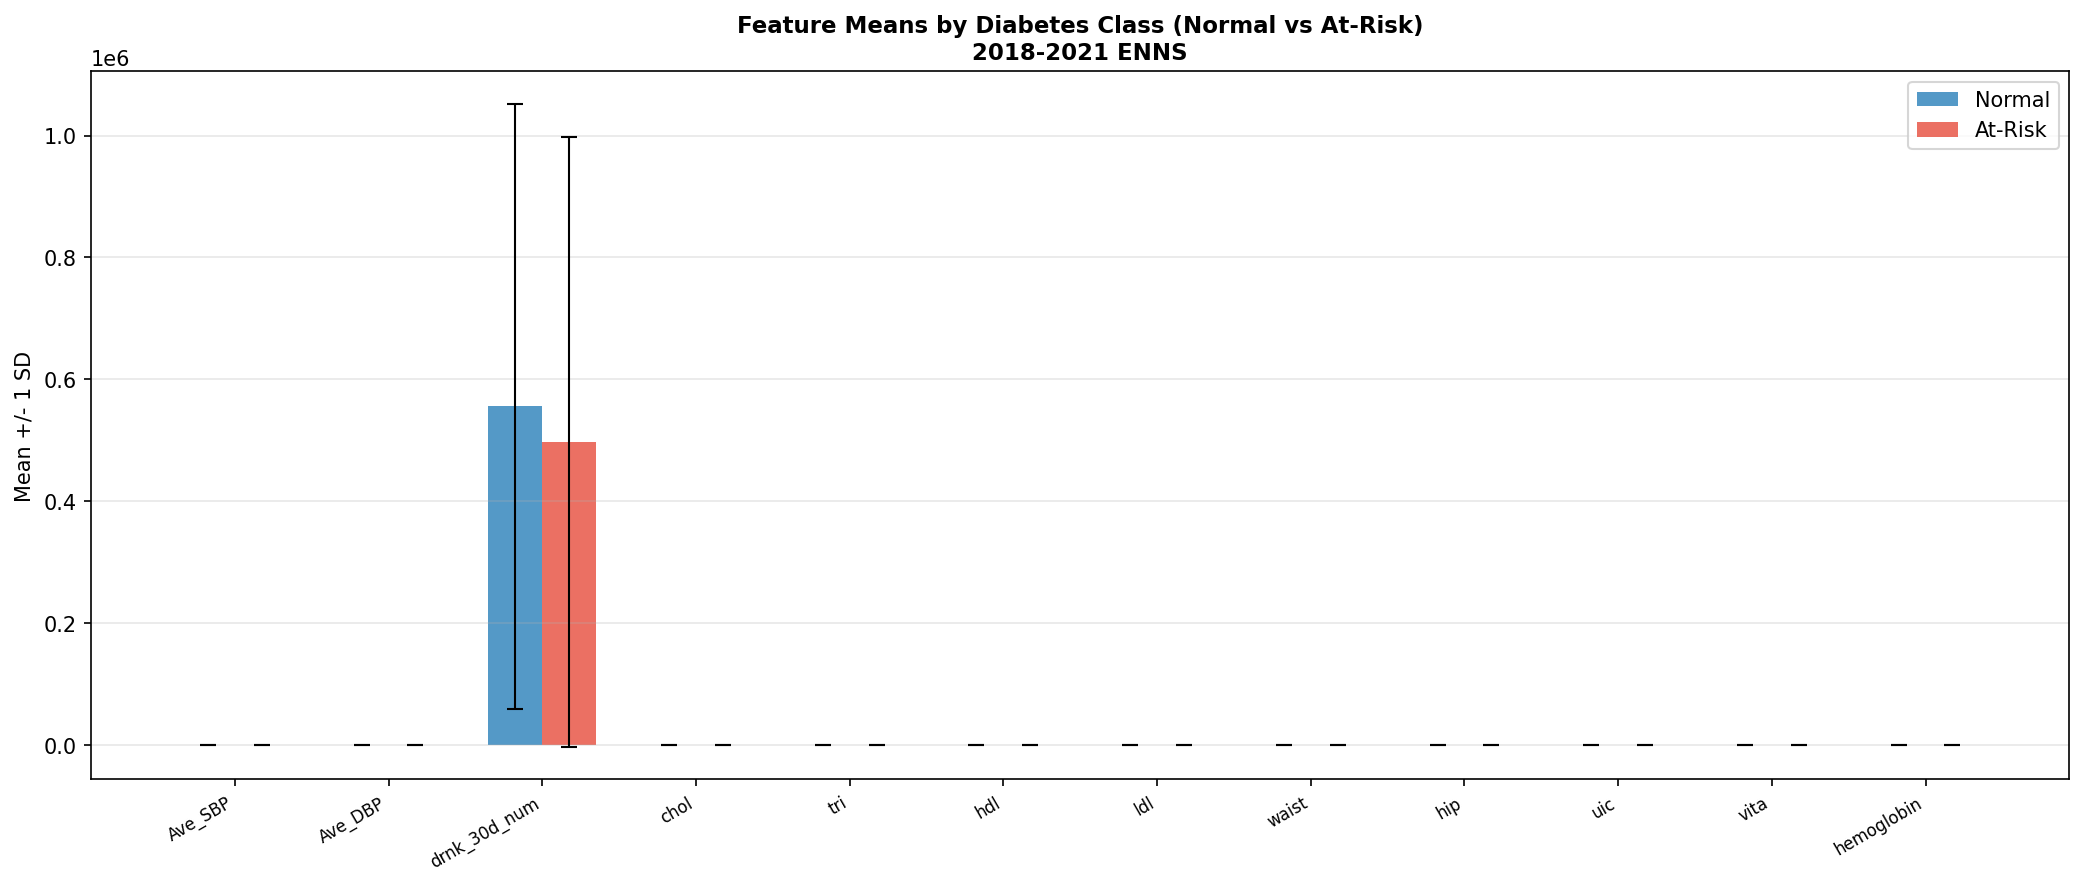

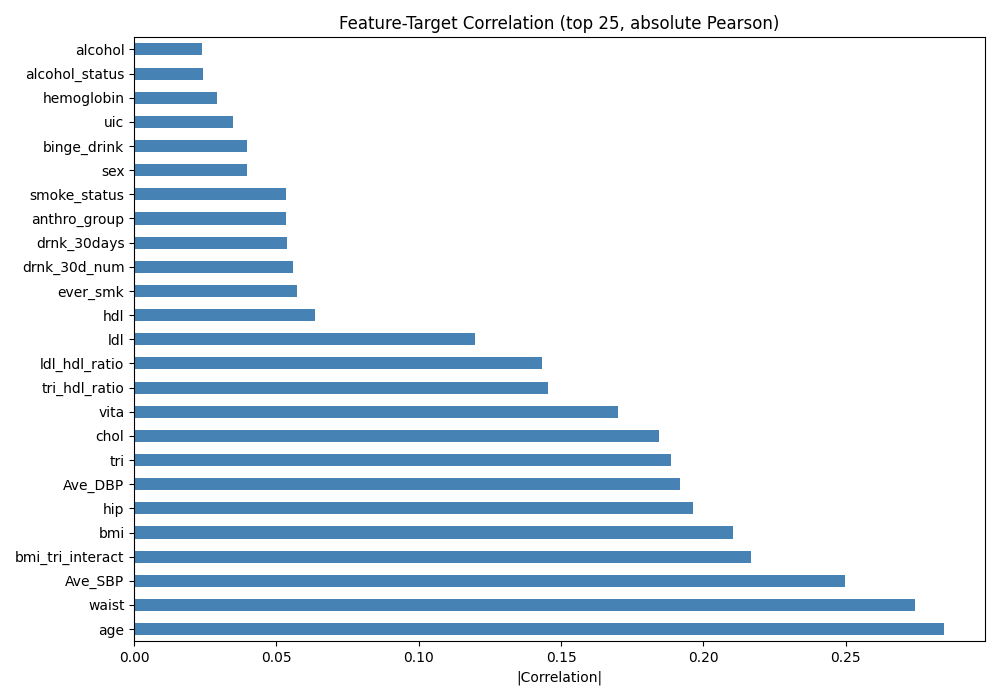

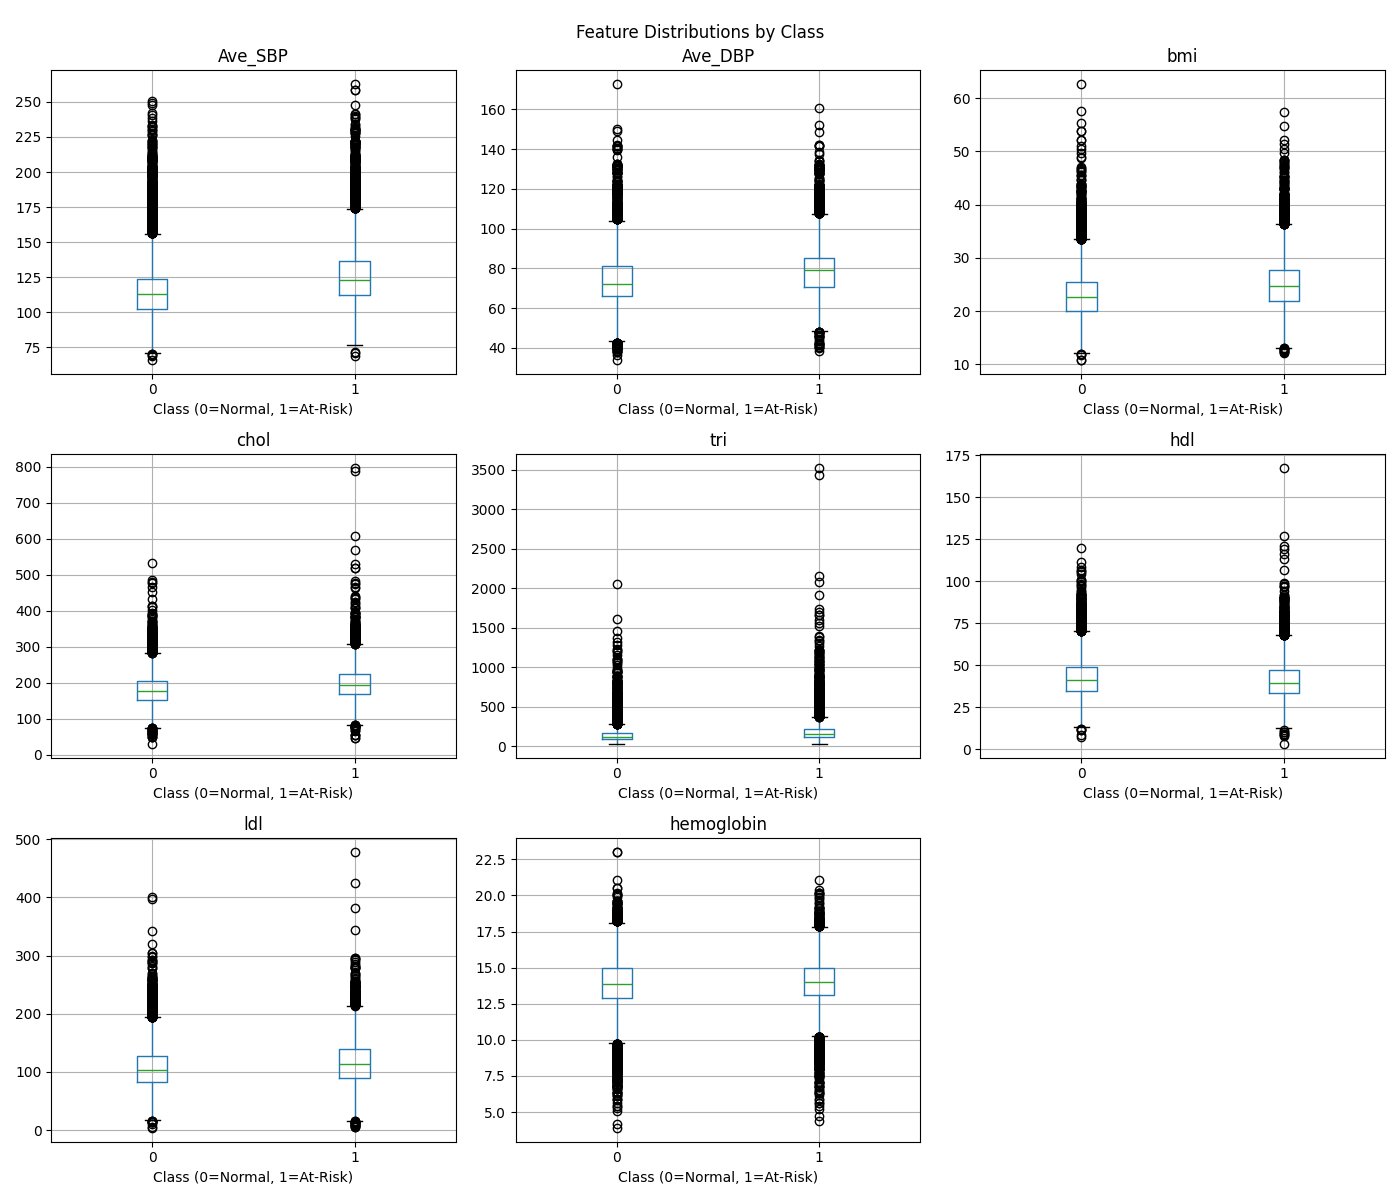

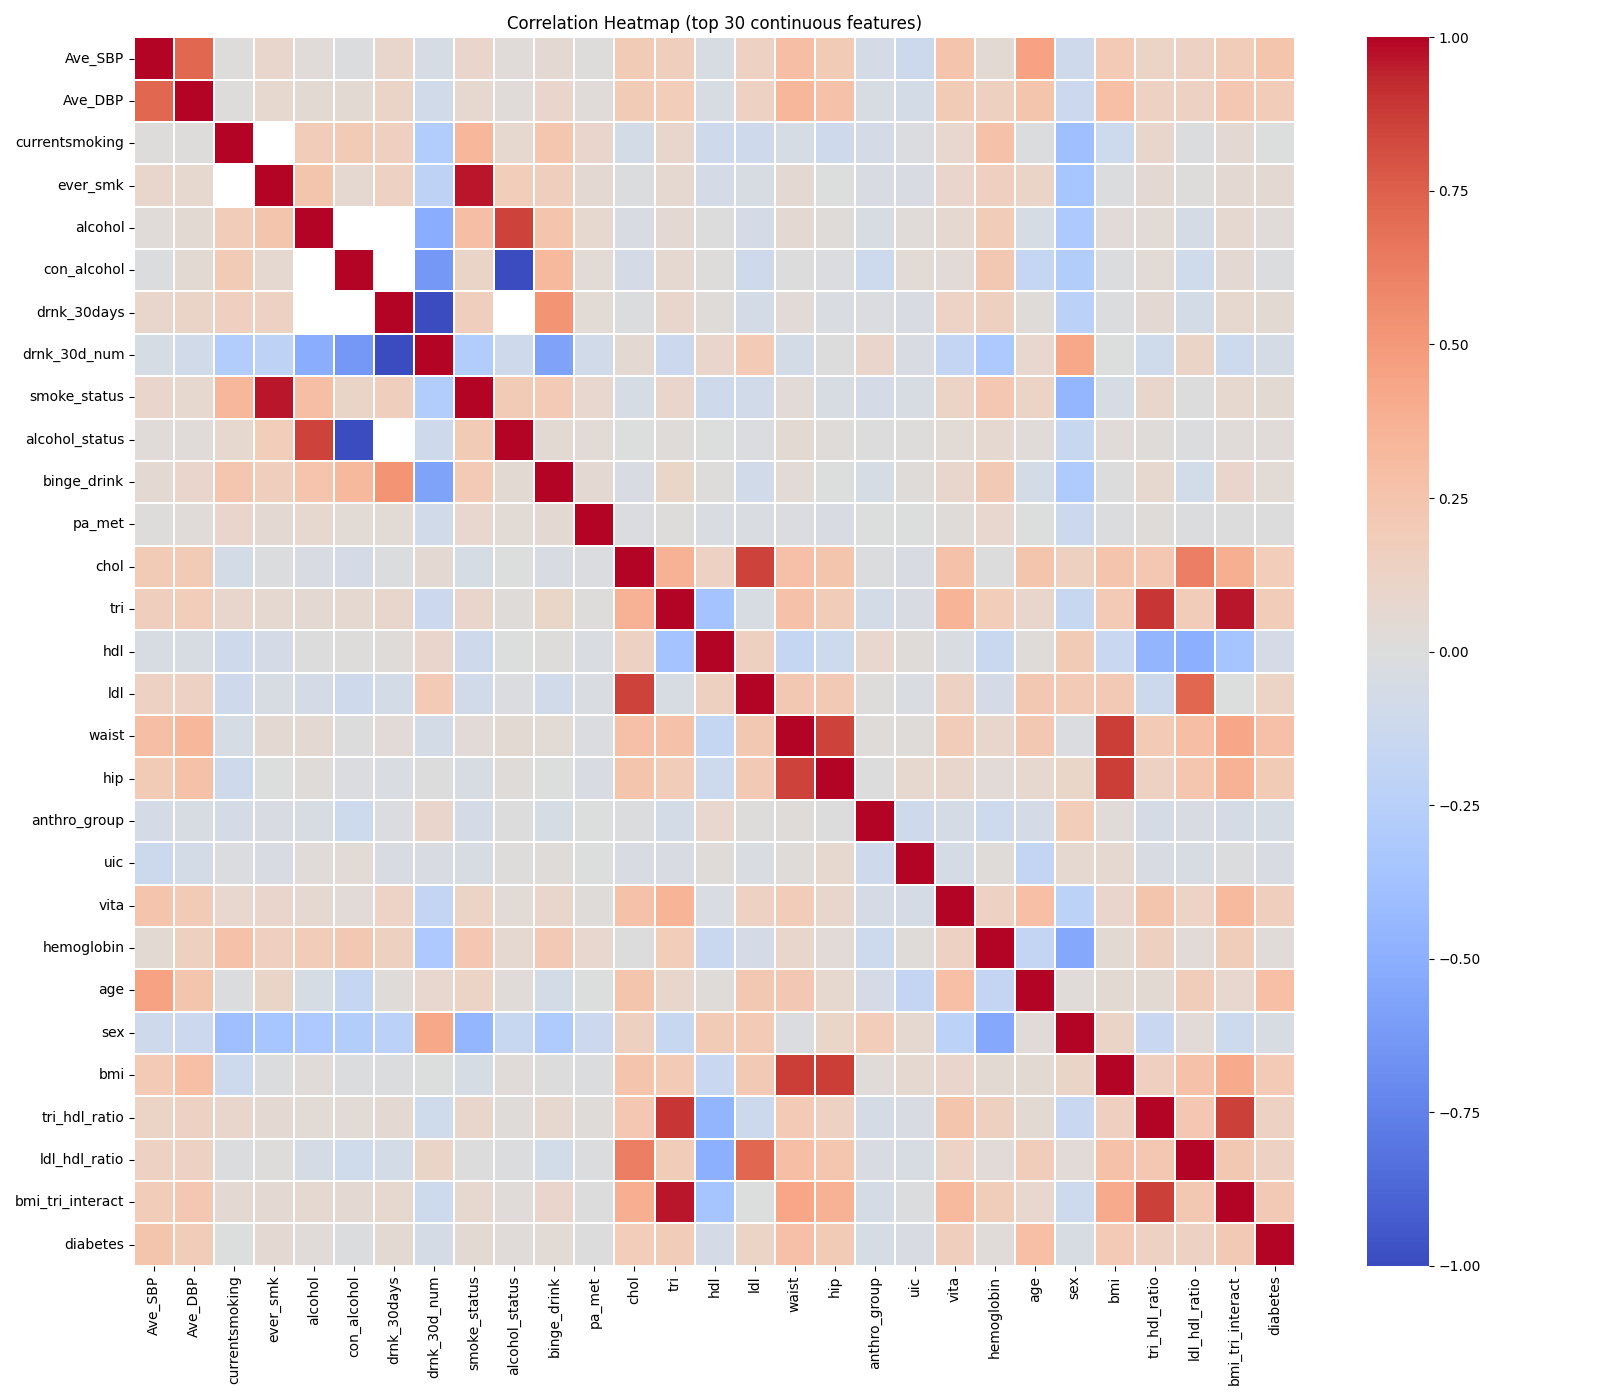

In [28]:
for f in ['class_distribution', 'diabetes_by_age_group', 'diabetes_by_sex', 'diabetes_by_region',
          'age_distribution', 'descriptive_stats_by_class', 'feature_target_correlation',
          'key_feature_boxplots', 'correlation_heatmap']:
    show_img(f'MAIN_PREPROCESS_OUTPUT/EDA/{f}.png')

---
## 3. Additional EDA (`main_eda_extra.py`)

Added after the V2 run. Reads `raw_merged.csv` only and writes new `eda2_*` files; it does not rerun preprocessing or change V2 arrays.

**Original script header**

> Additional V2 EDA (read-only on V2 outputs).
> 
> Reads MAIN_PREPROCESS_OUTPUT/raw_merged.csv (raw, unscaled, pre-split) and writes NEW files
> to MAIN_PREPROCESS_OUTPUT/EDA with the prefix 'eda2_'. Does not rerun preprocessing and does not
> touch V2 arrays, models, or existing EDA files.
> 
> Added analyses:
>   1. Missing-value and sentinel-value audit (table + chart)
>   2. Density distributions of every continuous feature by class
>   3. Boxplots of every continuous feature by class
>   4. Annotated correlation matrix plus signed feature-target correlation
> 
> Usage:  python main_eda_extra.py

#### `BASE`

In [29]:
BASE = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_PREPROCESS_OUTPUT")

#### `EDA_DIR`

In [30]:
EDA_DIR = BASE / 'EDA'

#### `TARGET`

In [31]:
TARGET = 'diabetes'

#### `CAT_COLS`

In [32]:
CAT_COLS = ['currentsmoking', 'ever_smk', 'alcohol', 'con_alcohol', 'drnk_30days',
            'smoke_status', 'binge_drink', 'anthro_group', 'sex']

#### `SENTINEL_MIN`

In [33]:
SENTINEL_MIN = 99999

#### `module-level assignment`

In [34]:
C0, C1 = '#2980b9', '#e74c3c'

#### `load`

In [35]:
def load():
    df = pd.read_csv(BASE / 'raw_merged.csv', low_memory=False)
    for c in df.columns:
        if c != TARGET:
            df[c] = pd.to_numeric(df[c], errors='coerce')
    cat = [c for c in CAT_COLS if c in df.columns]
    num = [c for c in df.columns if c not in cat + [TARGET]]
    return df, num, cat

#### `missing_and_sentinel_audit`

In [36]:
def missing_and_sentinel_audit(df, num, cat):
    rows = []
    for c in num + cat:
        s = df[c]
        rows.append({
            'feature': c,
            'type': 'categorical' if c in cat else 'continuous',
            'missing_n': int(s.isna().sum()),
            'missing_pct': round(s.isna().mean() * 100, 2),
            'sentinel_like_n': int((s >= SENTINEL_MIN).sum()),
            'at_risk_pct_when_missing': round(df.loc[s.isna(), TARGET].mean() * 100, 2) if s.isna().any() else np.nan,
            'at_risk_pct_when_present': round(df.loc[s.notna(), TARGET].mean() * 100, 2),
        })
    tbl = pd.DataFrame(rows).sort_values('missing_pct', ascending=False)
    tbl.to_csv(EDA_DIR / 'eda2_missing_sentinel_audit.csv', index=False)

    fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(tbl))))
    colors = [C1 if v > 40 else '#f39c12' if v > 10 else C0 for v in tbl['missing_pct']]
    ax.barh(tbl['feature'], tbl['missing_pct'], color=colors, alpha=0.85)
    ax.invert_yaxis()
    ax.set_xlabel('Missing (%)')
    ax.set_title(f'Missing Values per Feature (n={len(df):,})\nred > 40%, orange > 10%',
                 fontweight='bold', fontsize=11)
    for y, v in enumerate(tbl['missing_pct']):
        ax.text(v + 0.5, y, f'{v:.1f}%', va='center', fontsize=7)
    ax.set_xlim(0, max(tbl['missing_pct'].max() * 1.15, 5))
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'eda2_missing_values.png', dpi=150, bbox_inches='tight')
    plt.close()

    flagged = tbl[tbl['sentinel_like_n'] > 0]
    if len(flagged):
        print('  Features containing sentinel-like values (>= %d):' % SENTINEL_MIN)
        print(flagged[['feature', 'sentinel_like_n']].to_string(index=False))
    print('  Saved: eda2_missing_sentinel_audit.csv, eda2_missing_values.png')

#### `_grid`

In [37]:
def _grid(n, n_cols=4):
    n_rows = math.ceil(n / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4, n_rows * 3))
    return fig, np.atleast_1d(axes).flatten()

#### `_trim`

Clip display range to central percentiles so sentinels/extremes do not flatten the plot.

In [38]:
def _trim(s, lo=0.5, hi=99.5):
    """Clip display range to central percentiles so sentinels/extremes do not flatten the plot."""
    s = s.dropna()
    if s.empty:
        return s
    a, b = np.percentile(s, [lo, hi])
    return s[(s >= a) & (s <= b)]

#### `distributions_by_class`

In [39]:
def distributions_by_class(df, num):
    fig, axes = _grid(len(num))
    for ax, col in zip(axes, num):
        for cls, color, label in [(0, C0, 'Normal'), (1, C1, 'At-Risk')]:
            s = _trim(df.loc[df[TARGET] == cls, col])
            if s.nunique() > 1:
                ax.hist(s, bins=30, alpha=0.6, color=color, label=label, density=True)
        ax.set_title(col, fontsize=8, fontweight='bold')
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.3)
    for ax in axes[len(num):]:
        ax.set_visible(False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=C0, alpha=0.6), plt.Rectangle((0, 0), 1, 1, color=C1, alpha=0.6)]
    fig.legend(handles, ['Normal', 'At-Risk'], loc='lower right', fontsize=10, ncol=2)
    fig.suptitle('Continuous Feature Distributions by Class (0.5-99.5 percentile range)\n2018-2021 ENNS',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'eda2_feature_distributions.png', dpi=150, bbox_inches='tight')
    plt.close()
    print('  Saved: eda2_feature_distributions.png')

#### `boxplots_by_class`

In [40]:
def boxplots_by_class(df, num):
    fig, axes = _grid(len(num))
    for ax, col in zip(axes, num):
        data = [df.loc[df[TARGET] == c, col].dropna() for c in (0, 1)]
        if any(len(d) == 0 for d in data):
            ax.set_visible(False)
            continue
        bp = ax.boxplot(data, patch_artist=True, widths=0.5, medianprops=dict(color='black', linewidth=2))
        for box, color in zip(bp['boxes'], (C0, C1)):
            box.set_facecolor(color)
            box.set_alpha(0.7)
        ax.set_xticks([1, 2])
        ax.set_xticklabels(['Normal', 'At-Risk'], fontsize=7)
        ax.set_title(col, fontsize=8, fontweight='bold')
        ax.tick_params(axis='y', labelsize=7)
        ax.grid(axis='y', alpha=0.3)
    for ax in axes[len(num):]:
        ax.set_visible(False)
    fig.suptitle('Boxplots by Class: Outlier Inspection (raw values)\n2018-2021 ENNS',
                 fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'eda2_boxplots_all.png', dpi=150, bbox_inches='tight')
    plt.close()
    print('  Saved: eda2_boxplots_all.png')

#### `correlation_analysis`

In [41]:
def correlation_analysis(df, num):
    clean = df[num + [TARGET]].copy()
    for c in num:
        clean.loc[clean[c] >= SENTINEL_MIN, c] = np.nan
    corr = clean.corr()
    corr.to_csv(EDA_DIR / 'eda2_correlation_matrix.csv')

    tcorr = corr[TARGET].drop(TARGET).dropna().sort_values(key=abs, ascending=False)
    tcorr.rename('pearson_r_with_target').to_csv(EDA_DIR / 'eda2_target_correlation.csv')

    fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1.6, 1]})
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.4,
                annot_kws={'size': 6}, ax=axes[0], cbar_kws={'shrink': 0.8})
    axes[0].set_title('Pairwise Pearson Correlation (pairwise-complete, sentinels excluded)',
                      fontweight='bold', fontsize=11)
    axes[0].tick_params(axis='x', rotation=60, labelsize=7)
    axes[0].tick_params(axis='y', rotation=0, labelsize=7)

    axes[1].barh(tcorr.index, tcorr.values, color=[C1 if v > 0 else C0 for v in tcorr.values], alpha=0.85)
    axes[1].invert_yaxis()
    axes[1].axvline(0, color='black', linewidth=0.8)
    axes[1].set_xlabel('Pearson r with target')
    axes[1].set_title('Feature Correlation with At-Risk Class\n(red = positive)', fontweight='bold', fontsize=11)
    axes[1].grid(axis='x', alpha=0.3)
    axes[1].tick_params(labelsize=8)
    plt.tight_layout()
    plt.savefig(EDA_DIR / 'eda2_correlation_analysis.png', dpi=150, bbox_inches='tight')
    plt.close()

    pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
    pairs = pairs[pairs.abs() > 0.8].rename('r').reset_index()
    pairs.columns = ['feature_a', 'feature_b', 'r']
    pairs.sort_values('r', key=abs, ascending=False).to_csv(EDA_DIR / 'eda2_high_correlation_pairs.csv', index=False)
    print('  Saved: eda2_correlation_analysis.png, eda2_correlation_matrix.csv, '
          'eda2_target_correlation.csv, eda2_high_correlation_pairs.csv')

#### `run_eda_extra`

In [42]:
def run_eda_extra():
    EDA_DIR.mkdir(parents=True, exist_ok=True)
    df, num, cat = load()
    print(f'Loaded {df.shape} | at-risk prevalence {df[TARGET].mean() * 100:.1f}% | '
          f'{len(num)} continuous, {len(cat)} categorical')
    missing_and_sentinel_audit(df, num, cat)
    distributions_by_class(df, num)
    boxplots_by_class(df, num)
    correlation_analysis(df, num)
    print(f'\nDone. Outputs in {EDA_DIR}')

### Run and saved results (3. Additional EDA)

In [43]:
if RUN_EXTRA_EDA:
    run_eda_extra()
else:
    print('RUN_EXTRA_EDA = False: showing saved V2 outputs.')

RUN_EXTRA_EDA = False: showing saved V2 outputs.


In [44]:
show_csv('MAIN_PREPROCESS_OUTPUT/EDA/eda2_missing_sentinel_audit.csv')

,feature,type,missing_n,missing_pct,sentinel_like_n,at_risk_pct_when_missing,at_risk_pct_when_present
0,drnk_30days,categorical,43844,56.99,0,34.03,35.03
1,drnk_30d_num,continuous,38953,50.64,20325,34.35,34.57
2,uic,continuous,36907,47.98,0,36.55,32.53
3,vita,continuous,35963,46.75,0,36.89,32.33
4,bmi_tri_interact,continuous,34360,44.66,0,33.76,35.03
5,chol,continuous,33638,43.73,0,33.68,35.07
6,tri_hdl_ratio,continuous,33636,43.72,0,33.68,35.07
7,tri,continuous,33636,43.72,0,33.68,35.07
8,hdl,continuous,33635,43.72,0,33.67,35.07
9,ldl,continuous,33637,43.72,0,33.67,35.07


,feature,type,missing_n,missing_pct,sentinel_like_n,at_risk_pct_when_missing,at_risk_pct_when_present
0,drnk_30days,categorical,43844,56.99,0,34.03,35.03
1,drnk_30d_num,continuous,38953,50.64,20325,34.35,34.57
2,uic,continuous,36907,47.98,0,36.55,32.53
3,vita,continuous,35963,46.75,0,36.89,32.33
4,bmi_tri_interact,continuous,34360,44.66,0,33.76,35.03
5,chol,continuous,33638,43.73,0,33.68,35.07
6,tri_hdl_ratio,continuous,33636,43.72,0,33.68,35.07
7,tri,continuous,33636,43.72,0,33.68,35.07
8,hdl,continuous,33635,43.72,0,33.67,35.07
9,ldl,continuous,33637,43.72,0,33.67,35.07


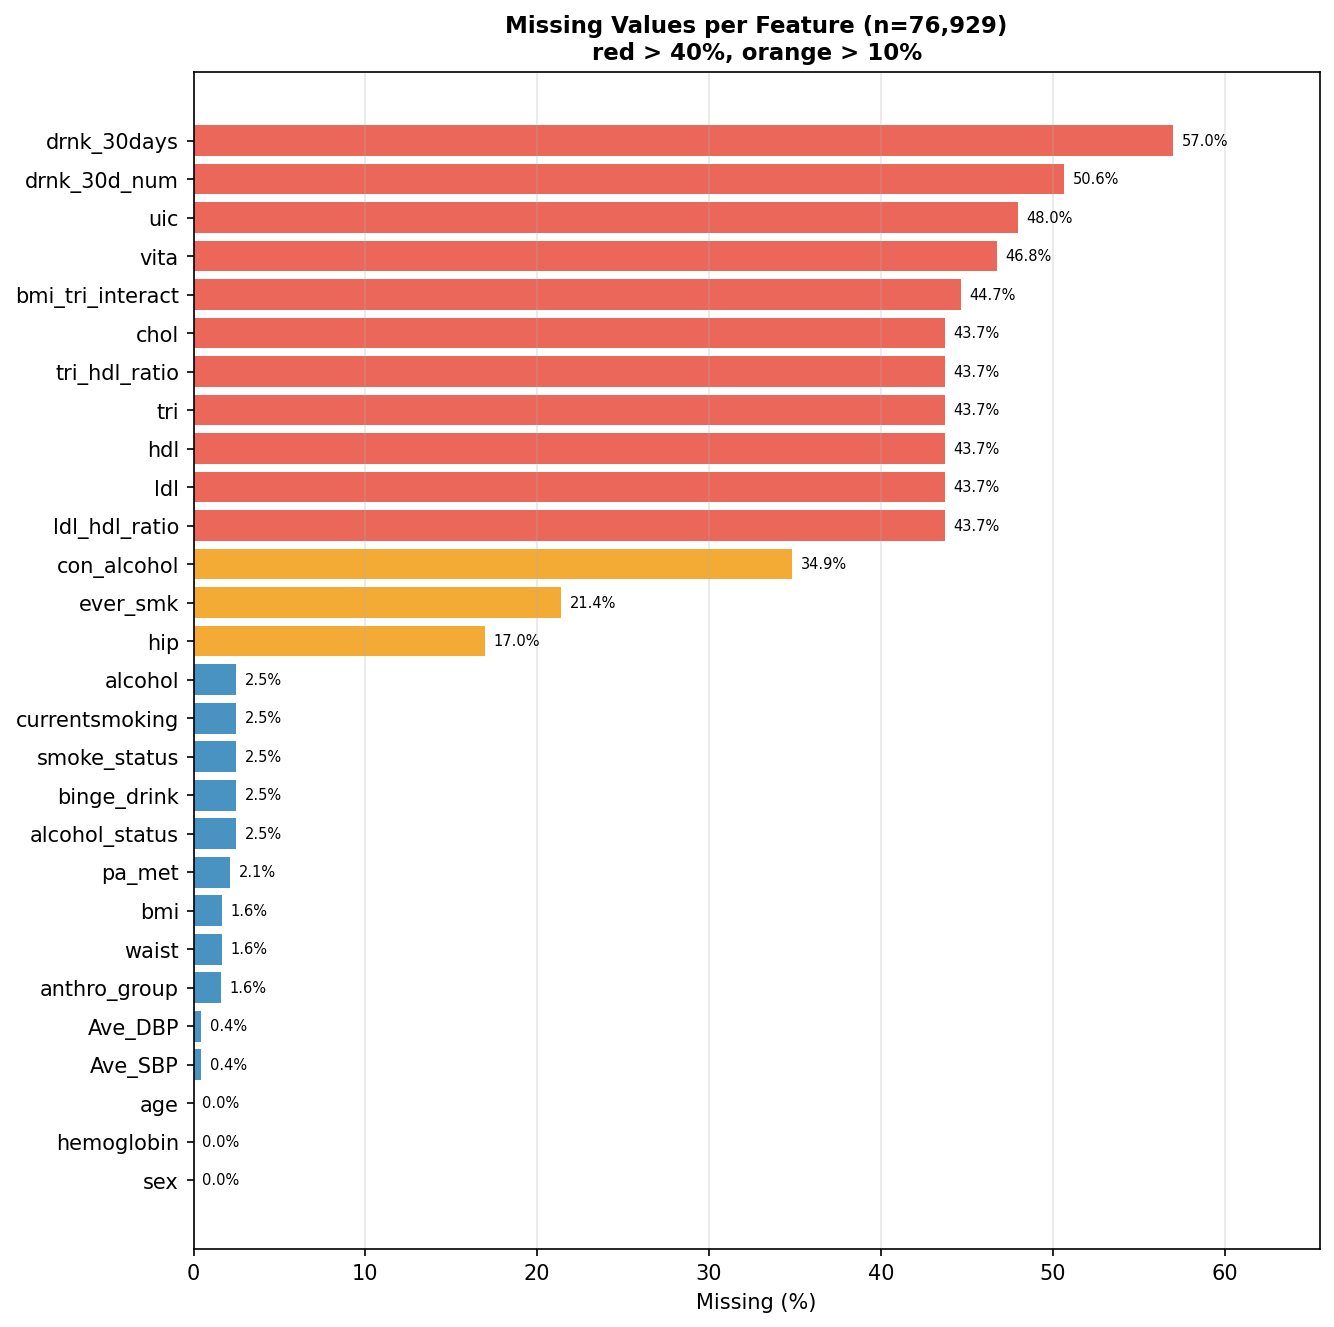

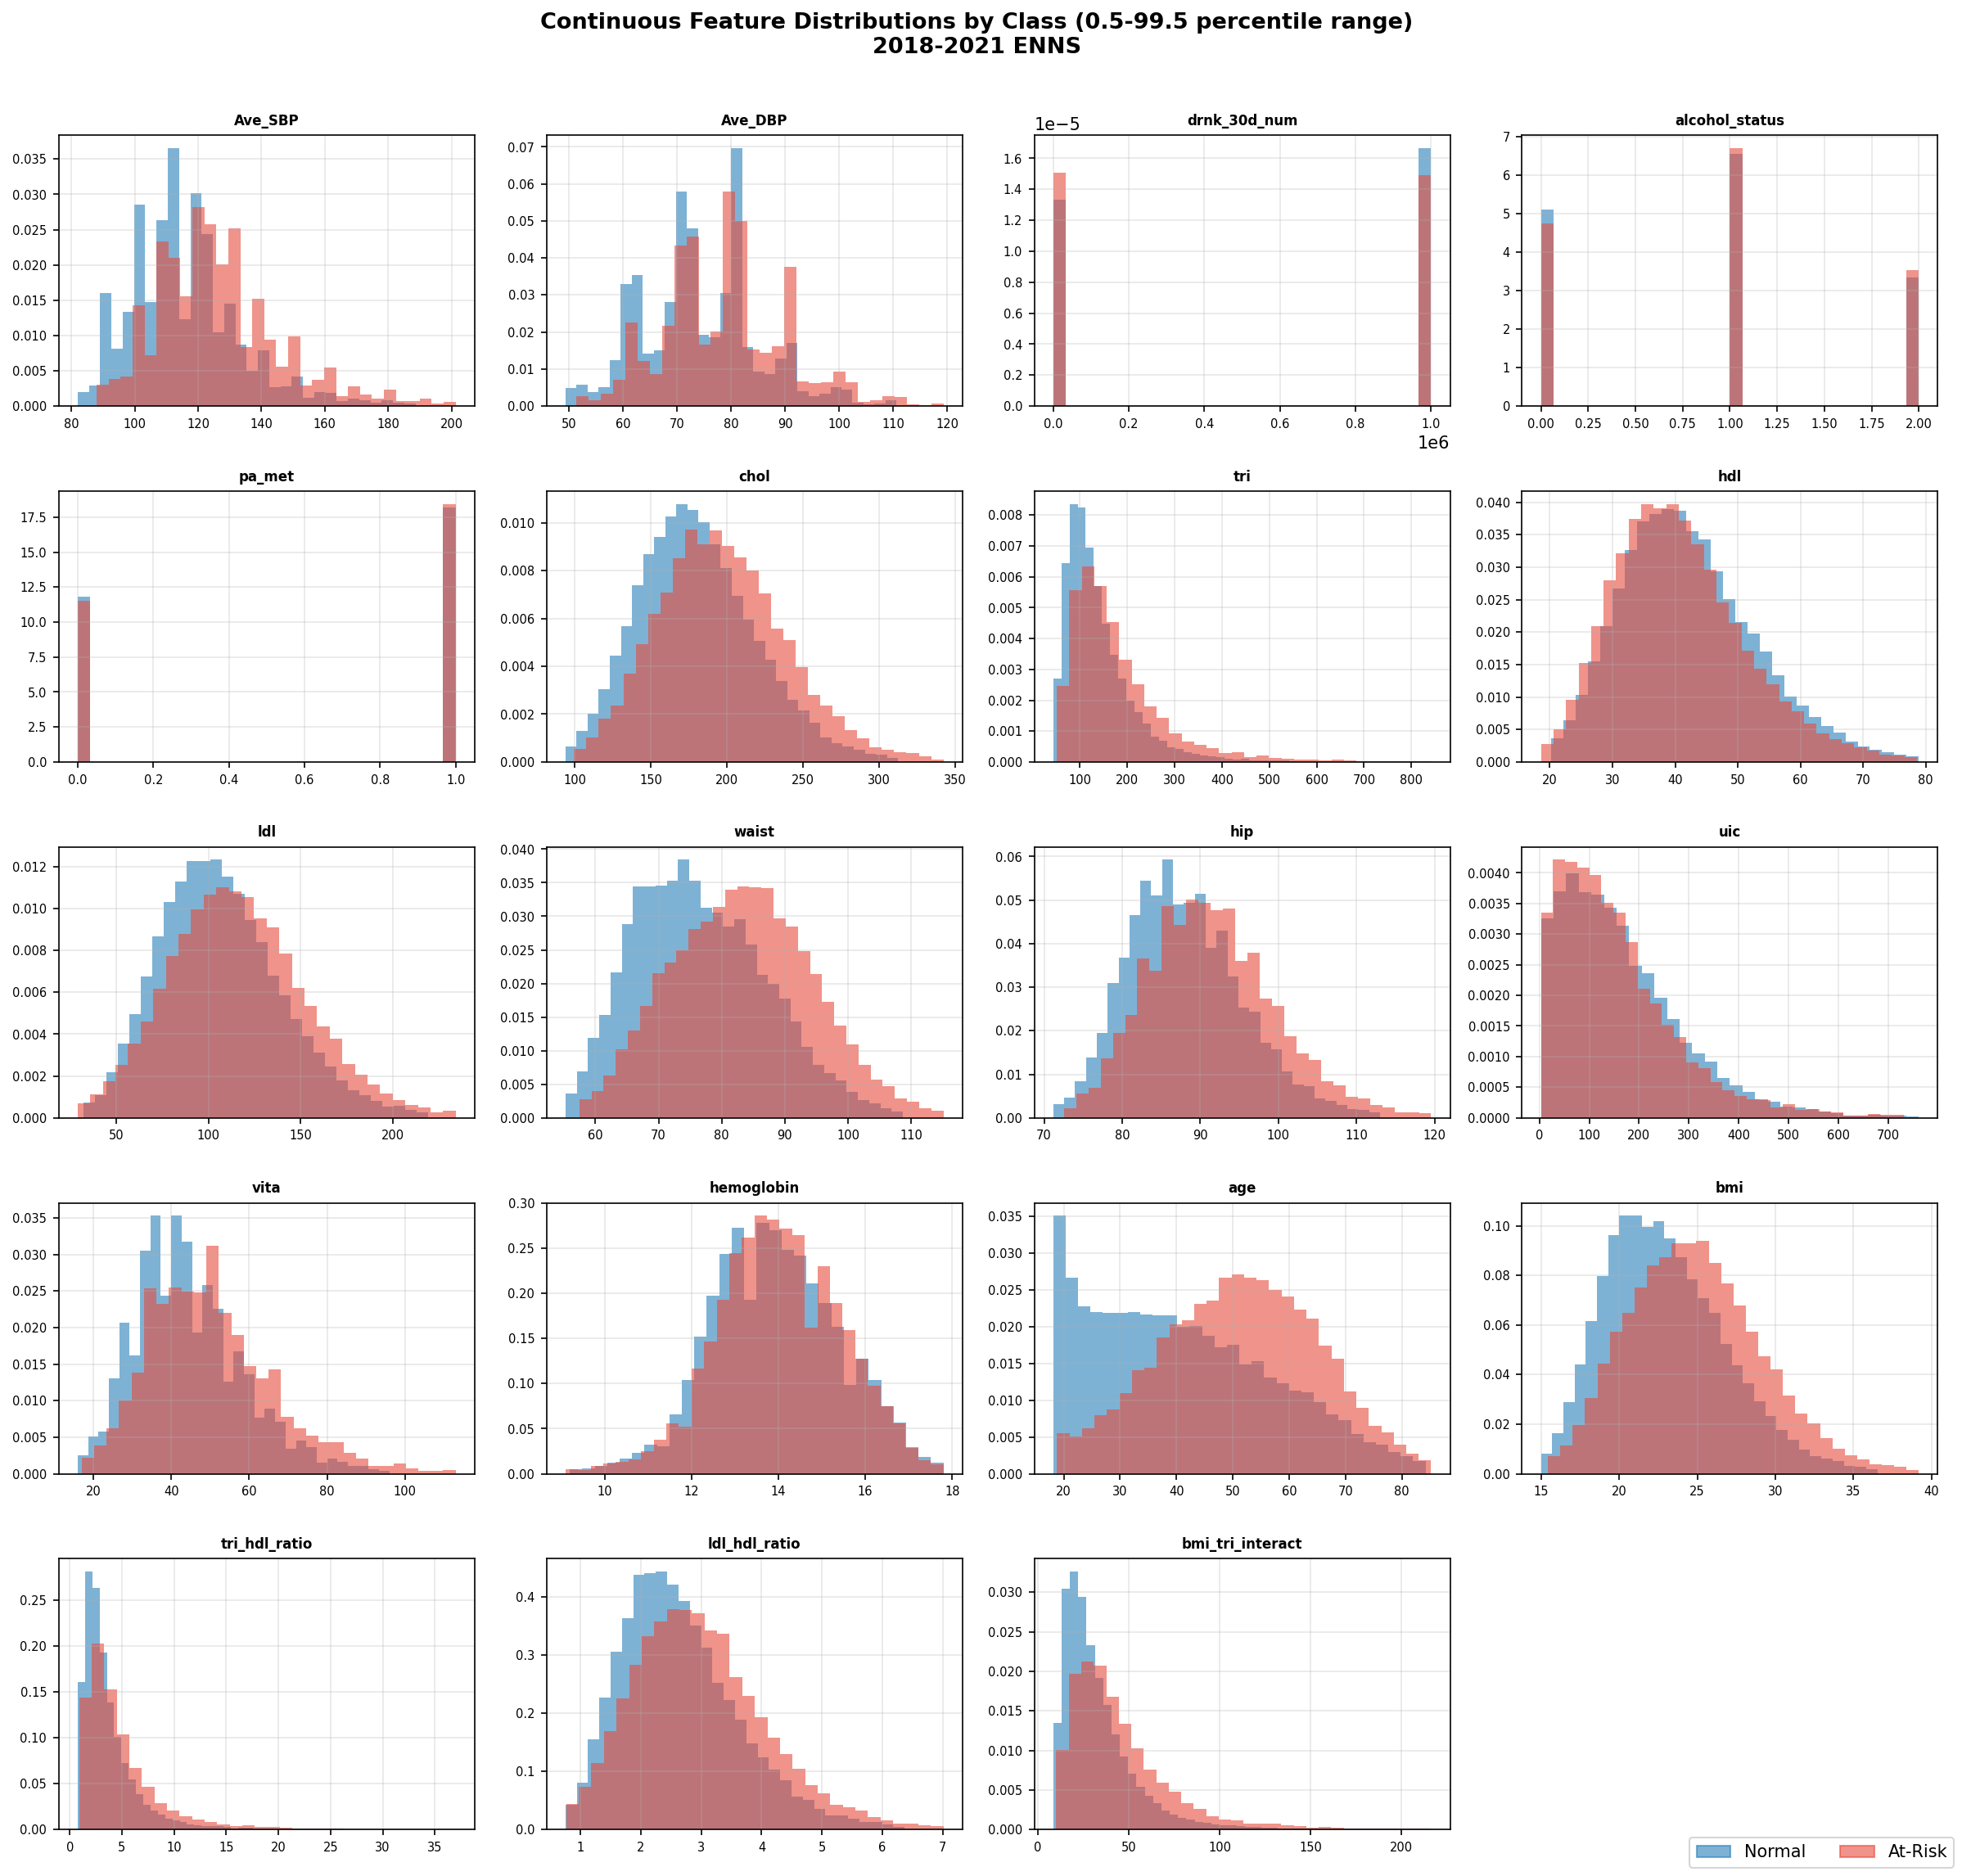

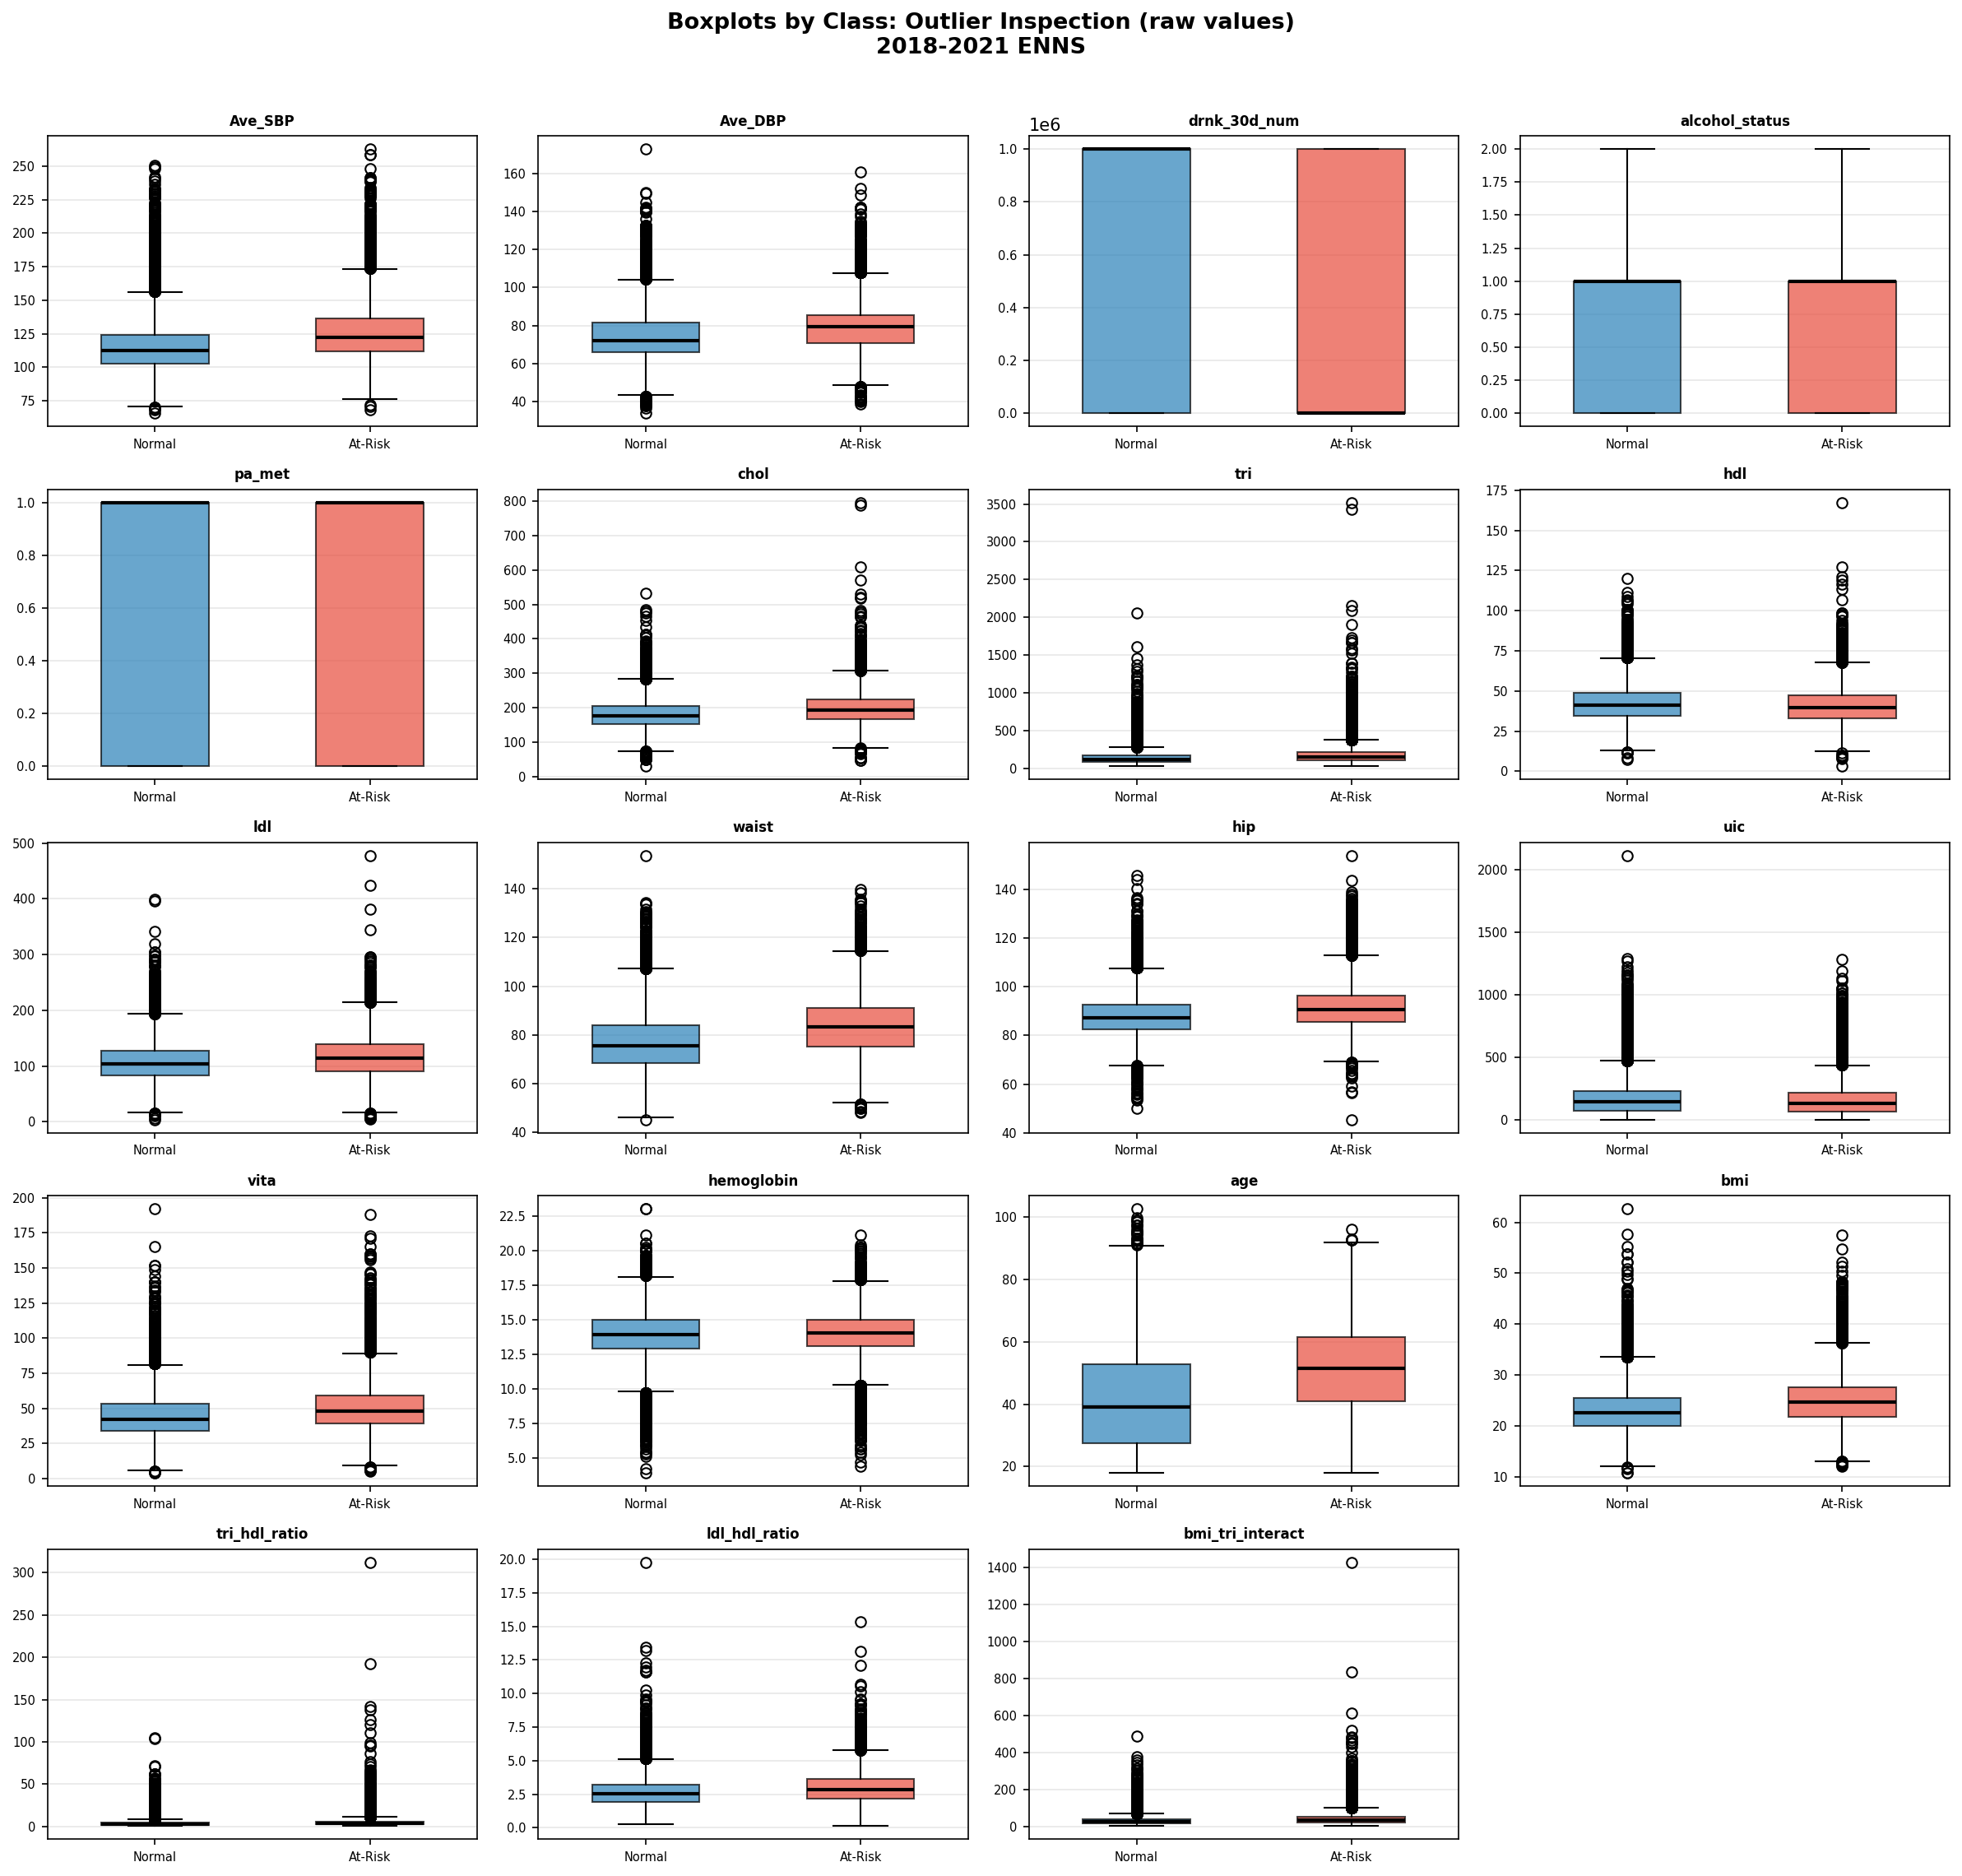

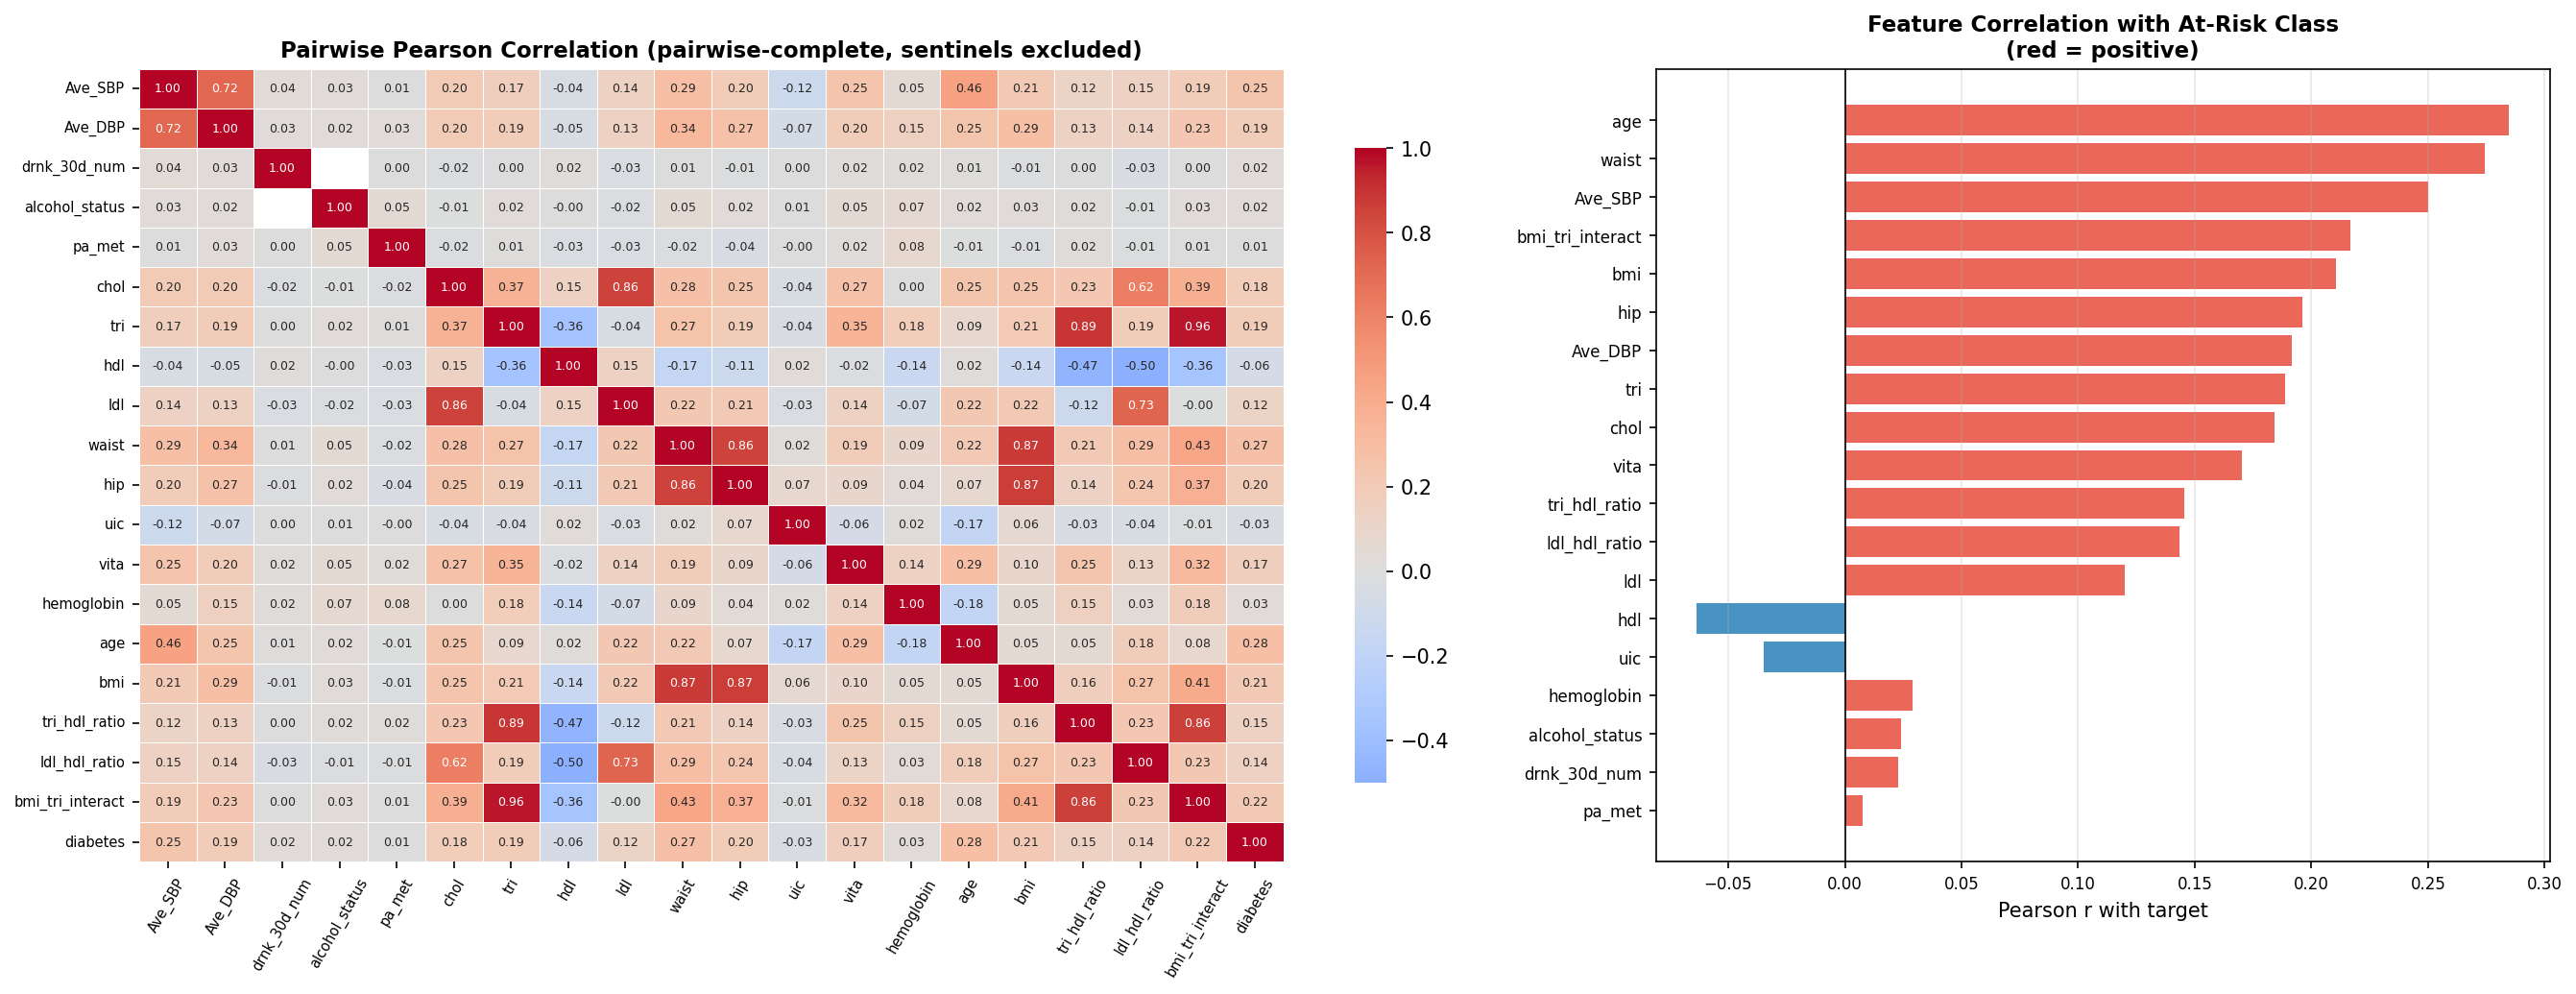

In [45]:
for f in ['eda2_missing_values', 'eda2_feature_distributions', 'eda2_boxplots_all',
          'eda2_correlation_analysis']:
    show_img(f'MAIN_PREPROCESS_OUTPUT/EDA/{f}.png', width=1100)

---
## 4. Model training (`main_train.py`)

Ten approaches optimised for F2: BO-TabNet (Optuna), Naive Bayes, kNN, AdaBoost, XGBoost, Random Forest, CatBoost, LightGBM, plus Voting and Stacking ensembles.

**Original script header**

> Main Model Training Pipeline (2018-2021 ENNS)
> 
>   - Data from MAIN_PREPROCESS_OUTPUT  (SMOTE-before-split, corr=0.80)
>   - Primary metric: F2-score (β=2, recall-weighted)
>   - BO-TabNet (Bayesian-Optimized via Optuna) as primary model
>   - All standard ML models + Stacking + Voting ensembles
>   - Outputs to MAIN_MODEL_RESULTS / MAIN_TRAINED_MODELS

#### `TrainConfig`

In [46]:
class TrainConfig:
    data_dir   = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_PREPROCESS_OUTPUT")
    output_dir = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_MODEL_RESULTS")
    models_dir = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_TRAINED_MODELS")

    random_state  = 42
    n_jobs        = -1
    cv_folds      = 5
    n_iter        = 30   # RandomizedSearch + Optuna BO trials
    skip_tabnet   = False  # Set True to skip TabNet (loads prior metrics from CSV instead)
    tabnet_only   = True   # Set True to train ONLY TabNet (loads prior ML metrics from CSV)

    # Primary metric: F2 (recall-weighted, beta=2)
    f2_scorer           = make_scorer(fbeta_score, beta=2, zero_division=0)
    optimization_scorer = f2_scorer

#### `load_data`

In [47]:
def load_data(config):
    print("\n" + "="*80)
    print("LOADING PREPROCESSED DATA  (2018-2021 ENNS)")
    print("="*80)
    X_train = np.load(config.data_dir / 'X_train.npy')
    y_train = np.load(config.data_dir / 'y_train.npy')
    X_val   = np.load(config.data_dir / 'X_val.npy')
    y_val   = np.load(config.data_dir / 'y_val.npy')
    X_test  = np.load(config.data_dir / 'X_test.npy')
    y_test  = np.load(config.data_dir / 'y_test.npy')
    info    = joblib.load(config.data_dir / 'preprocessing_info.pkl')

    n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
    class_weights = {0: len(y_train) / (2 * n0), 1: len(y_train) / (2 * n1)}
    info['class_weights'] = class_weights

    print(f"  Train : {X_train.shape}  | Class 1: {y_train.mean()*100:.1f}%")
    print(f"  Val   : {X_val.shape}  | Class 1: {y_val.mean()*100:.1f}%")
    print(f"  Test  : {X_test.shape}  | Class 1: {y_test.mean()*100:.1f}%")
    features = info.get('feature_names', [f'f{i}' for i in range(X_train.shape[1])])
    print(f"  Features ({len(features)}): {features[:6]}...")
    return X_train, y_train, X_val, y_val, X_test, y_test, info

#### `evaluate_model`

In [48]:
def evaluate_model(model, X, y, model_name):
    y_pred  = model.predict(X)
    y_proba = model.predict_proba(X) if hasattr(model, 'predict_proba') else None
    roc_auc = roc_auc_score(y, y_proba[:, 1]) if y_proba is not None else 0.0
    auprc   = average_precision_score(y, y_proba[:, 1]) if y_proba is not None else 0.0
    p_pc = precision_score(y, y_pred, average=None, zero_division=0)
    r_pc = recall_score(y, y_pred, average=None, zero_division=0)
    f_pc = f1_score(y, y_pred, average=None, zero_division=0)
    return {
        'model':             model_name,
        'accuracy':          accuracy_score(y, y_pred),
        'precision':         precision_score(y, y_pred, zero_division=0),
        'recall':            recall_score(y, y_pred, zero_division=0),
        'f1':                f1_score(y, y_pred, zero_division=0),
        'f2':                fbeta_score(y, y_pred, beta=2, zero_division=0),
        'roc_auc':           roc_auc,
        'auprc':             auprc,
        'precision_normal':  p_pc[0], 'recall_normal':  r_pc[0], 'f1_normal':  f_pc[0],
        'precision_at_risk': p_pc[1], 'recall_at_risk': r_pc[1], 'f1_at_risk': f_pc[1],
    }, y_pred, y_proba

#### `plot_confusion_matrix`

In [49]:
def plot_confusion_matrix(y_true, y_pred, model_name, output_dir):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Normal', 'At-Risk'],
                yticklabels=['Normal', 'At-Risk'])
    plt.title(f'Confusion Matrix — {model_name}')
    plt.ylabel('Actual'); plt.xlabel('Predicted')
    plt.tight_layout()
    plt.savefig(output_dir / f'{model_name.replace(" ","_")}_confusion_matrix.png', dpi=150)
    plt.close()

#### `print_metrics`

In [50]:
def print_metrics(m):
    print(f"  Accuracy : {m['accuracy']:.4f}")
    print(f"  Precision: {m['precision']:.4f}")
    print(f"  Recall   : {m['recall']:.4f}")
    print(f"  F1-Score : {m['f1']:.4f}")
    print(f"  F2-Score : {m['f2']:.4f}  (primary metric)")
    print(f"  ROC-AUC  : {m['roc_auc']:.4f}")
    print(f"  AUPRC    : {m['auprc']:.4f}")
    print(f"\n  Per-class metrics:")
    print(f"    Normal  - P: {m['precision_normal']:.4f}, R: {m['recall_normal']:.4f}, "
          f"F1: {m['f1_normal']:.4f}")
    print(f"    At-Risk - P: {m['precision_at_risk']:.4f}, R: {m['recall_at_risk']:.4f}, "
          f"F1: {m['f1_at_risk']:.4f}")

#### `train_botabnet`

In [51]:
def train_botabnet(X_train, y_train, X_val, y_val, X_test, y_test,
                   feature_names, config):
    print("\n" + "="*80)
    print("[1/11] BO-TABNET  (Bayesian-Optimized via Optuna)")
    print("="*80)

    Xtr = X_train.astype(np.float32); ytr = y_train.astype(int)
    Xv  = X_val.astype(np.float32);   yv  = y_val.astype(int)
    Xte = X_test.astype(np.float32);  yte = y_test.astype(int)

    # Load existing model if already trained (skip costly Optuna re-run)
    saved_zip = config.models_dir / 'botabnet.zip'
    if saved_zip.exists():
        print(f"  [Skip] Found saved BO-TabNet — loading from {saved_zip}")
        model = TabNetClassifier()
        model.load_model(str(saved_zip))
        print("\n[*] Evaluating BO-TabNet on test set...")
        m, y_pred, _ = evaluate_model(model, Xte, yte, 'BO-TabNet')
        print_metrics(m)
        plot_confusion_matrix(yte, y_pred, 'BO-TabNet', config.output_dir)
        return model, m

    n_trials = config.n_iter
    print(f"  Bayesian Optimisation: {n_trials} trials  |  metric: F2 on val set")

    def objective(trial):
        n_d      = trial.suggest_int('n_d', 8, 64, step=4)
        n_steps  = trial.suggest_int('n_steps', 3, 10)
        gamma    = trial.suggest_float('gamma', 1.0, 2.0)
        lam      = trial.suggest_float('lambda_sparse', 1e-6, 1e-3, log=True)
        lr       = trial.suggest_float('lr', 1e-4, 5e-2, log=True)
        bs       = trial.suggest_categorical('batch_size', [256, 512, 1024, 2048])
        momentum = trial.suggest_float('momentum', 0.01, 0.4)
        clf = TabNetClassifier(
            n_d=n_d, n_a=n_d, n_steps=n_steps, gamma=gamma,
            lambda_sparse=lam, momentum=momentum,
            optimizer_fn=torch.optim.Adam,
            optimizer_params={'lr': lr},
            verbose=0, seed=config.random_state)
        clf.fit(Xtr, ytr, eval_set=[(Xv, yv)], eval_metric=['logloss'],
                max_epochs=100, patience=15,
                batch_size=bs, virtual_batch_size=max(16, bs // 4))
        return fbeta_score(yv, clf.predict(Xv), beta=2, zero_division=0)

    study = optuna.create_study(
        direction='maximize', sampler=TPESampler(seed=config.random_state))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True, n_jobs=1)

    bp = study.best_params
    print(f"\n  Best params (val F2={study.best_value:.4f}):")
    for k, v in bp.items():
        print(f"    {k}: {v}")

    print("\n  Training final BO-TabNet with best hyperparameters...")
    model = TabNetClassifier(
        n_d=bp['n_d'], n_a=bp['n_d'], n_steps=bp['n_steps'],
        gamma=bp['gamma'], lambda_sparse=bp['lambda_sparse'],
        momentum=bp['momentum'],
        optimizer_fn=torch.optim.Adam,
        optimizer_params={'lr': bp['lr']},
        verbose=5, seed=config.random_state)
    model.fit(Xtr, ytr, eval_set=[(Xv, yv)], eval_metric=['logloss'],
              max_epochs=200, patience=20,
              batch_size=bp['batch_size'],
              virtual_batch_size=max(16, bp['batch_size'] // 4))

    print("\n[*] Evaluating BO-TabNet on test set...")
    m, y_pred, _ = evaluate_model(model, Xte, yte, 'BO-TabNet')
    print_metrics(m)
    plot_confusion_matrix(yte, y_pred, 'BO-TabNet', config.output_dir)

    fi = model.feature_importances_
    n  = min(len(feature_names), len(fi))
    pd.DataFrame({'feature': feature_names[:n], 'importance': fi[:n]}) \
      .sort_values('importance', ascending=False) \
      .to_csv(config.output_dir / 'botabnet_feature_importance.csv', index=False)
    print("  Feature importance saved.")
    return model, m

#### `train_naive_bayes`

In [52]:
def train_naive_bayes(X_train, y_train, X_test, y_test, config):
    print("\n" + "="*80); print("[2/11] TRAINING NAIVE BAYES"); print("="*80)
    model = GaussianNB()
    model.fit(X_train, y_train)
    print("\n[*] Evaluating Naive Bayes on test set...")
    m, y_pred, _ = evaluate_model(model, X_test, y_test, "Naive Bayes")
    print_metrics(m); plot_confusion_matrix(y_test, y_pred, "Naive Bayes", config.output_dir)
    return model, m

#### `train_knn`

In [53]:
def train_knn(X_train, y_train, X_test, y_test, config):
    print("\n" + "="*80); print("[3/11] TUNING K-NEAREST NEIGHBORS"); print("="*80)
    search = RandomizedSearchCV(
        KNeighborsClassifier(),
        {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance'],
         'metric': ['euclidean', 'manhattan']},
        n_iter=15, cv=config.cv_folds, scoring=config.optimization_scorer,
        random_state=config.random_state, n_jobs=config.n_jobs, verbose=1)
    search.fit(X_train, y_train)
    print(f"  Best params: {search.best_params_}  | CV F2: {search.best_score_:.4f}")
    model = search.best_estimator_
    print("\n[*] Evaluating kNN on test set...")
    m, y_pred, _ = evaluate_model(model, X_test, y_test, "kNN (Tuned)")
    print_metrics(m); plot_confusion_matrix(y_test, y_pred, "kNN (Tuned)", config.output_dir)
    return model, m

#### `train_adaboost`

In [54]:
def train_adaboost(X_train, y_train, X_test, y_test, config):
    print("\n" + "="*80); print("[4/11] TUNING ADABOOST"); print("="*80)
    search = RandomizedSearchCV(
        AdaBoostClassifier(algorithm='SAMME', random_state=config.random_state),
        {'n_estimators': [50, 100, 200], 'learning_rate': [0.01, 0.1, 0.5, 1.0]},
        n_iter=10, cv=config.cv_folds, scoring=config.optimization_scorer,
        random_state=config.random_state, n_jobs=config.n_jobs, verbose=1)
    search.fit(X_train, y_train)
    print(f"  Best params: {search.best_params_}  | CV F2: {search.best_score_:.4f}")
    model = search.best_estimator_
    print("\n[*] Evaluating AdaBoost on test set...")
    m, y_pred, _ = evaluate_model(model, X_test, y_test, "AdaBoost (Tuned)")
    print_metrics(m); plot_confusion_matrix(y_test, y_pred, "AdaBoost", config.output_dir)
    return model, m

#### `train_xgboost`

In [55]:
def train_xgboost(X_train, y_train, X_test, y_test, class_weights, config):
    print("\n" + "="*80); print("[5/11] TUNING XGBOOST"); print("="*80)
    scale_pos = class_weights[1] / class_weights[0]
    param_dist = {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [3, 4, 5, 6, 8],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
        'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
        'min_child_weight': [1, 3, 5],
        'scale_pos_weight': [scale_pos],
    }
    search = RandomizedSearchCV(
        XGBClassifier(eval_metric='logloss',
                      random_state=config.random_state, n_jobs=config.n_jobs),
        param_dist, n_iter=config.n_iter, cv=config.cv_folds,
        scoring=config.optimization_scorer,
        random_state=config.random_state, n_jobs=config.n_jobs, verbose=1)
    search.fit(X_train, y_train)
    print(f"  Best params: {search.best_params_}  | CV F2: {search.best_score_:.4f}")
    model = search.best_estimator_
    print("\n[*] Evaluating XGBoost on test set...")
    m, y_pred, _ = evaluate_model(model, X_test, y_test, "XGBoost (Tuned)")
    print_metrics(m); plot_confusion_matrix(y_test, y_pred, "XGBoost", config.output_dir)
    return model, m

#### `train_random_forest`

In [56]:
def train_random_forest(X_train, y_train, X_test, y_test, config):
    print("\n" + "="*80); print("[6/11] TUNING RANDOM FOREST"); print("="*80)
    param_dist = {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2'],
        'class_weight': ['balanced', 'balanced_subsample'],
    }
    search = RandomizedSearchCV(
        RandomForestClassifier(random_state=config.random_state, n_jobs=config.n_jobs),
        param_dist, n_iter=config.n_iter, cv=config.cv_folds,
        scoring=config.optimization_scorer,
        random_state=config.random_state, n_jobs=config.n_jobs, verbose=1)
    search.fit(X_train, y_train)
    print(f"  Best params: {search.best_params_}  | CV F2: {search.best_score_:.4f}")
    model = search.best_estimator_
    print("\n[*] Evaluating Random Forest on test set...")
    m, y_pred, _ = evaluate_model(model, X_test, y_test, "Random Forest (Tuned)")
    print_metrics(m); plot_confusion_matrix(y_test, y_pred, "Random Forest", config.output_dir)
    return model, m

#### `train_catboost`

In [57]:
def train_catboost(X_train, y_train, X_test, y_test, class_weights, config):
    print("\n" + "="*80); print("[7/11] TUNING CATBOOST"); print("="*80)
    cw = [class_weights[0], class_weights[1]]
    param_dist = {
        'iterations':    [100, 200, 300, 500],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'depth':         [4, 6, 8, 10],
        'l2_leaf_reg':   [1, 3, 5, 7, 9],
        'bagging_temperature': [0.0, 0.5, 1.0],
    }
    search = RandomizedSearchCV(
        CatBoostClassifier(
            auto_class_weights='Balanced', random_state=config.random_state,
            verbose=0, eval_metric='F:beta=2'),
        param_dist, n_iter=config.n_iter, cv=config.cv_folds,
        scoring=config.optimization_scorer,
        random_state=config.random_state, n_jobs=config.n_jobs, verbose=1)
    search.fit(X_train, y_train)
    print(f"  Best params: {search.best_params_}  | CV F2: {search.best_score_:.4f}")
    model = search.best_estimator_
    print("\n[*] Evaluating CatBoost on test set...")
    m, y_pred, _ = evaluate_model(model, X_test, y_test, "CatBoost (Tuned)")
    print_metrics(m); plot_confusion_matrix(y_test, y_pred, "CatBoost", config.output_dir)
    return model, m

#### `train_lightgbm`

In [58]:
def train_lightgbm(X_train, y_train, X_test, y_test, class_weights, config):
    print("\n" + "="*80); print("[8/11] TUNING LIGHTGBM"); print("="*80)
    param_dist = {
        'n_estimators':  [100, 200, 300, 500],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'num_leaves':    [15, 31, 63, 127],
        'max_depth':     [-1, 5, 10, 15],
        'min_child_samples': [10, 20, 30, 50],
        'subsample':     [0.6, 0.7, 0.8, 0.9, 1.0],
        'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    }
    search = RandomizedSearchCV(
        LGBMClassifier(
            class_weight='balanced', random_state=config.random_state,
            n_jobs=config.n_jobs, verbose=-1),
        param_dist, n_iter=config.n_iter, cv=config.cv_folds,
        scoring=config.optimization_scorer,
        random_state=config.random_state, n_jobs=1, verbose=1)
    search.fit(X_train, y_train)
    print(f"  Best params: {search.best_params_}  | CV F2: {search.best_score_:.4f}")
    model = search.best_estimator_
    print("\n[*] Evaluating LightGBM on test set...")
    m, y_pred, _ = evaluate_model(model, X_test, y_test, "LightGBM (Tuned)")
    print_metrics(m); plot_confusion_matrix(y_test, y_pred, "LightGBM", config.output_dir)
    return model, m

#### `train_stacking`

In [59]:
def train_stacking(rf, xgb, lgbm, X_train, y_train, X_test, y_test, config):
    print("\n" + "="*80); print("[9/11] CREATING STACKING ENSEMBLE"); print("="*80)
    estimators = [('rf', rf), ('xgb', xgb), ('lgbm', lgbm)]
    model = StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(max_iter=1000, random_state=config.random_state),
        cv=config.cv_folds, n_jobs=config.n_jobs, passthrough=False)
    print("  Fitting stacking ensemble (RF + XGB + LightGBM)...")
    model.fit(X_train, y_train)
    print("\n[*] Evaluating Stacking on test set...")
    m, y_pred, _ = evaluate_model(model, X_test, y_test, "Stacking Ensemble")
    print_metrics(m); plot_confusion_matrix(y_test, y_pred, "Stacking", config.output_dir)
    return model, m

#### `train_voting`

In [60]:
def train_voting(rf, xgb, lgbm, X_train, y_train, X_test, y_test, config):
    print("\n" + "="*80); print("[10/11] CREATING VOTING ENSEMBLE"); print("="*80)
    model = VotingClassifier(
        estimators=[('rf', rf), ('xgb', xgb), ('lgbm', lgbm)],
        voting='soft', n_jobs=config.n_jobs)
    print("  Fitting voting ensemble (RF + XGB + LightGBM)...")
    model.fit(X_train, y_train)
    print("\n[*] Evaluating Voting Ensemble on test set...")
    m, y_pred, _ = evaluate_model(model, X_test, y_test, "Voting Ensemble")
    print_metrics(m); plot_confusion_matrix(y_test, y_pred, "Voting", config.output_dir)
    return model, m

#### `run_training`

In [61]:
def run_training():
    config = TrainConfig()
    config.output_dir.mkdir(parents=True, exist_ok=True)
    config.models_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "="*80)
    print("MAIN MODEL TRAINING  (2018-2021 ENNS)")
    print("Primary metric: F2-score (beta=2)  |  BO-TabNet + 9 traditional models")
    print("="*80)

    start_time = time.time()

    X_train, y_train, X_val, y_val, X_test, y_test, info = load_data(config)
    class_weights = info['class_weights']
    feature_names = info.get('feature_names', [])

    all_metrics, all_models = [], {}

    # ── MODE: tabnet_only — train only BO-TabNet, load prior ML metrics ────────
    if config.tabnet_only:
        print("\n" + "="*80)
        print("MODE: TABNET-ONLY  (traditional ML loaded from prior CSV)")
        print("="*80)
        # Load prior traditional ML metrics
        prior_csv = config.output_dir / 'model_results.csv'
        if prior_csv.exists():
            prior = pd.read_csv(prior_csv)
            ml_rows = prior[~prior['model'].str.contains('TabNet', case=False)]
            for _, row in ml_rows.iterrows():
                all_metrics.append(row.to_dict())
            print(f"  Loaded {len(ml_rows)} prior traditional ML rows from CSV")
        else:
            print("  [warn] No prior results CSV — traditional ML rows will be missing")
        # Train BO-TabNet
        tab_model, tab_m = train_botabnet(
            X_train, y_train, X_val, y_val, X_test, y_test, feature_names, config)
        all_metrics.append(tab_m)
        tab_path = str(config.models_dir / 'botabnet')
        tab_model.save_model(tab_path)
        print(f"  BO-TabNet saved: {tab_path}.zip")

    else:
        # ── 1. BO-TabNet (normal mode) ────────────────────────────────────────
        if config.skip_tabnet:
            print("\n" + "="*80)
            print("[1/11] BO-TABNET  (skipped — loading prior metrics from CSV)")
            print("="*80)
            prior_csv = config.output_dir / 'model_results.csv'
            if prior_csv.exists():
                prior = pd.read_csv(prior_csv)
                tab_rows = prior[prior['model'].str.contains('TabNet', case=False)]
                if not tab_rows.empty:
                    tab_m = tab_rows.iloc[0].to_dict()
                    all_metrics.append(tab_m)
                    print(f"  Loaded prior TabNet metrics (F2={tab_m.get('f2', 'N/A'):.4f})")
                else:
                    print("  No prior TabNet row found in CSV — skipping entirely.")
            else:
                print("  No prior results CSV found — skipping entirely.")
        else:
            tab_model, tab_m = train_botabnet(
                X_train, y_train, X_val, y_val, X_test, y_test, feature_names, config)
            all_metrics.append(tab_m)
            tab_path = str(config.models_dir / 'botabnet')
            tab_model.save_model(tab_path)
            print(f"  BO-TabNet saved: {tab_path}.zip")

        # ── 2–10. Traditional ML models ───────────────────────────────────────
        nb_model,  nb_m  = train_naive_bayes(X_train, y_train, X_test, y_test, config)
        knn_model, knn_m = train_knn(X_train, y_train, X_test, y_test, config)
        ada_model, ada_m = train_adaboost(X_train, y_train, X_test, y_test, config)
        xgb_model, xgb_m = train_xgboost(X_train, y_train, X_test, y_test, class_weights, config)
        rf_model,  rf_m  = train_random_forest(X_train, y_train, X_test, y_test, config)
        cat_model, cat_m = train_catboost(X_train, y_train, X_test, y_test, class_weights, config)
        lgbm_model, lgbm_m = train_lightgbm(X_train, y_train, X_test, y_test, class_weights, config)
        stack_model, stack_m = train_stacking(
            rf_model, xgb_model, lgbm_model, X_train, y_train, X_test, y_test, config)
        vote_model, vote_m = train_voting(
            rf_model, xgb_model, lgbm_model, X_train, y_train, X_test, y_test, config)

        for m in [nb_m, knn_m, ada_m, xgb_m, rf_m, cat_m, lgbm_m, stack_m, vote_m]:
            all_metrics.append(m)
        for name, model in [('naive_bayes', nb_model), ('knn', knn_model),
                            ('adaboost', ada_model), ('xgboost', xgb_model),
                            ('random_forest', rf_model), ('catboost', cat_model),
                            ('lightgbm', lgbm_model), ('stacking', stack_model),
                            ('voting', vote_model)]:
            joblib.dump(model, config.models_dir / f'{name}.joblib')
            all_models[name] = model

    # Results summary — sorted by F2 (primary metric)
    results_df = pd.DataFrame(all_metrics).sort_values('f2', ascending=False)

    pos_rate = y_test.mean()
    print("\n" + "="*80)
    print("RESULTS SUMMARY  (sorted by F2-score)")
    print("="*80)
    cols = ['model', 'precision', 'recall', 'f2', 'auprc', 'f1', 'roc_auc', 'accuracy']
    print(results_df[cols].to_string(index=False))
    print(f"\n  --- Naive baseline: P={pos_rate:.3f}  F1={2*pos_rate/(1+pos_rate):.3f}"
          f"  AUC=0.500 ---")

    best = results_df.iloc[0]
    print("\n" + "="*80)
    print("BEST MODEL (BY F2-SCORE)")
    print("="*80)
    print(f"  Model     : {best['model']}")
    print(f"  F2-Score  : {best['f2']:.4f}  (primary metric — recall-weighted)")
    print(f"  AUPRC     : {best['auprc']:.4f}  (baseline={pos_rate:.3f})")
    print(f"  ROC-AUC   : {best['roc_auc']:.4f}")
    print(f"  F1-Score  : {best['f1']:.4f}")
    print(f"  Precision : {best['precision']:.4f} ({best['precision']*100:.1f}%)")
    print(f"  Recall    : {best['recall']:.4f} ({best['recall']*100:.1f}%)")
    print(f"  Accuracy  : {best['accuracy']:.4f} ({best['accuracy']*100:.1f}%)")

    elapsed = (time.time() - start_time) / 60
    print(f"\n[TIME] Total training time: {elapsed:.1f} minutes")

    results_df.to_csv(config.output_dir / 'model_results.csv', index=False)
    print(f"\n[+] Training complete!")
    print(f"   Results: {config.output_dir / 'model_results.csv'}")
    print(f"   Models : {config.models_dir}")
    print("="*80)

### Run and saved results (4. Model training)

In [62]:
if RUN_TRAINING:
    run_training()
else:
    print('RUN_TRAINING = False: showing saved V2 outputs.')

RUN_TRAINING = False: showing saved V2 outputs.


In [63]:
show_csv('MAIN_MODEL_RESULTS/model_results.csv')

,model,accuracy,precision,recall,f1,f2,roc_auc,auprc,precision_normal,recall_normal,f1_normal,precision_at_risk,recall_at_risk,f1_at_risk
0,kNN (Tuned),0.736943,0.686667,0.871612,0.768164,0.827060,0.816524,0.759121,0.824285,0.602274,0.696004,0.686667,0.871612,0.768164
1,AdaBoost (Tuned),0.647560,0.602744,0.865662,0.710665,0.796201,0.727530,0.684268,0.761726,0.429459,0.549252,0.602744,0.865662,0.710665
2,Random Forest (Tuned),0.753603,0.733333,0.797038,0.763860,0.783427,0.838540,0.837643,0.777730,0.710168,0.742415,0.733333,0.797038,0.763860
3,Stacking Ensemble,0.769999,0.771326,0.767553,0.769435,0.768304,0.856699,0.870009,0.768684,0.772445,0.770560,0.771326,0.767553,0.769435
4,Voting Ensemble,0.745802,0.730817,0.778263,0.753794,0.768287,0.830752,0.836891,0.762868,0.713341,0.737274,0.730817,0.778263,0.753794
5,BO-TabNet,0.693177,0.666439,0.773503,0.715990,0.749424,0.757200,0.727112,0.730151,0.612852,0.666379,0.666439,0.773503,0.715990
6,LightGBM (Tuned),0.739786,0.734454,0.751157,0.742711,0.747756,0.828152,0.843011,0.745366,0.728415,0.736793,0.734454,0.751157,0.742711
7,CatBoost (Tuned),0.752678,0.757201,0.743885,0.750484,0.746510,0.840833,0.857629,0.748311,0.761470,0.754833,0.757201,0.743885,0.750484
8,XGBoost (Tuned),0.724117,0.711294,0.754463,0.732243,0.745415,0.808715,0.813657,0.738598,0.693772,0.715484,0.711294,0.754463,0.732243
9,Naive Bayes,0.662898,0.632902,0.775750,0.697083,0.742245,0.722416,0.691522,0.710383,0.550046,0.620016,0.632902,0.775750,0.697083


,model,accuracy,precision,recall,f1,f2,roc_auc,auprc,precision_normal,recall_normal,f1_normal,precision_at_risk,recall_at_risk,f1_at_risk
0,kNN (Tuned),0.736943,0.686667,0.871612,0.768164,0.827060,0.816524,0.759121,0.824285,0.602274,0.696004,0.686667,0.871612,0.768164
1,AdaBoost (Tuned),0.647560,0.602744,0.865662,0.710665,0.796201,0.727530,0.684268,0.761726,0.429459,0.549252,0.602744,0.865662,0.710665
2,Random Forest (Tuned),0.753603,0.733333,0.797038,0.763860,0.783427,0.838540,0.837643,0.777730,0.710168,0.742415,0.733333,0.797038,0.763860
3,Stacking Ensemble,0.769999,0.771326,0.767553,0.769435,0.768304,0.856699,0.870009,0.768684,0.772445,0.770560,0.771326,0.767553,0.769435
4,Voting Ensemble,0.745802,0.730817,0.778263,0.753794,0.768287,0.830752,0.836891,0.762868,0.713341,0.737274,0.730817,0.778263,0.753794
5,BO-TabNet,0.693177,0.666439,0.773503,0.715990,0.749424,0.757200,0.727112,0.730151,0.612852,0.666379,0.666439,0.773503,0.715990
6,LightGBM (Tuned),0.739786,0.734454,0.751157,0.742711,0.747756,0.828152,0.843011,0.745366,0.728415,0.736793,0.734454,0.751157,0.742711
7,CatBoost (Tuned),0.752678,0.757201,0.743885,0.750484,0.746510,0.840833,0.857629,0.748311,0.761470,0.754833,0.757201,0.743885,0.750484
8,XGBoost (Tuned),0.724117,0.711294,0.754463,0.732243,0.745415,0.808715,0.813657,0.738598,0.693772,0.715484,0.711294,0.754463,0.732243
9,Naive Bayes,0.662898,0.632902,0.775750,0.697083,0.742245,0.722416,0.691522,0.710383,0.550046,0.620016,0.632902,0.775750,0.697083


---
## 5. Probability calibration (`main_calibration.py`)

Platt (sigmoid), isotonic and temperature scaling compared with raw probabilities, with reliability diagrams and AUC / Brier / log-loss comparisons.

**Original script header**

> Main Model Calibration Pipeline (2018-2021 ENNS)
> Applies Platt scaling (sigmoid), isotonic regression, and temperature scaling.
> Evaluates reliability, Brier score, log-loss, and AUC before/after calibration.
> Handles BO-TabNet via a float32-safe sklearn wrapper.

#### `CalibConfig`

In [64]:
class CalibConfig:
    data_dir         = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_PREPROCESS_OUTPUT")
    models_dir       = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_TRAINED_MODELS")
    output_dir       = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_CALIBRATION")
    calib_models_dir = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_TRAINED_MODELS_CALIB")

    models_to_calibrate = [
        'botabnet',
        'xgboost', 'random_forest', 'lightgbm', 'catboost',
        'adaboost', 'naive_bayes', 'stacking', 'voting',
    ]

    n_bins       = 10
    random_state = 42

#### `TabNetSklearnWrapper`

Makes TabNetClassifier compatible with CalibratedClassifierCV (cv='prefit').

In [65]:
class TabNetSklearnWrapper:
    """Makes TabNetClassifier compatible with CalibratedClassifierCV (cv='prefit')."""
    _estimator_type = "classifier"

    def __init__(self, tab_model):
        self.tab_model = tab_model
        self.classes_  = np.array([0, 1])

    def predict_proba(self, X):
        return self.tab_model.predict_proba(np.asarray(X, dtype=np.float32))

    def predict(self, X):
        return self.tab_model.predict(np.asarray(X, dtype=np.float32))

    def fit(self, X, y):
        return self

#### `calib_load_data`

In [66]:
def calib_load_data(config):
    print("\n" + "="*70)
    print("LOADING DATA")
    print("="*70)
    X_train  = np.load(config.data_dir / 'X_train.npy')
    y_train  = np.load(config.data_dir / 'y_train.npy')
    X_val    = np.load(config.data_dir / 'X_val.npy')
    y_val    = np.load(config.data_dir / 'y_val.npy')
    X_test   = np.load(config.data_dir / 'X_test.npy')
    y_test   = np.load(config.data_dir / 'y_test.npy')
    features = pd.read_csv(config.data_dir / 'feature_list.csv')['feature_name'].tolist()
    print(f"  Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")
    print(f"  Features: {len(features)}")
    return X_train, y_train, X_val, y_val, X_test, y_test, features

#### `load_models`

In [67]:
def load_models(config):
    print("\n" + "="*70)
    print("LOADING TRAINED MODELS")
    print("="*70)
    models = {}
    for name in config.models_to_calibrate:
        if name == 'botabnet':
            path = config.models_dir / 'botabnet.zip'
            if path.exists():
                raw = TabNetClassifier()
                raw.load_model(str(path))
                models['botabnet'] = TabNetSklearnWrapper(raw)
                print(f"  Loaded: botabnet  (TabNetSklearnWrapper)")
            else:
                print(f"  MISSING: botabnet.zip  (skipping)")
        else:
            path = config.models_dir / f'{name}.joblib'
            if path.exists():
                models[name] = joblib.load(path)
                print(f"  Loaded: {name}")
            else:
                print(f"  MISSING: {name}.joblib  (skipping)")
    return models

#### `compute_metrics`

In [68]:
def compute_metrics(name, model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred  = model.predict(X)
    return {
        'model':     name,
        'roc_auc':   roc_auc_score(y, proba),
        'auprc':     average_precision_score(y, proba),
        'brier':     brier_score_loss(y, proba),
        'log_loss':  log_loss(y, proba),
        'f2':        fbeta_score(y, pred, beta=2, zero_division=0),
        'f1':        f1_score(y, pred, zero_division=0),
        'precision': precision_score(y, pred, zero_division=0),
        'recall':    recall_score(y, pred, zero_division=0),
    }

#### `TemperatureScaledModel`

P_calibrated = sigmoid(logit(P_raw) / T).  Minimises NLL on val set.

In [69]:
class TemperatureScaledModel:
    """P_calibrated = sigmoid(logit(P_raw) / T).  Minimises NLL on val set."""
    def __init__(self, base_model, temperature):
        self.base_model  = base_model
        self.temperature = float(temperature)

    def predict_proba(self, X):
        p     = np.clip(self.base_model.predict_proba(X)[:, 1], 1e-7, 1 - 1e-7)
        logit = np.log(p / (1 - p))
        p_cal = 1.0 / (1.0 + np.exp(-logit / self.temperature))
        return np.column_stack([1 - p_cal, p_cal])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

#### `find_temperature`

In [70]:
def find_temperature(model, X_val, y_val):
    p     = np.clip(model.predict_proba(X_val)[:, 1], 1e-7, 1 - 1e-7)
    logit = np.log(p / (1 - p))

    def nll(T):
        p_cal = np.clip(1.0 / (1.0 + np.exp(-logit / T)), 1e-7, 1 - 1e-7)
        return -np.mean(y_val * np.log(p_cal) + (1 - y_val) * np.log(1 - p_cal))

    res = minimize_scalar(nll, bounds=(0.05, 10.0), method='bounded')
    return res.x, res.fun

#### `calibrate_model`

In [71]:
def calibrate_model(model, X_val, y_val, method='sigmoid'):
    calib = CalibratedClassifierCV(estimator=model, cv='prefit', method=method)
    calib.fit(X_val, y_val)
    return calib

#### `plot_reliability_diagram`

In [72]:
def plot_reliability_diagram(ax, y_true, proba, label, n_bins=10, color='steelblue'):
    frac_pos, mean_pred = calibration_curve(y_true, proba, n_bins=n_bins, strategy='uniform')
    ax.plot(mean_pred, frac_pos, 's-', color=color, label=label,
            linewidth=1.5, markersize=5)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.6, label='Perfect')
    ax.set_xlabel('Mean predicted probability', fontsize=9)
    ax.set_ylabel('Fraction of positives', fontsize=9)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

#### `plot_all_reliability`

In [73]:
def plot_all_reliability(models_raw, models_sig, models_iso, X_test, y_test, config):
    names = list(models_raw.keys())
    n     = len(names)
    fig, axes = plt.subplots(n, 3, figsize=(14, 3.5 * n))
    if n == 1:
        axes = axes[np.newaxis, :]
    fig.suptitle('Reliability Diagrams — Pre vs Post Calibration\n2018-2021 ENNS',
                 fontsize=13, fontweight='bold', y=1.01)

    for ax_col, title in zip(axes[0], ['Uncalibrated', 'Platt (Sigmoid)', 'Isotonic']):
        ax_col.set_title(title, fontsize=11, fontweight='bold')

    colors = ['#e74c3c', '#2980b9', '#27ae60']
    for i, name in enumerate(names):
        for j, (mdict, color, lbl) in enumerate([
            (models_raw, colors[0], 'Uncalibrated'),
            (models_sig, colors[1], 'Platt'),
            (models_iso, colors[2], 'Isotonic'),
        ]):
            if name in mdict:
                proba = mdict[name].predict_proba(X_test)[:, 1]
                plot_reliability_diagram(axes[i, j], y_test, proba,
                                         label=f'{name} ({lbl})',
                                         n_bins=config.n_bins, color=color)
                axes[i, j].set_title(f'{name.replace("_"," ").title()} — {lbl}', fontsize=9)

    plt.tight_layout()
    plt.savefig(config.output_dir / 'reliability_diagrams_all.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: reliability_diagrams_all.png")

#### `plot_logloss_comparison`

In [74]:
def plot_logloss_comparison(df_before, df_sig, df_iso, df_temp, baseline_ll, config):
    models = df_before['model'].tolist()
    x, w   = np.arange(len(models)), 0.18
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.bar(x - 1.5*w, df_before['log_loss'], w, label='Uncalibrated',        color='#e74c3c', alpha=0.85)
    ax.bar(x - 0.5*w, df_sig['log_loss'],    w, label='Platt (Sigmoid)',     color='#2980b9', alpha=0.85)
    ax.bar(x + 0.5*w, df_iso['log_loss'],    w, label='Isotonic',            color='#27ae60', alpha=0.85)
    ax.bar(x + 1.5*w, df_temp['log_loss'],   w, label='Temperature Scaling', color='#8e44ad', alpha=0.85)
    ax.axhline(baseline_ll, color='black', linestyle='--', linewidth=1.5,
               alpha=0.7, label=f'Prior baseline ({baseline_ll:.3f})')
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace('_', '\n') for m in models], fontsize=9)
    ax.set_ylabel('Log-Loss (lower = better)', fontsize=10)
    ax.set_title('Log-Loss: All Calibration Methods — 2018-2021 ENNS',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(config.output_dir / 'logloss_all_methods.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: logloss_all_methods.png")

#### `plot_brier_comparison`

In [75]:
def plot_brier_comparison(df_before, df_sig, df_iso, config):
    models = df_before['model'].tolist()
    x, w   = np.arange(len(models)), 0.25
    fig, ax = plt.subplots(figsize=(13, 5))
    b1 = ax.bar(x - w, df_before['brier'], w, label='Uncalibrated',        color='#e74c3c', alpha=0.85)
    b2 = ax.bar(x,     df_sig['brier'],    w, label='Platt (Sigmoid)',     color='#2980b9', alpha=0.85)
    b3 = ax.bar(x + w, df_iso['brier'],    w, label='Isotonic Regression', color='#27ae60', alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace('_', '\n') for m in models], fontsize=9)
    ax.set_ylabel('Brier Score (lower = better)', fontsize=10)
    ax.set_title('Brier Score: Calibration Comparison — 2018-2021 ENNS',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
    for bars in [b1, b2, b3]:
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                    f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=7)
    plt.tight_layout()
    plt.savefig(config.output_dir / 'brier_score_comparison.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: brier_score_comparison.png")

#### `plot_auc_comparison`

In [76]:
def plot_auc_comparison(df_before, df_sig, df_iso, config):
    models = df_before['model'].tolist()
    x, w   = np.arange(len(models)), 0.25
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.bar(x - w, df_before['roc_auc'], w, label='Uncalibrated',        color='#e74c3c', alpha=0.85)
    ax.bar(x,     df_sig['roc_auc'],    w, label='Platt (Sigmoid)',     color='#2980b9', alpha=0.85)
    ax.bar(x + w, df_iso['roc_auc'],    w, label='Isotonic Regression', color='#27ae60', alpha=0.85)
    ax.axhline(0.5, color='black', linestyle='--', linewidth=1, alpha=0.5, label='Random (0.5)')
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace('_', '\n') for m in models], fontsize=9)
    ax.set_ylabel('ROC-AUC', fontsize=10)
    ax.set_ylim(0.5, 1.0)
    ax.set_title('ROC-AUC: Calibration Comparison — 2018-2021 ENNS',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(config.output_dir / 'roc_auc_comparison.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: roc_auc_comparison.png")

#### `run_calibration`

In [77]:
def run_calibration():
    config = CalibConfig()
    config.output_dir.mkdir(parents=True, exist_ok=True)
    config.calib_models_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "="*70)
    print("MAIN MODEL CALIBRATION  (2018-2021 ENNS)")
    print("Methods: Platt (Sigmoid) | Isotonic | Temperature Scaling")
    print("="*70)

    start = time.time()

    X_train, y_train, X_val, y_val, X_test, y_test, features = calib_load_data(config)
    models_raw = load_models(config)

    rows_before, rows_sig, rows_iso, rows_temp = [], [], [], []
    models_sig, models_iso, models_temp = {}, {}, {}

    print("\n" + "="*70)
    print("CALIBRATING MODELS")
    print("="*70)

    for name, model in models_raw.items():
        print(f"\n  [{name}]")

        m_before = compute_metrics(name, model, X_test, y_test)
        rows_before.append(m_before)
        print(f"    Before   -> AUC={m_before['roc_auc']:.4f}  "
              f"Brier={m_before['brier']:.4f}  "
              f"LogLoss={m_before['log_loss']:.4f}  "
              f"F2={m_before['f2']:.4f}")

        m_sig = calibrate_model(model, X_val, y_val, method='sigmoid')
        models_sig[name] = m_sig
        r_sig = compute_metrics(f'{name}_sigmoid', m_sig, X_test, y_test)
        rows_sig.append(r_sig)
        print(f"    Sigmoid  -> AUC={r_sig['roc_auc']:.4f}  "
              f"Brier={r_sig['brier']:.4f}  "
              f"LogLoss={r_sig['log_loss']:.4f}  "
              f"[Brier d: {r_sig['brier']-m_before['brier']:+.4f}]")

        m_iso = calibrate_model(model, X_val, y_val, method='isotonic')
        models_iso[name] = m_iso
        r_iso = compute_metrics(f'{name}_isotonic', m_iso, X_test, y_test)
        rows_iso.append(r_iso)
        print(f"    Isotonic -> AUC={r_iso['roc_auc']:.4f}  "
              f"Brier={r_iso['brier']:.4f}  "
              f"LogLoss={r_iso['log_loss']:.4f}  "
              f"[Brier d: {r_iso['brier']-m_before['brier']:+.4f}]")

        T_opt, val_nll = find_temperature(model, X_val, y_val)
        m_temp = TemperatureScaledModel(model, T_opt)
        models_temp[name] = m_temp
        r_temp = compute_metrics(f'{name}_temp', m_temp, X_test, y_test)
        rows_temp.append(r_temp)
        print(f"    TempScal -> AUC={r_temp['roc_auc']:.4f}  "
              f"Brier={r_temp['brier']:.4f}  "
              f"LogLoss={r_temp['log_loss']:.4f}  "
              f"T*={T_opt:.4f}  "
              f"[LL d: {r_temp['log_loss']-m_before['log_loss']:+.4f}]")

        lls = {'sigmoid': r_sig['log_loss'],
               'isotonic': r_iso['log_loss'],
               'temperature': r_temp['log_loss']}
        best_method = min(lls, key=lls.get)
        best_calib  = {'sigmoid': m_sig, 'isotonic': m_iso, 'temperature': m_temp}[best_method]
        save_path   = config.calib_models_dir / f'{name}_calib.joblib'
        joblib.dump(best_calib, save_path)
        print(f"    Saved best ({best_method}) -> {save_path.name}")

    df_before  = pd.DataFrame(rows_before)
    df_sig     = pd.DataFrame(rows_sig)
    df_iso     = pd.DataFrame(rows_iso)
    df_temp    = pd.DataFrame(rows_temp)

    df_sig_al  = df_sig.copy();  df_sig_al['model']  = df_before['model'].values
    df_iso_al  = df_iso.copy();  df_iso_al['model']  = df_before['model'].values
    df_temp_al = df_temp.copy(); df_temp_al['model'] = df_before['model'].values

    baseline_ll = log_loss(y_test, np.full(len(y_test), y_test.mean()))
    print(f"\n  Prior baseline log-loss: {baseline_ll:.4f}")

    print("\n" + "="*70)
    print("CALIBRATION RESULTS SUMMARY  (TEST SET)")
    print("="*70)
    compare = pd.DataFrame({
        'model':            df_before['model'],
        'auc_raw':          df_before['roc_auc'],
        'auc_sigmoid':      df_sig['roc_auc'].values,
        'auc_isotonic':     df_iso['roc_auc'].values,
        'auc_temp':         df_temp['roc_auc'].values,
        'brier_raw':        df_before['brier'],
        'brier_sigmoid':    df_sig['brier'].values,
        'brier_isotonic':   df_iso['brier'].values,
        'brier_temp':       df_temp['brier'].values,
        'logloss_raw':      df_before['log_loss'],
        'logloss_sigmoid':  df_sig['log_loss'].values,
        'logloss_isotonic': df_iso['log_loss'].values,
        'logloss_temp':     df_temp['log_loss'].values,
        'f2_raw':           df_before['f2'],
    })
    print(compare.to_string(index=False))
    compare.to_csv(config.output_dir / 'calibration_comparison.csv', index=False)
    print(f"\n  Saved: calibration_comparison.csv")

    print("\n" + "="*70)
    print(f"BEST LOG-LOSS PER MODEL  (prior baseline = {baseline_ll:.4f})")
    print("="*70)
    for i, name in enumerate(df_before['model']):
        lls = {
            'raw':         df_before['log_loss'].iloc[i],
            'sigmoid':     df_sig['log_loss'].iloc[i],
            'isotonic':    df_iso['log_loss'].iloc[i],
            'temperature': df_temp['log_loss'].iloc[i],
        }
        best        = min(lls, key=lls.get)
        improvement = (baseline_ll - lls[best]) / baseline_ll * 100
        print(f"  {name:22s}  best={lls[best]:.4f} ({best:<12s})  "
              f"vs baseline: {improvement:.1f}% improvement")

    print("\n" + "="*70)
    print("GENERATING PLOTS")
    print("="*70)
    plot_all_reliability(models_raw, models_sig, models_iso, X_test, y_test, config)
    plot_brier_comparison(df_before, df_sig_al, df_iso_al, config)
    plot_auc_comparison(df_before, df_sig_al, df_iso_al, config)
    plot_logloss_comparison(df_before, df_sig_al, df_iso_al, df_temp_al, baseline_ll, config)

    elapsed = (time.time() - start) / 60
    print(f"\n[TIME] {elapsed:.1f} minutes")
    print(f"[+] Done!  Outputs         -> {config.output_dir}")
    print(f"[+] Calibrated models      -> {config.calib_models_dir}")
    print("="*70)

### Run and saved results (5. Probability calibration)

In [78]:
if RUN_CALIBRATION:
    run_calibration()
else:
    print('RUN_CALIBRATION = False: showing saved V2 outputs.')

RUN_CALIBRATION = False: showing saved V2 outputs.


In [79]:
show_csv('MAIN_CALIBRATION/calibration_comparison.csv')

,model,auc_raw,auc_sigmoid,auc_isotonic,auc_temp,brier_raw,brier_sigmoid,brier_isotonic,brier_temp,logloss_raw,logloss_sigmoid,logloss_isotonic,logloss_temp,f2_raw
0,botabnet,0.757200,0.757200,0.756513,0.757200,0.200334,0.199560,0.199792,0.199814,0.587591,0.584552,0.587115,0.585079,0.749424
1,xgboost,0.808715,0.808715,0.808175,0.808715,0.181527,0.179379,0.178534,0.178891,0.541127,0.533356,0.529457,0.531261,0.745415
2,random_forest,0.838540,0.838540,0.837986,0.838540,0.169973,0.164448,0.164369,0.164761,0.515326,0.497965,0.500636,0.498001,0.783427
3,lightgbm,0.828152,0.828152,0.827873,0.828152,0.172997,0.170308,0.168804,0.169709,0.520414,0.510081,0.501059,0.507482,0.747756
4,catboost,0.840833,0.840833,0.840236,0.840833,0.163959,0.163136,0.162157,0.162468,0.491544,0.489725,0.481625,0.485776,0.746510
5,adaboost,0.727530,0.727530,0.727833,0.727530,0.241042,0.212354,0.209487,0.219782,0.691248,0.613427,0.607079,0.630154,0.796201
6,naive_bayes,0.722416,0.722416,0.722012,0.722244,0.246879,0.213266,0.212502,0.217462,0.979013,0.615840,0.615889,0.631606,0.742245
7,stacking,0.856699,0.856699,0.856456,0.856699,0.154639,0.154704,0.153962,0.154629,0.471646,0.471030,0.469573,0.471046,0.768304
8,voting,0.830752,0.830752,0.830168,0.830752,0.173432,0.169016,0.168163,0.168781,0.523067,0.507974,0.504323,0.506343,0.768287


,model,auc_raw,auc_sigmoid,auc_isotonic,auc_temp,brier_raw,brier_sigmoid,brier_isotonic,brier_temp,logloss_raw,logloss_sigmoid,logloss_isotonic,logloss_temp,f2_raw
0,botabnet,0.757200,0.757200,0.756513,0.757200,0.200334,0.199560,0.199792,0.199814,0.587591,0.584552,0.587115,0.585079,0.749424
1,xgboost,0.808715,0.808715,0.808175,0.808715,0.181527,0.179379,0.178534,0.178891,0.541127,0.533356,0.529457,0.531261,0.745415
2,random_forest,0.838540,0.838540,0.837986,0.838540,0.169973,0.164448,0.164369,0.164761,0.515326,0.497965,0.500636,0.498001,0.783427
3,lightgbm,0.828152,0.828152,0.827873,0.828152,0.172997,0.170308,0.168804,0.169709,0.520414,0.510081,0.501059,0.507482,0.747756
4,catboost,0.840833,0.840833,0.840236,0.840833,0.163959,0.163136,0.162157,0.162468,0.491544,0.489725,0.481625,0.485776,0.746510
5,adaboost,0.727530,0.727530,0.727833,0.727530,0.241042,0.212354,0.209487,0.219782,0.691248,0.613427,0.607079,0.630154,0.796201
6,naive_bayes,0.722416,0.722416,0.722012,0.722244,0.246879,0.213266,0.212502,0.217462,0.979013,0.615840,0.615889,0.631606,0.742245
7,stacking,0.856699,0.856699,0.856456,0.856699,0.154639,0.154704,0.153962,0.154629,0.471646,0.471030,0.469573,0.471046,0.768304
8,voting,0.830752,0.830752,0.830168,0.830752,0.173432,0.169016,0.168163,0.168781,0.523067,0.507974,0.504323,0.506343,0.768287


---
## 6. SHAP and LIME (`main_xai.py`)

SHAP (TreeExplainer for tree models, KernelExplainer for BO-TabNet) for global importance, and LIME for local explanations.

**Original script header**

> Main XAI (Explainable AI) Pipeline (2018-2021 ENNS)
> 
> BO-TabNet (primary model):
>   - SHAP KernelExplainer: global bar, beeswarm, waterfall (local)
>   - LIME: local explanations for 1 at-risk + 1 normal sample
> 
> Tree models (XGBoost, RF, LightGBM, CatBoost):
>   - SHAP TreeExplainer: global bar, beeswarm, dependency plots (top-5), waterfall
>   - Combined importance comparison chart
> 
> LIME — Stacking Ensemble (secondary)

#### `XAIConfig`

In [80]:
class XAIConfig:
    data_dir   = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_PREPROCESS_OUTPUT")
    models_dir = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_TRAINED_MODELS")
    output_dir = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_XAI")

    # Tree models — use TreeExplainer (fast, exact)
    tree_models = ['xgboost', 'random_forest', 'lightgbm', 'catboost']

    shap_background_size = 100    # KernelExplainer background samples
    shap_kernel_samples  = 200    # test samples for KernelExplainer
    shap_nsamples        = 150    # Monte-Carlo samples per KernelExplainer call
    lime_num_features    = 15
    lime_num_samples     = 500

    # LIME targets: tree models to explain locally (stacking skipped — too large)
    lime_tree_models     = ['xgboost', 'lightgbm', 'catboost']
    skip_lime_stacking   = True   # set False to run LIME on 883 MB stacking model

    random_state = 42

#### `load_all`

In [81]:
def load_all(config):
    print("\n" + "="*70)
    print("LOADING DATA AND MODELS")
    print("="*70)

    X_train  = np.load(config.data_dir / 'X_train.npy')
    y_train  = np.load(config.data_dir / 'y_train.npy')
    X_test   = np.load(config.data_dir / 'X_test.npy')
    y_test   = np.load(config.data_dir / 'y_test.npy')
    features = pd.read_csv(config.data_dir / 'feature_list.csv')['feature_name'].tolist()

    print(f"  Train : {X_train.shape}  | Class 1: {y_train.mean()*100:.1f}%")
    print(f"  Test  : {X_test.shape}   | Class 1: {y_test.mean()*100:.1f}%")
    print(f"  Features ({len(features)}): {features}")

    # Load BO-TabNet from zip
    tab_path = config.models_dir / 'botabnet.zip'
    if tab_path.exists():
        tab_model = TabNetClassifier()
        tab_model.load_model(str(tab_path))
        print(f"  Loaded: botabnet  (from {tab_path.name})")
    else:
        tab_model = None
        print(f"  MISSING: botabnet.zip  (skipping TabNet XAI)")

    # Load tree models
    tree_models = {}
    for name in config.tree_models:
        path = config.models_dir / f'{name}.joblib'
        if path.exists():
            tree_models[name] = joblib.load(path)
            print(f"  Loaded: {name}")
        else:
            print(f"  MISSING: {name}.joblib  (skipping)")

    return X_train, y_train, X_test, y_test, features, tab_model, tree_models

#### `pick_samples`

In [82]:
def pick_samples(X_test, y_test, n=1, random_state=42):
    rng = np.random.default_rng(random_state)
    at_risk_idx = np.where(y_test == 1)[0]
    normal_idx  = np.where(y_test == 0)[0]
    return (rng.choice(at_risk_idx, size=n, replace=False),
            rng.choice(normal_idx,  size=n, replace=False))

#### `run_shap_botabnet`

In [83]:
def run_shap_botabnet(tab_model, X_train, X_test, y_test, features, config):
    print("\n" + "="*70)
    print("SHAP — BO-TABNET  (KernelExplainer)")
    print("="*70)
    out = config.output_dir / 'SHAP' / 'botabnet'
    out.mkdir(parents=True, exist_ok=True)

    rng = np.random.default_rng(config.random_state)

    bg_idx     = rng.choice(len(X_train), size=config.shap_background_size, replace=False)
    background = X_train[bg_idx].astype(np.float32)

    te_idx   = rng.choice(len(X_test), size=min(config.shap_kernel_samples, len(X_test)),
                           replace=False)
    X_sample = X_test[te_idx].astype(np.float32)
    y_sample = y_test[te_idx]

    def predict_fn(X):
        return tab_model.predict_proba(X.astype(np.float32))

    print(f"  Building KernelExplainer (background={config.shap_background_size} samples)...")
    explainer = shap.KernelExplainer(predict_fn, background)

    print(f"  Computing SHAP values for {len(X_sample)} test samples "
          f"(nsamples={config.shap_nsamples})  — this may take a few minutes...")
    shap_values_all = explainer.shap_values(X_sample, nsamples=config.shap_nsamples,
                                             l1_reg='num_features(10)')

    sv = shap_values_all[1] if isinstance(shap_values_all, list) else shap_values_all
    if sv.ndim == 3:
        sv = sv[:, :, 1]

    base_val = explainer.expected_value
    base_val = base_val[1] if isinstance(base_val, (list, np.ndarray)) else float(base_val)

    # ── 1. Global bar (mean |SHAP|) ───────────────────────────────────────
    mean_abs = np.abs(sv).mean(axis=0)
    order    = np.argsort(mean_abs)[::-1]
    top_n    = min(20, len(features))

    fig, ax = plt.subplots(figsize=(9, 7))
    bars = ax.barh(range(top_n), mean_abs[order[:top_n]][::-1],
                   color='#8e44ad', alpha=0.85)
    ax.set_yticks(range(top_n))
    ax.set_yticklabels([features[i] for i in order[:top_n]][::-1], fontsize=9)
    ax.set_xlabel('Mean |SHAP value|', fontsize=10)
    ax.set_title('BO-TabNet — Global Feature Importance (SHAP)\n2018-2021 ENNS',
                 fontsize=11, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    for bar in bars:
        ax.text(bar.get_width() + 0.0002, bar.get_y() + bar.get_height()/2,
                f'{bar.get_width():.4f}', va='center', fontsize=7)
    plt.tight_layout()
    plt.savefig(out / 'shap_bar_global.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: shap_bar_global.png")

    # ── 2. Beeswarm ───────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(10, 8))
    shap.summary_plot(sv, X_sample, feature_names=features,
                      show=False, max_display=20, plot_size=None)
    plt.title('BO-TabNet — SHAP Beeswarm (At-Risk class)\n2018-2021 ENNS',
              fontsize=11, fontweight='bold', pad=12)
    plt.tight_layout()
    plt.savefig(out / 'shap_beeswarm.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: shap_beeswarm.png")

    # ── 3. Waterfall — 1 at-risk + 1 normal ──────────────────────────────
    rng2       = np.random.default_rng(config.random_state + 1)
    risk_local = np.where(y_sample == 1)[0]
    norm_local = np.where(y_sample == 0)[0]
    for label, local_pool in [('at_risk', risk_local), ('normal', norm_local)]:
        s_i = int(rng2.choice(local_pool))
        exp_obj = shap.Explanation(
            values=sv[s_i],
            base_values=base_val,
            data=X_sample[s_i],
            feature_names=features
        )
        fig, ax = plt.subplots(figsize=(9, 7))
        shap.waterfall_plot(exp_obj, max_display=15, show=False)
        prob     = tab_model.predict_proba(X_sample[s_i:s_i+1])[0, 1]
        true_lbl = 'At-Risk' if y_sample[s_i] == 1 else 'Normal'
        plt.title(
            f'BO-TabNet — SHAP Waterfall ({label.replace("_", " ").title()})\n'
            f'True: {true_lbl}  |  P(At-Risk)={prob:.3f}',
            fontsize=10, fontweight='bold', pad=10)
        plt.tight_layout()
        plt.savefig(out / f'shap_waterfall_{label}.png', dpi=150, bbox_inches='tight')
        plt.close()
    print(f"  Saved: waterfall plots (at-risk + normal)")

    # Save importance CSV
    pd.DataFrame({'feature': features, 'mean_abs_shap': mean_abs}) \
      .sort_values('mean_abs_shap', ascending=False) \
      .to_csv(out / 'botabnet_shap_importance.csv', index=False)
    print(f"  Saved: botabnet_shap_importance.csv")
    print(f"\n  Top-10 features (BO-TabNet SHAP):")
    for i in order[:10]:
        print(f"    {features[i]:<30s}  {mean_abs[i]:.5f}")

    return mean_abs, order

#### `run_shap_tree`

In [84]:
def run_shap_tree(name, model, X_train, X_test, y_test, features, config):
    print(f"\n  [{name}] TreeExplainer SHAP")
    out = config.output_dir / 'SHAP' / name
    out.mkdir(parents=True, exist_ok=True)

    rng      = np.random.default_rng(config.random_state)
    idx      = rng.choice(len(X_test), size=min(1000, len(X_test)), replace=False)
    X_sample = X_test[idx]
    y_sample = y_test[idx]

    is_xgb = 'xgboost' in type(model).__module__.lower()
    if is_xgb:
        import xgboost as xgb
        booster  = model.get_booster()
        dmat     = xgb.DMatrix(X_sample)
        contribs = booster.predict(dmat, pred_contribs=True)
        sv           = contribs[:, :-1]
        base_contrib = float(contribs[0, -1])
        explainer    = None
    else:
        explainer   = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_sample)
        if isinstance(shap_values, list):
            sv = shap_values[1]
        else:
            sv = shap_values
        if sv.ndim == 3:
            sv = sv[:, :, 1]
        ev = explainer.expected_value
        base_contrib = ev[1] if isinstance(ev, (list, np.ndarray)) else float(ev)

    mean_abs = np.abs(sv).mean(axis=0)
    order    = np.argsort(mean_abs)[::-1]
    top_n    = min(20, len(features))

    # Global bar
    try:
        fig, ax = plt.subplots(figsize=(9, 7))
        bars = ax.barh(range(top_n), mean_abs[order[:top_n]][::-1],
                       color='#2980b9', alpha=0.85)
        ax.set_yticks(range(top_n))
        ax.set_yticklabels([features[i] for i in order[:top_n]][::-1], fontsize=9)
        ax.set_xlabel('Mean |SHAP value|', fontsize=10)
        ax.set_title(f'{name.replace("_"," ").title()} — Global Feature Importance (SHAP)',
                     fontsize=11, fontweight='bold')
        ax.grid(axis='x', alpha=0.3)
        for bar in bars:
            ax.text(bar.get_width() + 0.0005, bar.get_y() + bar.get_height()/2,
                    f'{bar.get_width():.4f}', va='center', fontsize=7)
        plt.tight_layout()
        plt.savefig(out / 'shap_bar_global.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"    Saved: shap_bar_global.png")
    except Exception as e:
        print(f"    [warn] bar plot failed: {e}")
        plt.close('all')

    # Beeswarm
    try:
        fig, ax = plt.subplots(figsize=(10, 8))
        shap.summary_plot(sv, X_sample, feature_names=features,
                          show=False, max_display=20)
        plt.title(f'{name.replace("_"," ").title()} — SHAP Beeswarm (At-Risk class)',
                  fontsize=11, fontweight='bold', pad=12)
        plt.tight_layout()
        plt.savefig(out / 'shap_beeswarm.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"    Saved: shap_beeswarm.png")
    except Exception as e:
        print(f"    [warn] beeswarm failed: {e}")
        plt.close('all')

    # Dependency plots — top 5  (manual scatter; shap.dependence_plot removed in 0.41+)
    try:
        for feat_i in order[:5]:
            feat_name  = features[feat_i]
            feat_vals  = X_sample[:, feat_i]
            shap_col   = sv[:, feat_i]
            # colour by top interacting feature (highest |correlation| with shap_col)
            corr = np.array([abs(np.corrcoef(X_sample[:, j], shap_col)[0, 1])
                             if j != feat_i else -1
                             for j in range(X_sample.shape[1])])
            interact_i = int(np.argmax(corr))
            interact_vals = X_sample[:, interact_i]

            fig, ax = plt.subplots(figsize=(7, 5))
            sc = ax.scatter(feat_vals, shap_col, c=interact_vals,
                            cmap='coolwarm', alpha=0.4, s=10)
            plt.colorbar(sc, ax=ax, label=features[interact_i])
            ax.axhline(0, color='black', linewidth=0.6, linestyle='--')
            ax.set_xlabel(feat_name, fontsize=10)
            ax.set_ylabel('SHAP value', fontsize=10)
            ax.set_title(
                f'{name.replace("_"," ").title()} — SHAP Dependency: {feat_name}',
                fontsize=10, fontweight='bold')
            plt.tight_layout()
            safe = feat_name.replace('/', '_').replace(' ', '_')
            plt.savefig(out / f'shap_dep_{safe}.png', dpi=150, bbox_inches='tight')
            plt.close()
        print(f"    Saved: dependency plots (top-5 features)")
    except Exception as e:
        print(f"    [warn] dependency plots failed: {e}")
        plt.close('all')

    # Waterfall — 1 at-risk + 1 normal
    try:
        risk_idx, norm_idx = pick_samples(X_test, y_test, n=1,
                                          random_state=config.random_state)
        for label, idx_arr in [('at_risk', risk_idx), ('normal', norm_idx)]:
            i = int(idx_arr[0])
            if is_xgb:
                import xgboost as xgb
                dmat_i    = xgb.DMatrix(X_test[i:i+1])
                contrib_i = model.get_booster().predict(dmat_i, pred_contribs=True)
                sv_vals   = contrib_i[0, :-1]
                base_v    = float(contrib_i[0, -1])
            else:
                single_sv = explainer.shap_values(X_test[i:i+1])
                if isinstance(single_sv, list):
                    sv_vals = single_sv[1][0]
                elif single_sv.ndim == 3:
                    sv_vals = single_sv[0, :, 1]
                elif single_sv.ndim == 2 and single_sv.shape[1] == 2:
                    sv_vals = single_sv[:, 1]
                else:
                    sv_vals = single_sv[0]
                base_v = base_contrib

            exp_obj = shap.Explanation(values=sv_vals, base_values=base_v,
                                       data=X_test[i], feature_names=features)
            fig, ax = plt.subplots(figsize=(9, 7))
            shap.waterfall_plot(exp_obj, max_display=15, show=False)
            plt.title(
                f'{name.replace("_"," ").title()} — Waterfall ({label.replace("_"," ").title()})',
                fontsize=10, fontweight='bold', pad=10)
            plt.tight_layout()
            plt.savefig(out / f'shap_waterfall_{label}.png', dpi=150, bbox_inches='tight')
            plt.close()
        print(f"    Saved: waterfall plots (at-risk + normal)")
    except Exception as e:
        print(f"    [warn] waterfall plots failed: {e}")
        plt.close('all')

    return mean_abs, order

#### `plot_combined_importance`

In [85]:
def plot_combined_importance(importance_dict, features, config):
    df     = pd.DataFrame(importance_dict, index=features)
    top_n  = 15
    top_feats = df.mean(axis=1).sort_values(ascending=False).index[:top_n].tolist()
    df_top = df.loc[top_feats]

    colors = ['#8e44ad', '#e74c3c', '#2980b9', '#27ae60', '#f39c12']
    fig, ax = plt.subplots(figsize=(13, 7))
    x     = np.arange(top_n)
    width = 0.8 / len(df_top.columns)

    for k, (col, color) in enumerate(zip(df_top.columns, colors)):
        ax.bar(x + k * width, df_top[col].values,
               width, label=col.replace('_', ' ').title(), color=color, alpha=0.8)

    ax.set_xticks(x + width * (len(df_top.columns) - 1) / 2)
    ax.set_xticklabels(top_feats, rotation=35, ha='right', fontsize=9)
    ax.set_ylabel('Mean |SHAP value|', fontsize=10)
    ax.set_title('SHAP Feature Importance — All Models, Top-15\n2018-2021 ENNS',
                 fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(config.output_dir / 'SHAP' / 'combined_feature_importance.png',
                dpi=150, bbox_inches='tight')
    plt.close()
    print(f"  Saved: combined_feature_importance.png")

#### `run_lime`

In [86]:
def run_lime(name, predict_proba_fn, X_train, X_test, y_test, features, config):
    print(f"\n  [{name}] LIME explanations")
    out = config.output_dir / 'LIME' / name
    out.mkdir(parents=True, exist_ok=True)

    explainer = lime_tabular.LimeTabularExplainer(
        training_data         = X_train,
        feature_names         = features,
        class_names           = ['Normal', 'At-Risk'],
        mode                  = 'classification',
        discretize_continuous = True,
        random_state          = config.random_state
    )

    risk_idx, norm_idx = pick_samples(X_test, y_test, n=1,
                                      random_state=config.random_state)

    for label, idx_arr in [('at_risk', risk_idx), ('normal', norm_idx)]:
        i   = int(idx_arr[0])
        exp = explainer.explain_instance(
            X_test[i],
            predict_proba_fn,
            num_features = config.lime_num_features,
            num_samples  = config.lime_num_samples,
            labels       = (1,)
        )

        contrib     = exp.as_list(label=1)
        feat_labels = [c[0] for c in contrib]
        feat_values = [c[1] for c in contrib]
        bar_colors  = ['#e74c3c' if v > 0 else '#2980b9' for v in feat_values]

        fig, ax = plt.subplots(figsize=(10, 6))
        ax.barh(range(len(feat_labels)), feat_values[::-1],
                color=bar_colors[::-1], alpha=0.85)
        ax.set_yticks(range(len(feat_labels)))
        ax.set_yticklabels(feat_labels[::-1], fontsize=9)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_xlabel('LIME Contribution  (positive = towards At-Risk)', fontsize=10)

        prob     = predict_proba_fn(X_test[i:i+1])[0, 1]
        true_lbl = 'At-Risk' if y_test[i] == 1 else 'Normal'
        ax.set_title(
            f'{name.replace("_"," ").title()} — LIME Local Explanation\n'
            f'Sample: {label.replace("_"," ").title()}  |  '
            f'True: {true_lbl}  |  P(At-Risk)={prob:.3f}',
            fontsize=10, fontweight='bold'
        )
        ax.grid(axis='x', alpha=0.3)
        plt.tight_layout()
        plt.savefig(out / f'lime_{label}.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"    Saved: lime_{label}.png  [P(at-risk)={prob:.3f}]")

#### `run_xai`

In [87]:
def run_xai():
    config = XAIConfig()
    config.output_dir.mkdir(parents=True, exist_ok=True)
    (config.output_dir / 'SHAP').mkdir(parents=True, exist_ok=True)
    (config.output_dir / 'LIME').mkdir(parents=True, exist_ok=True)

    print("\n" + "="*70)
    print("MAIN XAI PIPELINE  (2018-2021 ENNS)  (SHAP + LIME)")
    print("="*70)

    start = time.time()

    X_train, y_train, X_test, y_test, features, tab_model, tree_models = load_all(config)

    importance_dict = {}

    # ── BO-TABNET SHAP (KernelExplainer) ────────────────────────────────
    if tab_model is not None:
        tab_imp, _ = run_shap_botabnet(
            tab_model, X_train, X_test, y_test, features, config)
        importance_dict['BO-TabNet'] = tab_imp
    else:
        print("\n[skip] BO-TabNet not loaded — skipping TabNet SHAP")

    # ── TREE MODEL SHAP (TreeExplainer) ──────────────────────────────────
    print("\n" + "="*70)
    print("SHAP — TREE MODELS")
    print("="*70)

    for name in config.tree_models:
        if name not in tree_models:
            print(f"  [skip] {name}: not loaded")
            continue
        mean_abs, _ = run_shap_tree(
            name, tree_models[name], X_train, X_test, y_test, features, config)
        importance_dict[name] = mean_abs

    # Combined importance chart
    if len(importance_dict) > 1:
        plot_combined_importance(importance_dict, features, config)

    # Global importance CSV
    imp_df = pd.DataFrame(importance_dict, index=features)
    imp_df['mean_across_models'] = imp_df.mean(axis=1)
    imp_df = imp_df.sort_values('mean_across_models', ascending=False)
    imp_df.to_csv(config.output_dir / 'SHAP' / 'global_importance.csv')
    print(f"\n  Saved: global_importance.csv")
    print(f"\n  Top-10 features (mean |SHAP| across all models):")
    print(imp_df['mean_across_models'].head(10).round(5).to_string())

    # ── LIME — BO-TABNET ──────────────────────────────────────────────────
    print("\n" + "="*70)
    print("LIME — BO-TABNET  (primary model)")
    print("="*70)

    if tab_model is not None:
        def tab_predict_proba(X):
            return tab_model.predict_proba(X.astype(np.float32))
        try:
            run_lime('botabnet', tab_predict_proba, X_train, X_test, y_test, features, config)
        except Exception as e:
            print(f"  [warn] LIME botabnet failed: {e}")

    # ── LIME — TREE MODELS ────────────────────────────────────────────────
    print("\n" + "="*70)
    print("LIME — TREE MODELS")
    print("="*70)

    for lime_name in config.lime_tree_models:
        if lime_name not in tree_models:
            print(f"  [skip] {lime_name}: not loaded")
            continue
        print(f"\n  [{lime_name}] LIME")
        try:
            run_lime(lime_name, tree_models[lime_name].predict_proba,
                     X_train, X_test, y_test, features, config)
        except Exception as e:
            print(f"  [warn] LIME {lime_name} failed: {e}")

    # ── LIME — STACKING ENSEMBLE (optional — large model) ─────────────────
    stacking_path = config.models_dir / 'stacking.joblib'
    if not config.skip_lime_stacking and stacking_path.exists():
        stacking = joblib.load(stacking_path)
        print("\n" + "="*70)
        print("LIME — STACKING ENSEMBLE  (best ROC-AUC model)")
        print("="*70)
        try:
            run_lime('stacking', stacking.predict_proba, X_train, X_test, y_test, features, config)
        except Exception as e:
            print(f"  [warn] LIME stacking failed: {e}")
    elif config.skip_lime_stacking:
        print("\n  [skip] LIME stacking — skipped (skip_lime_stacking=True; set False to enable)")

    elapsed = (time.time() - start) / 60
    print(f"\n[TIME] {elapsed:.1f} minutes")
    print(f"[+] Done!  Outputs -> {config.output_dir}")
    print("="*70)

### Run and saved results (6. SHAP and LIME)

In [88]:
if RUN_XAI:
    run_xai()
else:
    print('RUN_XAI = False: showing saved V2 outputs.')

RUN_XAI = False: showing saved V2 outputs.


In [89]:
show_csv('MAIN_XAI/SHAP/global_importance.csv', n=25)

,Unnamed: 0,BO-TabNet,xgboost,random_forest,lightgbm,catboost,mean_across_models
0,age,0.096770,0.494617,0.086571,0.518211,0.454257,0.330085
1,waist,0.063333,0.301522,0.067977,0.297791,0.339248,0.213974
2,Ave_SBP,0.035859,0.205656,0.047235,0.250097,0.261910,0.160151
3,pa_met,0.007288,0.081323,0.008768,0.079952,0.259568,0.087380
4,tri,0.021128,0.099157,0.025024,0.095658,0.150858,0.078365
5,drnk_30d_num,0.008269,0.078123,0.012264,0.104837,0.129227,0.066544
6,hemoglobin,0.017170,0.057359,0.012807,0.076632,0.109078,0.054609
7,Ave_DBP,0.008142,0.029136,0.017842,0.037793,0.106886,0.039960
8,sex,0.013677,0.030344,0.005838,0.032340,0.089216,0.034283
9,vita,0.008597,0.019726,0.017575,0.021720,0.057828,0.025089


,Unnamed: 0,BO-TabNet,xgboost,random_forest,lightgbm,catboost,mean_across_models
0,age,0.096770,0.494617,0.086571,0.518211,0.454257,0.330085
1,waist,0.063333,0.301522,0.067977,0.297791,0.339248,0.213974
2,Ave_SBP,0.035859,0.205656,0.047235,0.250097,0.261910,0.160151
3,pa_met,0.007288,0.081323,0.008768,0.079952,0.259568,0.087380
4,tri,0.021128,0.099157,0.025024,0.095658,0.150858,0.078365
5,drnk_30d_num,0.008269,0.078123,0.012264,0.104837,0.129227,0.066544
6,hemoglobin,0.017170,0.057359,0.012807,0.076632,0.109078,0.054609
7,Ave_DBP,0.008142,0.029136,0.017842,0.037793,0.106886,0.039960
8,sex,0.013677,0.030344,0.005838,0.032340,0.089216,0.034283
9,vita,0.008597,0.019726,0.017575,0.021720,0.057828,0.025089


---
## 7. Calibrated Explanations (`main_ce.py`)

Venn-Abers Calibrated Explanations: factual and counterfactual explanations with uncertainty intervals, global aggregation and sex-stratified (Mondrian) analysis. This single script is used here; the split `ce_*.py` modules are not duplicated.

**Original script header**

> Main Calibrated Explanations Pipeline  (V2 Hybrid — 2018-2021 ENNS)
> 
> Step 5 in the V2 hybrid pipeline — adds CE alongside existing SHAP + calibration:
> 
>   Step 3: main_xai.py         — SHAP global feature importance (retained)
>   Step 4: main_calibration.py — Platt / Isotonic / Temperature calibration (retained)
>   Step 5: main_ce.py          — THIS SCRIPT — CE local uncertainty + CCE + Mondrian
> 
> Hybrid rationale:
>   SHAP (Step 3)  → global feature ranking  (exact Shapley decomposition)
>   CE   (Step 5)  → local uncertainty intervals per patient (Venn-Abers)
>                    + counterfactual "what-if" with reliability filter (Ensured CCE)
>                    + sex-stratified calibration quality (Mondrian CE)
> 
> For each trained model this script produces:
>   1. CP       — Calibrated Predictions with uncertainty interval (Venn-Abers)
>   2. CE       — Calibrated Explanations: feature weights with confidence intervals (factual)
>   3. Narrative — Human-readable text explanation per patient (to_narrative)
>   4. CCE      — Counterfactual Calibrated Explanations: "what-if" with uncertainty
>   5. Ensured  — Filtered CCE keeping only reliable alternatives
>                 (Lofstrom et al., arXiv:2410.05479)
>   6. Global CE — mean |weight| + uncertainty width per feature across all models
>   7. Mondrian CE — sex-stratified Venn-Abers: uncertainty comparison by sex group
> 
> Data split mapping:
>   X_train / y_train  → used for model fitting  (in main_train.py)
>   X_val   / y_val    → used as CALIBRATION SET for CalibratedExplainer (Venn-Abers)
>   X_test  / y_test   → final unseen evaluation set
> 
> NOTE: Load uncalibrated models from MAIN_TRAINED_MODELS/ — CE handles calibration
>       internally via Venn-Abers. Do NOT use models from MAIN_TRAINED_MODELS_CALIB/.

#### `CEConfig`

In [90]:
class CEConfig:
    data_dir   = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_PREPROCESS_OUTPUT")
    models_dir = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_TRAINED_MODELS")
    output_dir = Path(r"d:\School Files\CMSC\CMSC 199\SP\V2_SP\MAIN_CE_OUTPUT")

    # Number of test instances to explain
    n_factual_plots      = 6    # per model: 3 at-risk + 3 normal individual plots
    n_factual_global     = 500  # for global CE aggregation (None = all test instances)
    n_counterfactual     = 6    # CCE plots: 3 at-risk + 3 normal

    # Mondrian (sex-stratified) calibration
    sex_col_idx       = 20   # feature index for 'sex' (see feature_list.csv)
    mondrian_n_sample = 100  # test instances per sex group

    random_state = 42

#### `MODEL_REGISTRY`

In [91]:
MODEL_REGISTRY = [
    ('naive_bayes',   'Naive Bayes',           'joblib'),
    ('knn',           'kNN (Tuned)',            'joblib'),
    ('adaboost',      'AdaBoost (Tuned)',        'joblib'),
    ('xgboost',       'XGBoost (Tuned)',         'joblib'),
    ('random_forest', 'Random Forest (Tuned)',   'joblib'),
    ('catboost',      'CatBoost (Tuned)',         'joblib'),
    ('lightgbm',      'LightGBM (Tuned)',         'joblib'),
    ('stacking',      'Stacking Ensemble',        'joblib'),
    ('voting',        'Voting Ensemble',          'joblib'),
    ('botabnet',      'BO-TabNet',                'zip'),
]

#### `ce_load_data`

In [92]:
def ce_load_data(config):
    print("\n" + "="*80)
    print("LOADING DATA  (V2 Hybrid — 2018-2021 ENNS)")
    print("="*80)
    X_train = np.load(config.data_dir / 'X_train.npy')
    y_train = np.load(config.data_dir / 'y_train.npy')
    X_cal   = np.load(config.data_dir / 'X_val.npy')   # val = calibration set for CE
    y_cal   = np.load(config.data_dir / 'y_val.npy')
    X_test  = np.load(config.data_dir / 'X_test.npy')
    y_test  = np.load(config.data_dir / 'y_test.npy')
    info    = joblib.load(config.data_dir / 'preprocessing_info.pkl')

    features = info.get('feature_names', [f'f{i}' for i in range(X_train.shape[1])])
    print(f"  Train : {X_train.shape}")
    print(f"  Cal   : {X_cal.shape}   (calibration set for Venn-Abers)")
    print(f"  Test  : {X_test.shape}")
    print(f"  Features ({len(features)}): {features[:6]}...")
    return X_train, y_train, X_cal, y_cal, X_test, y_test, features

#### `_load_single_model`

Load a single model by key. Handles joblib and TabNet zip formats.

In [93]:
def _load_single_model(model_key, model_name, fmt, config):
    """Load a single model by key. Handles joblib and TabNet zip formats."""
    if fmt == 'zip':
        path = config.models_dir / f'{model_key}.zip'
        if not path.exists():
            print(f"  [SKIP] {model_name} — {path.name} not found")
            return None
        if not TABNET_AVAILABLE:
            print(f"  [SKIP] {model_name} — pytorch_tabnet not installed")
            return None
        try:
            model = TabNetClassifier()
            model.load_model(str(path))
            print(f"  [OK]   {model_name}  (TabNet zip)")
            return model
        except Exception as e:
            print(f"  [FAIL] {model_name}: {e}")
            return None
    else:
        path = config.models_dir / f'{model_key}.joblib'
        if not path.exists():
            print(f"  [SKIP] {model_name} — {path.name} not found")
            return None
        try:
            model = joblib.load(path)
            print(f"  [OK]   {model_name}")
            return model
        except Exception as e:
            print(f"  [FAIL] {model_name}: {e}")
            return None

#### `ce_load_models`

In [94]:
def ce_load_models(config):
    print("\n" + "="*80)
    print("LOADING TRAINED MODELS  (uncalibrated — CE handles calibration via Venn-Abers)")
    print("="*80)
    loaded = {}
    for model_key, model_name, fmt in MODEL_REGISTRY:
        model = _load_single_model(model_key, model_name, fmt, config)
        if model is not None:
            loaded[model_key] = model
    return loaded

#### `evaluate_calibration_quality`

Evaluate raw model probability quality BEFORE CE wrapping.

In [95]:
def evaluate_calibration_quality(models, X_test, y_test, config):
    """
    Evaluate raw model probability quality BEFORE CE wrapping.
    Reports ROC-AUC, Brier score, and log-loss.
    Complements V2's main_calibration.py results (Platt/Isotonic/Temperature).
    CalibratedExplainer will apply Venn-Abers internally.
    """
    print("\n" + "="*80)
    print("CALIBRATION QUALITY  (raw model probabilities — pre-CE Venn-Abers)")
    print("Compare with main_calibration.py results for Platt/Isotonic/Temperature")
    print("="*80)

    rows = []
    for model_key, model_name, _ in MODEL_REGISTRY:
        if model_key not in models:
            continue
        model = models[model_key]
        try:
            y_proba = model.predict_proba(X_test)[:, 1]
            rows.append({
                'model':       model_name,
                'roc_auc':     roc_auc_score(y_test, y_proba),
                'brier_score': brier_score_loss(y_test, y_proba),
                'log_loss':    log_loss(y_test, y_proba),
                'auprc':       average_precision_score(y_test, y_proba),
            })
        except Exception as e:
            print(f"  [warn] {model_name}: {e}")

    if not rows:
        return pd.DataFrame()

    cal_df = pd.DataFrame(rows).sort_values('brier_score')
    print(f"\n  {'Model':<28} {'ROC-AUC':>8} {'Brier':>8} {'Log-Loss':>10} {'AUPRC':>8}")
    print("  " + "-"*66)
    for _, r in cal_df.iterrows():
        print(f"  {r['model']:<28} {r['roc_auc']:>8.4f} {r['brier_score']:>8.4f} "
              f"{r['log_loss']:>10.4f} {r['auprc']:>8.4f}")

    out = config.output_dir / 'global'
    out.mkdir(parents=True, exist_ok=True)
    cal_df.to_csv(out / 'pre_ce_calibration_quality.csv', index=False)
    print(f"\n  Saved: pre_ce_calibration_quality.csv")
    return cal_df

#### `_save_narrative`

Save to_narrative() text output alongside the CE plot.

In [96]:
def _save_narrative(single_exp, plot_path):
    """
    Save to_narrative() text output alongside the CE plot.
    Uses 'advanced' expertise level — includes calibrated prob, interval, and
    signed feature weights with uncertainty envelopes (as shown in CE README).
    """
    try:
        narrative = single_exp.to_narrative(
            output_format='text', expertise_level='advanced')
        narrative_path = str(plot_path).replace('.png', '_narrative.txt')
        with open(narrative_path, 'w', encoding='utf-8') as f:
            f.write(narrative)
        return True
    except Exception:
        return False

#### `_save_plot`

Work around the library's hardcoded 'plots/' prefix on the filename arg.

In [97]:
def _save_plot(single_exp, plot_path):
    """
    Work around the library's hardcoded 'plots/' prefix on the filename arg.

    Strategy:
      1. Change CWD to the target directory.
      2. Call plot(filename=basename) — library saves to plots/<basename>
         relative to CWD, i.e. <target_dir>/plots/<basename>.
      3. Move the file to the final path and restore CWD.

    This avoids the WinError 123 from prepending 'plots/' to an absolute
    Windows path, and avoids the blank-figure problem from plt.gcf() returning
    a new empty canvas after the library closes its own figure internally.
    """
    plot_path    = Path(plot_path)
    target_dir   = plot_path.parent
    basename     = plot_path.name
    plots_sub    = target_dir / 'plots'
    saved_by_lib = plots_sub / basename

    plots_sub.mkdir(parents=True, exist_ok=True)
    original_cwd = os.getcwd()
    try:
        os.chdir(target_dir)
        single_exp.plot(show=False, filename=basename)
        if saved_by_lib.exists():
            shutil.move(str(saved_by_lib), str(plot_path))
            return True
        return False
    except Exception as e:
        print(f"    [plot error] {e}")
        return False
    finally:
        os.chdir(original_cwd)
        try:
            if plots_sub.exists() and not any(plots_sub.iterdir()):
                plots_sub.rmdir()
        except Exception:
            pass

#### `_extract_weights_from_explanation`

Extract feature weight point estimates from a FactualExplanation object.

In [98]:
def _extract_weights_from_explanation(factual_exp, features):
    """
    Extract feature weight point estimates from a FactualExplanation object.
    Uses get_rules() which is stable in calibrated-explanations v1.0.0.

    Returns: dict {feature_name: weight_value} or None if extraction fails.
    """
    weights = {}

    # Method 1: get_rules() — stable in v1.0.0
    try:
        rules = factual_exp.get_rules()
        feat_indices = rules.get('feature', [])
        weight_vals  = rules.get('weight', [])
        explainer    = factual_exp.get_explainer()
        feat_names   = list(getattr(explainer, 'feature_names', features))
        for fi, w in zip(feat_indices, weight_vals):
            if isinstance(fi, (int, np.integer)) and 0 <= fi < len(feat_names):
                fname = feat_names[fi]
                if fname not in weights:
                    weights[fname] = float(w)
        if weights:
            return weights
    except Exception:
        pass

    # Method 2: feature_weights attribute (fallback)
    try:
        fw = factual_exp.feature_weights
        if isinstance(fw, dict):
            arr = None
            for key in fw:
                candidate = np.asarray(fw[key]).flatten()
                if len(candidate) == len(features):
                    arr = candidate
                    break
            if arr is not None:
                for i, feat in enumerate(features):
                    weights[feat] = float(arr[i])
                return weights
    except Exception:
        pass

    return None

#### `run_ce_model`

Run Calibrated Explanations for a single model.

In [99]:
def run_ce_model(model_key, model_name, model, X_cal, y_cal,
                 X_test, y_test, features, config):
    """
    Run Calibrated Explanations for a single model.
    Returns: DataFrame of feature weights across factual instances (for global CE).
    """
    print(f"\n{'='*80}")
    print(f"  CE: {model_name}")
    print(f"{'='*80}")

    factual_dir = config.output_dir / 'factual' / model_key
    ccf_dir     = config.output_dir / 'counterfactual' / model_key
    factual_dir.mkdir(parents=True, exist_ok=True)
    ccf_dir.mkdir(parents=True, exist_ok=True)

    rng = np.random.default_rng(config.random_state)

    # ── Initialize CalibratedExplainer ───────────────────────────────────────
    print(f"  Initializing CalibratedExplainer (Venn-Abers, cal_n={len(X_cal)})...")
    try:
        ce = CalibratedExplainer(
            model,
            X_cal,
            y_cal,
            feature_names=features,
            mode='classification',
        )
        print(f"  [OK] CalibratedExplainer initialized")
    except Exception as e:
        print(f"  [ERROR] CalibratedExplainer init failed: {e}")
        return None

    weights_collection = []

    # ── 1. FACTUAL CE — individual plots ─────────────────────────────────────
    at_risk_idx = np.where(y_test == 1)[0]
    normal_idx  = np.where(y_test == 0)[0]

    n_each = config.n_factual_plots // 2
    plot_idx = np.concatenate([
        rng.choice(at_risk_idx, min(n_each, len(at_risk_idx)), replace=False),
        rng.choice(normal_idx,  min(n_each, len(normal_idx)),  replace=False),
    ])
    plot_labels = (
        ['at_risk'] * min(n_each, len(at_risk_idx)) +
        ['normal']  * min(n_each, len(normal_idx))
    )

    print(f"  Generating factual CE plots ({len(plot_idx)} instances)...")
    for idx, label in zip(plot_idx, plot_labels):
        instance = X_test[[idx]]
        try:
            exp    = ce.explain_factual(instance)
            single = exp[0]

            try:
                p_low, p_high = single.prediction_interval
            except Exception:
                p_low = p_high = None

            plot_path = str(factual_dir / f'ce_factual_{label}_{idx}.png')
            _save_plot(single, plot_path)
            _save_narrative(single, plot_path)

            w = _extract_weights_from_explanation(single, features)
            if w:
                w['instance_idx'] = idx
                w['true_label']   = int(y_test[idx])
                w['label_group']  = label
                if p_low is not None:
                    w['pred_low']  = float(p_low)
                    w['pred_high'] = float(p_high)
                weights_collection.append(w)

        except Exception as e:
            print(f"    [warn] instance {idx} factual CE failed: {e}")

    print(f"  Factual CE plots saved → {factual_dir}")

    # ── 2. FACTUAL CE — global aggregation sample ─────────────────────────────
    n_global = config.n_factual_global
    if n_global is None:
        global_idx = np.arange(len(X_test))
    else:
        n_global = min(n_global, len(X_test))
        global_idx = rng.choice(len(X_test), n_global, replace=False)

    print(f"  Extracting feature weights for global CE ({len(global_idx)} instances)...")
    success_count = 0
    plot_idx_set = set(plot_idx.tolist())
    for idx in global_idx:
        if idx in plot_idx_set:
            continue
        try:
            exp    = ce.explain_factual(X_test[[idx]])
            single = exp[0]
            w = _extract_weights_from_explanation(single, features)
            if w:
                w['instance_idx'] = idx
                w['true_label']   = int(y_test[idx])
                w['label_group']  = 'at_risk' if y_test[idx] == 1 else 'normal'
                weights_collection.append(w)
                success_count += 1
        except Exception:
            pass

    print(f"  Global CE weights extracted: {success_count + len(plot_idx)} instances")

    # ── 3. COUNTERFACTUAL CCE ─────────────────────────────────────────────────
    n_each_ccf = config.n_counterfactual // 2
    ccf_at  = rng.choice(at_risk_idx, min(n_each_ccf, len(at_risk_idx)), replace=False)
    ccf_nrm = rng.choice(normal_idx,  min(n_each_ccf, len(normal_idx)),  replace=False)
    ccf_pairs = (list(zip(ccf_at,  ['at_risk'] * len(ccf_at))) +
                 list(zip(ccf_nrm, ['normal']  * len(ccf_nrm))))

    print(f"  Generating counterfactual CCE ({len(ccf_pairs)} instances)...")
    for idx, label in ccf_pairs:
        instance = X_test[[idx]]
        try:
            counter = ce.explore_alternatives(instance)
            single  = counter[0]

            plot_path = str(ccf_dir / f'cce_{label}_{idx}.png')
            _save_plot(single, plot_path)
            _save_narrative(single, plot_path)

            try:
                ensured      = single.ensured_explanations()
                ensured_path = str(ccf_dir / f'cce_ensured_{label}_{idx}.png')
                _save_plot(ensured, ensured_path)
                _save_narrative(ensured, ensured_path)
            except Exception as ee:
                print(f"    [warn] Ensured CCE {idx}: {ee}")

        except Exception as e:
            print(f"    [warn] CCE instance {idx} failed: {e}")

    print(f"  CCE plots saved → {ccf_dir}")

    if not weights_collection:
        print(f"  [warn] No feature weights collected for {model_name}")
        return None

    weights_df = pd.DataFrame(weights_collection)
    weights_df.to_csv(factual_dir / 'factual_feature_weights.csv', index=False)
    print(f"  Saved: factual_feature_weights.csv ({len(weights_df)} instances)")
    return weights_df

#### `run_mondrian_ce`

Mondrian (Conditional) Calibrated Explanations — stratified by sex.

In [100]:
def run_mondrian_ce(models, X_cal, y_cal, X_test, y_test, features, config):
    """
    Mondrian (Conditional) Calibrated Explanations — stratified by sex.

    Fits separate Venn-Abers calibrators for male and female subgroups using
    the calibration set (X_val / y_val).  Compares CE uncertainty interval
    widths between groups — answering:
      'Does the model have different calibration quality for male vs. female patients?'

    Wider uncertainty for a group = model is less reliable for that group.
    Reference: Lofstrom & Lofstrom (2024), Conditional Calibrated Explanations, xAI 2024.
    """
    print("\n" + "="*80)
    print("MONDRIAN CE  (Sex-Stratified Calibration — Health Equity Lens)")
    print("Comparing CE uncertainty intervals: Group A vs. Group B (by sex column)")
    print("Reference: Lofstrom & Lofstrom (2024), Conditional Calibrated Explanations")
    print("="*80)

    mondrian_dir = config.output_dir / 'mondrian'
    mondrian_dir.mkdir(parents=True, exist_ok=True)

    sex_col   = config.sex_col_idx
    threshold = np.median(X_cal[:, sex_col])

    male_mask_cal    = X_cal[:, sex_col] <  threshold
    female_mask_cal  = X_cal[:, sex_col] >= threshold
    male_mask_test   = X_test[:, sex_col] <  threshold
    female_mask_test = X_test[:, sex_col] >= threshold

    print(f"  Sex threshold (median): {threshold}")
    print(f"  Cal  — Group A (<threshold): {male_mask_cal.sum()},  "
          f"Group B (>=threshold): {female_mask_cal.sum()}")
    print(f"  Test — Group A: {male_mask_test.sum()},  Group B: {female_mask_test.sum()}")

    if male_mask_cal.sum() < 10 or female_mask_cal.sum() < 10:
        print("  [warn] Insufficient calibration samples per sex group. Skipping Mondrian CE.")
        return

    rng      = np.random.default_rng(config.random_state)
    n_sample = config.mondrian_n_sample
    rows     = []

    for model_key, model_name, _ in MODEL_REGISTRY:
        if model_key not in models:
            continue
        model = models[model_key]
        print(f"\n  [{model_name}]")

        try:
            ce_grp_a = CalibratedExplainer(
                model, X_cal[male_mask_cal], y_cal[male_mask_cal],
                feature_names=features, mode='classification')
            ce_grp_b = CalibratedExplainer(
                model, X_cal[female_mask_cal], y_cal[female_mask_cal],
                feature_names=features, mode='classification')
        except Exception as e:
            print(f"    [warn] init failed: {e}")
            continue

        for group_label, ce_grp, mask_test in [
            ('group_a', ce_grp_a, male_mask_test),
            ('group_b', ce_grp_b, female_mask_test),
        ]:
            test_idx = np.where(mask_test)[0]
            sample   = rng.choice(test_idx, min(n_sample, len(test_idx)), replace=False)

            for idx in sample:
                try:
                    exp    = ce_grp.explain_factual(X_test[[idx]])
                    single = exp[0]
                    p_low, p_high = single.prediction_interval
                    pred_width = float(p_high) - float(p_low)

                    rules      = single.get_rules()
                    feat_idxs  = rules.get('feature', [])
                    wt_vals    = rules.get('weight', [])
                    wt_highs   = rules.get('weight_high', [])
                    wt_lows    = rules.get('weight_low', [])
                    feat_names = list(getattr(ce_grp, 'feature_names', features))

                    for fi, wt, wh, wl in zip(feat_idxs, wt_vals, wt_highs, wt_lows):
                        if isinstance(fi, (int, np.integer)) and 0 <= fi < len(feat_names):
                            rows.append({
                                'model':          model_name,
                                'sex_group':      group_label,
                                'instance_idx':   int(idx),
                                'true_label':     int(y_test[idx]),
                                'feature':        feat_names[fi],
                                'ce_weight':      float(wt),
                                'pred_width':     pred_width,
                                'feat_unc_width': float(wh) - float(wl),
                            })
                except Exception:
                    pass

        n_model = sum(1 for r in rows if r['model'] == model_name)
        print(f"    Records collected: {n_model}")

    if not rows:
        print("  [warn] No Mondrian data collected.")
        return

    mondrian_df = pd.DataFrame(rows)
    mondrian_df.to_csv(mondrian_dir / 'mondrian_ce_sex.csv', index=False)

    # ── Prediction interval width comparison ─────────────────────────────────
    pred_summary = (mondrian_df.drop_duplicates(['model', 'sex_group', 'instance_idx'])
                    .groupby('sex_group')
                    .agg(mean_pred_width=('pred_width', 'mean'),
                         std_pred_width =('pred_width', 'std'),
                         n              =('instance_idx', 'count'))
                    .reset_index())
    pred_summary.to_csv(mondrian_dir / 'mondrian_pred_interval_summary.csv', index=False)
    print(f"\n  Prediction interval width by sex group (averaged across all models):")
    for _, r in pred_summary.iterrows():
        print(f"    {r['sex_group']:>10}: mean={r['mean_pred_width']:.4f}  "
              f"+/-{r['std_pred_width']:.4f}  (n={r['n']})")
    print("  Wider interval = model is less certain for that group")

    # ── Plot: feature CE uncertainty width by sex group ───────────────────────
    try:
        top_feats = (mondrian_df.groupby('feature')['feat_unc_width']
                     .mean().nlargest(10).index.tolist())
        plot_df   = mondrian_df[mondrian_df['feature'].isin(top_feats)]
        pivot     = (plot_df.groupby(['feature', 'sex_group'])['feat_unc_width']
                     .mean().unstack('sex_group').reindex(top_feats))

        fig, ax = plt.subplots(figsize=(11, 6))
        x = np.arange(len(pivot))
        w = 0.35
        ax.bar(x - w/2, pivot.get('group_a', 0), w,
               label='Group A (lower sex value)', color='#2980b9', alpha=0.85)
        ax.bar(x + w/2, pivot.get('group_b', 0), w,
               label='Group B (higher sex value)', color='#e74c3c', alpha=0.85)
        ax.set_xticks(x)
        ax.set_xticklabels(pivot.index, rotation=35, ha='right', fontsize=9)
        ax.set_ylabel('Mean CE Feature Uncertainty Width', fontsize=10)
        ax.set_title(
            'Mondrian CE — Feature-Level Uncertainty Width by Sex Group\n'
            '2018-2021 ENNS  (wider bar = model less confident about feature for this group)',
            fontsize=10, fontweight='bold')
        ax.legend(fontsize=9)
        ax.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.savefig(mondrian_dir / 'mondrian_feature_uncertainty_by_sex.png',
                    dpi=150, bbox_inches='tight')
        plt.close()
        print(f"  Saved: mondrian_feature_uncertainty_by_sex.png")
    except Exception as e:
        print(f"  [warn] Mondrian plot failed: {e}")

    print(f"  Saved: mondrian_ce_sex.csv")
    print(f"  Mondrian CE complete -> {mondrian_dir}")

#### `compute_global_ce`

Aggregate feature weights across all models and test instances.

In [101]:
def compute_global_ce(model_weights, features, config):
    """
    Aggregate feature weights across all models and test instances.

    Produces:
      - mean |weight|       -> global CE importance (compare with SHAP global from main_xai.py)
      - uncertainty_width   -> how consistently each feature matters across patients
                               (not available from SHAP — novel contribution of CE)

    Note: For authoritative global feature ranking, use SHAP results from main_xai.py.
    This CE aggregation adds the uncertainty dimension that SHAP cannot provide.
    """
    print("\n" + "="*80)
    print("GLOBAL CE AGGREGATION")
    print("mean |feature weight| + uncertainty width across all models and instances")
    print("Compare global ranking with SHAP results from main_xai.py")
    print("="*80)

    global_dir = config.output_dir / 'global'
    global_dir.mkdir(parents=True, exist_ok=True)

    registry_map = {k: n for k, n, _ in MODEL_REGISTRY}
    per_model_rows = []
    for model_key, weights_df in model_weights.items():
        if weights_df is None:
            continue
        model_name = registry_map.get(model_key, model_key)
        for feat in features:
            if feat in weights_df.columns:
                vals = pd.to_numeric(weights_df[feat], errors='coerce').dropna()
                if len(vals) == 0:
                    continue
                per_model_rows.append({
                    'model':           model_name,
                    'feature':         feat,
                    'mean_abs_weight': vals.abs().mean(),
                    'std_weight':      vals.abs().std(),
                    'n_instances':     len(vals),
                })

    if not per_model_rows:
        print("  [warn] No weight data available for global CE aggregation.")
        return pd.DataFrame()

    per_model_df = pd.DataFrame(per_model_rows)
    per_model_df.to_csv(global_dir / 'global_ce_by_model.csv', index=False)

    summary = (per_model_df.groupby('feature')
               .agg(
                   global_ce_importance=('mean_abs_weight', 'mean'),
                   uncertainty_width=('std_weight', 'mean'),
                   n_models=('model', 'count'),
               )
               .sort_values('global_ce_importance', ascending=False)
               .reset_index())
    summary.to_csv(global_dir / 'global_ce_importance.csv', index=False)

    print(f"\n  {'Rank':<5} {'Feature':<28} {'Global CE Importance':>22} {'Uncertainty Width':>20}")
    print("  " + "-"*77)
    for rank, (_, row) in enumerate(summary.head(15).iterrows(), 1):
        print(f"  {rank:<5} {row['feature']:<28} {row['global_ce_importance']:>22.4f} "
              f"{row['uncertainty_width']:>20.4f}")

    # ── Plot 1: Global CE importance bar chart ────────────────────────────────
    top = summary.head(15)
    fig, ax = plt.subplots(figsize=(11, 7))
    y_pos = np.arange(len(top))[::-1]
    ax.barh(y_pos, top['global_ce_importance'],
            xerr=top['uncertainty_width'],
            color='#2980b9', alpha=0.85, edgecolor='white',
            capsize=4, error_kw={'linewidth': 1.2, 'color': '#555'})
    ax.set_yticks(y_pos)
    ax.set_yticklabels(top['feature'], fontsize=9)
    ax.set_xlabel('Mean |CE Feature Weight|  (aggregated across all models)', fontsize=10)
    ax.set_title(
        'Global CE Feature Importance (V2 Hybrid)\n'
        'Aggregated Calibrated Explanations — 2018-2021 ENNS\n'
        'Error bars = uncertainty width  |  Compare with SHAP global from main_xai.py',
        fontsize=10, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.savefig(global_dir / 'global_ce_importance.png', dpi=150, bbox_inches='tight')
    plt.close()
    print(f"\n  Saved: global_ce_importance.png")
    print(f"  Saved: global_ce_importance.csv")

    # ── Plot 2: Consistency heatmap (feature x model) ─────────────────────────
    try:
        pivot = per_model_df.pivot_table(
            index='feature', columns='model', values='mean_abs_weight', aggfunc='mean')
        pivot = pivot.loc[summary['feature'].head(15)]

        fig, ax = plt.subplots(figsize=(16, 7))
        sns.heatmap(pivot, annot=True, fmt='.3f', cmap='YlOrRd',
                    linewidths=0.5, ax=ax, cbar_kws={'label': '|CE Weight|'})
        ax.set_title('CE Feature Importance by Model — V2 Hybrid\n2018-2021 ENNS',
                     fontsize=11, fontweight='bold')
        ax.set_xlabel('Model', fontsize=10)
        ax.set_ylabel('Feature', fontsize=10)
        plt.xticks(rotation=30, ha='right', fontsize=8)
        plt.yticks(fontsize=8)
        plt.tight_layout()
        plt.savefig(global_dir / 'global_ce_heatmap.png', dpi=150, bbox_inches='tight')
        plt.close()
        print(f"  Saved: global_ce_heatmap.png  (feature x model consistency)")
    except Exception as e:
        print(f"  [warn] Heatmap failed: {e}")

    return summary

#### `print_ce_summary`

In [102]:
def print_ce_summary(global_summary, cal_quality_df, config):
    print("\n" + "="*80)
    print("CE PIPELINE SUMMARY  (V2 Hybrid)")
    print("="*80)

    print("\n  [1] Pre-CE Venn-Abers Calibration Quality:")
    if not cal_quality_df.empty:
        best_brier = cal_quality_df.loc[cal_quality_df['brier_score'].idxmin()]
        best_auc   = cal_quality_df.loc[cal_quality_df['roc_auc'].idxmax()]
        print(f"      Best Brier : {best_brier['model']}  ({best_brier['brier_score']:.4f})")
        print(f"      Best AUC   : {best_auc['model']}  ({best_auc['roc_auc']:.4f})")
        print(f"      (Compare with Platt/Isotonic from main_calibration.py)")

    print("\n  [2] Top 5 Global CE Features (compare with SHAP from main_xai.py):")
    if not global_summary.empty:
        for rank, (_, row) in enumerate(global_summary.head(5).iterrows(), 1):
            print(f"      {rank}. {row['feature']}  "
                  f"(CE importance: {row['global_ce_importance']:.4f}, "
                  f"uncertainty: +/-{row['uncertainty_width']:.4f})")

    print(f"\n  [3] Output directory: {config.output_dir}")
    print(f"\n  Outputs:")
    print(f"    factual/<model>/        -- CE plots + _narrative.txt per patient")
    print(f"    counterfactual/<model>/ -- CCE plots + Ensured CCE + narratives")
    print(f"    global/                 -- global CE importance + heatmap")
    print(f"    mondrian/               -- sex-stratified uncertainty comparison")
    print(f"\n  Hybrid pipeline complete:")
    print(f"    Step 3 MAIN_XAI/SHAP/   -- SHAP global importance (authoritative ranking)")
    print(f"    Step 4 MAIN_CALIBRATION/ -- Platt/Isotonic/Temperature calibration")
    print(f"    Step 5 MAIN_CE_OUTPUT/  -- CE local uncertainty + CCE + Mondrian")
    print("="*80)

#### `run_ce`

In [103]:
def run_ce():
    if not CE_AVAILABLE:
        print("\n[ABORT] calibrated-explanations package not found.")
        print("  Install: pip install calibrated-explanations")
        return

    config = CEConfig()
    config.output_dir.mkdir(parents=True, exist_ok=True)

    print("\n" + "="*80)
    print("MAIN CALIBRATED EXPLANATIONS PIPELINE  (V2 Hybrid — 2018-2021 ENNS)")
    print("Step 5: CE local uncertainty + CCE + Mondrian")
    print("        alongside SHAP (Step 3) + Platt/Isotonic (Step 4)")
    print("="*80)

    start_time = time.time()

    X_train, y_train, X_cal, y_cal, X_test, y_test, features = ce_load_data(config)
    models = ce_load_models(config)

    if not models:
        print("\n[ABORT] No models found. Run main_train.py first.")
        return

    # ── Pre-CE calibration quality ──────────────────────────────────────────
    cal_quality_df = evaluate_calibration_quality(models, X_test, y_test, config)

    # ── Run CE per model ────────────────────────────────────────────────────
    print("\n" + "="*80)
    print("RUNNING CALIBRATED EXPLANATIONS  (CE + CCE per model)")
    print("="*80)

    registry_keys = {k for k, _, _ in MODEL_REGISTRY}
    model_weights  = {}
    for model_key, model_name, _ in MODEL_REGISTRY:
        if model_key not in models:
            print(f"\n  [SKIP] {model_name} — not loaded")
            continue
        try:
            weights_df = run_ce_model(
                model_key, model_name, models[model_key],
                X_cal, y_cal, X_test, y_test, features, config)
            model_weights[model_key] = weights_df
        except Exception as e:
            print(f"\n  [ERROR] {model_name} CE failed: {e}")
            model_weights[model_key] = None

    # ── Global CE aggregation ───────────────────────────────────────────────
    global_summary = compute_global_ce(model_weights, features, config)

    # ── Mondrian CE (sex-stratified) ────────────────────────────────────────
    run_mondrian_ce(models, X_cal, y_cal, X_test, y_test, features, config)

    # ── Summary ─────────────────────────────────────────────────────────────
    elapsed = (time.time() - start_time) / 60
    print_ce_summary(global_summary, cal_quality_df, config)

    print(f"\n[TIME] Total CE pipeline time: {elapsed:.1f} minutes")
    print(f"[+] CE pipeline complete!")
    print("="*80)

### Run and saved results (7. Calibrated Explanations)

In [104]:
if RUN_CE:
    run_ce()
else:
    print('RUN_CE = False: showing saved V2 outputs.')

RUN_CE = False: showing saved V2 outputs.


In [105]:
show_csv('MAIN_CE_OUTPUT/global/pre_ce_calibration_quality.csv')

,model,roc_auc,brier_score,log_loss,auprc
0,Stacking Ensemble,0.856699,0.154639,0.471646,0.870009
1,CatBoost (Tuned),0.840833,0.163959,0.491544,0.857629
2,Random Forest (Tuned),0.838540,0.169973,0.515326,0.837643
3,LightGBM (Tuned),0.828152,0.172997,0.520414,0.843011
4,Voting Ensemble,0.830752,0.173432,0.523067,0.836891
5,XGBoost (Tuned),0.808715,0.181527,0.541127,0.813657
6,kNN (Tuned),0.816524,0.193520,3.650068,0.759121
7,BO-TabNet,0.757200,0.200334,0.587591,0.727112
8,AdaBoost (Tuned),0.727530,0.241042,0.691248,0.684268
9,Naive Bayes,0.722416,0.246879,0.979013,0.691522


,model,roc_auc,brier_score,log_loss,auprc
0,Stacking Ensemble,0.856699,0.154639,0.471646,0.870009
1,CatBoost (Tuned),0.840833,0.163959,0.491544,0.857629
2,Random Forest (Tuned),0.838540,0.169973,0.515326,0.837643
3,LightGBM (Tuned),0.828152,0.172997,0.520414,0.843011
4,Voting Ensemble,0.830752,0.173432,0.523067,0.836891
5,XGBoost (Tuned),0.808715,0.181527,0.541127,0.813657
6,kNN (Tuned),0.816524,0.193520,3.650068,0.759121
7,BO-TabNet,0.757200,0.200334,0.587591,0.727112
8,AdaBoost (Tuned),0.727530,0.241042,0.691248,0.684268
9,Naive Bayes,0.722416,0.246879,0.979013,0.691522


In [106]:
show_csv('MAIN_CE_OUTPUT/global/global_ce_importance.csv', n=25)

,feature,global_ce_importance,uncertainty_width,n_models
0,age,0.245010,0.126913,9
1,waist,0.168756,0.107314,9
2,anthro_group,0.133553,0.092605,8
3,Ave_SBP,0.129670,0.085984,9
4,tri,0.082548,0.073723,9
5,currentsmoking,0.076815,0.052335,8
6,pa_met,0.074806,0.068254,8
7,binge_drink,0.068315,0.063704,8
8,ever_smk,0.067744,0.047986,8
9,drnk_30d_num,0.067125,0.058707,9


,feature,global_ce_importance,uncertainty_width,n_models
0,age,0.245010,0.126913,9
1,waist,0.168756,0.107314,9
2,anthro_group,0.133553,0.092605,8
3,Ave_SBP,0.129670,0.085984,9
4,tri,0.082548,0.073723,9
5,currentsmoking,0.076815,0.052335,8
6,pa_met,0.074806,0.068254,8
7,binge_drink,0.068315,0.063704,8
8,ever_smk,0.067744,0.047986,8
9,drnk_30d_num,0.067125,0.058707,9


In [107]:
show_csv('MAIN_CE_OUTPUT/mondrian/mondrian_pred_interval_summary.csv')

,sex_group,mean_pred_width,std_pred_width,n
0,group_a,0.007604,0.010969,450
1,group_b,0.008085,0.014984,448


,sex_group,mean_pred_width,std_pred_width,n
0,group_a,0.007604,0.010969,450
1,group_b,0.008085,0.014984,448


---
## Notes

- Paths are the absolute paths hard-coded in the V2 scripts. Change them in each `*Config` class if the project moves.
- `main_preprocessing.py` re-splits after SMOTE and `main_calibration.py` ranks calibrators on test data. Both are V2 behaviours kept as-is so this notebook matches the reported V2 results.
- Thesis text is not edited by this notebook.